# Machine Learning with Tabular Data: Diabetes Readmission Prediction

## Objective and Scope

The objective is to predict the readmission status of an inpatient encounter
with a recorded diabetes diagnosis using three classes:

- `NO`: no subsequent inpatient readmission is recorded within the available data.
- `>30`: readmission occurs more than 30 days after discharge.
- `<30`: readmission occurs less than 30 days after discharge.

The prediction time is defined as **the time of discharge**. Information collected
during the hospital stay may therefore be considered if it is available when the
prediction is made. The dataset does not provide detailed recording timestamps for
individual features, so this availability remains an explicit deployment assumption.

The unit of prediction is an inpatient encounter. A patient may have multiple
encounters, but the same patient must not appear in both the training and test sets.

The primary cohort excludes encounters ending in death or discharge to hospice,
using the corresponding codes documented in `IDS_mapping.csv`. This defines the
study population; it is not a claim that hospice patients can never be readmitted.

The numerical target labels 0, 1, and 2 are class identifiers. They do not represent
numerical distance or an ordering of clinical severity.

## Workflow

1. Initial data inspection and data-quality assessment.
2. Cohort definition and patient-level train-test split.
3. Detailed EDA using the training set only.
4. Deterministic feature engineering and train-fitted preprocessing.
5. Comparison of representations with and without PCA.
6. Group-aware cross-validation and final evaluation on the held-out test set.
7. Deep Learning MLP extension and four-model comparison.


# Phase 1: Data Acquisition and Initial Inspection

## 1.1 Download and Extract the Dataset

In [75]:
import os
import sys
import subprocess
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
# Root-level project setup for local execution and Google Colab.
REPO_URL = "https://github.com/nam21-12-06/machine-learning-assignment.git"
REPO_BRANCH = "feat/DL_tabular"

if "google.colab" in sys.modules:
    print("Running on Google Colab")
    PROJECT_DIR = Path("/content/machine-learning-assignment")
    if not PROJECT_DIR.exists():
        subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "--branch", REPO_BRANCH, REPO_URL, str(PROJECT_DIR),
            ],
            check=True,
        )
else:
    print("Running on Local Machine")
    PROJECT_DIR = Path.cwd().resolve()

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
MODULES_DIR = PROJECT_DIR / "modules"
REPORTS_DIR = PROJECT_DIR / "reports"
FEATURES_DIR = PROJECT_DIR / "features"
MODELS_DIR = PROJECT_DIR / "models"

for directory in [DATA_DIR, RAW_DIR, REPORTS_DIR, FEATURES_DIR, MODELS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

required_modules = [
    MODULES_DIR / "preprocessing.py",
    MODULES_DIR / "svm_model.py",
    MODULES_DIR / "evaluation.py",
    MODULES_DIR / "logistic_regression_model.py",
    MODULES_DIR / "random_forest_model.py",
    MODULES_DIR / "mlp_model.py",
]
missing_modules = [path.name for path in required_modules if not path.exists()]
if missing_modules:
    raise FileNotFoundError(
        "Required project modules are missing: " + ", ".join(missing_modules)
    )

print(f"Project directory set to: {PROJECT_DIR}")
print("Supporting modules and output directories are ready.")

Running on Local Machine
Project directory set to: D:\HCMUT\5th_Semester\ML\Assignment
Supporting modules and output directories are ready.


In [77]:
# Dowload dataset
DATA_URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"

ZIP_PATH = DATA_DIR / "diabetes.zip"

if not ZIP_PATH.exists():
    print("Downloading dataset...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    print("Download completed.")
else:
    print("Dataset archive already exists. Skipping download.")

Dataset archive already exists. Skipping download.


In [78]:
# Extract dataset
if not list(RAW_DIR.glob("*.csv")):
    print("Extracting files...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(RAW_DIR)
    print("Extraction completed.")
else:
    print("Files already extracted.")
print("\nFiles in raw directory:")
for path in RAW_DIR.rglob("*"):
    if path.is_file():
        print(f" - {path.name}")

Files already extracted.

Files in raw directory:
 - .gitkeep
 - diabetic_data.csv
 - IDS_mapping.csv


## 1.2 Load the Dataset

Identifiers and diagnosis codes are loaded as strings to preserve their meaning.

Missing-value parsing is explicitly controlled. In laboratory features, the
literal value `None` represents a test that was not performed and is renamed
`NotMeasured`. It is kept separate from genuinely missing information.

The original loaded data are retained in `df_raw`, while `df` is used for
deterministic standardization and initial inspection.

In [79]:
TARGET = "readmitted"
CLASS_ORDER = ["NO", ">30", "<30"]
LAB_COLS = ["max_glu_serum", "A1Cresult"]
IDENTIFIER_COLS = ["encounter_id", "patient_nbr"]
CODE_COLS = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
]
DIAG_COLS = ["diag_1", "diag_2", "diag_3"]

data_paths = list(RAW_DIR.rglob("diabetic_data.csv"))
assert len(data_paths) == 1, "Expected exactly one diabetic_data.csv file."
DATA_PATH = data_paths[0]

# encounter_id remains numeric. The other identifiers/codes are categorical strings.
categorical_string_cols = ["patient_nbr"] + CODE_COLS + DIAG_COLS
df_raw = pd.read_csv(
    DATA_PATH,
    keep_default_na=False,
    na_values=["?", ""],
    dtype={column: object for column in categorical_string_cols},
    low_memory=False,
)

df = df_raw.copy()

# Strip whitespace without converting genuine NaN values into the string "nan".
for column in df.select_dtypes(include="object"):
    df[column] = df[column].str.strip()

# "None" means the test was not ordered/performed, not an unknown data value.
for column in LAB_COLS:
    df[column] = df[column].replace({"None": "NotMeasured"})

assert df[TARGET].notna().all(), "The target contains missing values."
assert set(df[TARGET].unique()) <= set(CLASS_ORDER), "Unexpected target class found."
assert df[IDENTIFIER_COLS].notna().all().all(), "An identifier is missing."

print("Dataset shape:", df.shape)
display(df[LAB_COLS].head())


C:\Users\ASUS\AppData\Local\Temp\ipykernel_25012\733332676.py:29: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include="object"):


Dataset shape: (101766, 50)


,max_glu_serum,A1Cresult
0,NotMeasured,NotMeasured
1,NotMeasured,NotMeasured
2,NotMeasured,NotMeasured
3,NotMeasured,NotMeasured
4,NotMeasured,NotMeasured


In [80]:
print(f"Dataset shape:{df.shape}") # 50 features and 101766 samples
print(f"Number of rows:{df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Dataset shape:(101766, 50)
Number of rows:101,766
Number of columns: 50


In [81]:
# Columns names
print("COLUMN NAMES")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:2d}. {col}")

COLUMN NAMES
 1. encounter_id
 2. patient_nbr
 3. race
 4. gender
 5. age
 6. weight
 7. admission_type_id
 8. discharge_disposition_id
 9. admission_source_id
10. time_in_hospital
11. payer_code
12. medical_specialty
13. num_lab_procedures
14. num_procedures
15. num_medications
16. number_outpatient
17. number_emergency
18. number_inpatient
19. diag_1
20. diag_2
21. diag_3
22. number_diagnoses
23. max_glu_serum
24. A1Cresult
25. metformin
26. repaglinide
27. nateglinide
28. chlorpropamide
29. glimepiride
30. acetohexamide
31. glipizide
32. glyburide
33. tolbutamide
34. pioglitazone
35. rosiglitazone
36. acarbose
37. miglitol
38. troglitazone
39. tolazamide
40. examide
41. citoglipton
42. insulin
43. glyburide-metformin
44. glipizide-metformin
45. glimepiride-pioglitazone
46. metformin-rosiglitazone
47. metformin-pioglitazone
48. change
49. diabetesMed
50. readmitted


In [82]:
# Print first 5 rows
display(df.head())

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [83]:
# Data type
display(df.dtypes.to_frame(name="dtype"))

,dtype
encounter_id,int64
patient_nbr,object
race,str
gender,str
age,str
weight,str
admission_type_id,object
discharge_disposition_id,object
admission_source_id,object
time_in_hospital,int64


## 1.3 Initial Data Quality Assessment

This section describes the structure and basic quality of the complete dataset.

It distinguishes:

- Missing information from the NotMeasured laboratory state.
- Fully duplicated rows from repeated encounters belonging to the same patient.
- Identifier columns from predictive features.

A repeated patient identifier does not automatically indicate a duplicate record.
It indicates that the patient has multiple recorded encounters.

In [84]:
print("=" * 60)
print("DATASET OVERVIEW - NUMERICAL & CATEGORICAL")
print("=" * 60)

# Keep encounter_id numeric so chronological sorting remains numeric later.
# Categorical ID columns are converted to strings to avoid treating them as measurements.
id_cols = ['patient_nbr', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id']
df[id_cols] = df[id_cols].astype(str)

# Observe overall distribution
display(df.describe(include="all").T)

DATASET OVERVIEW - NUMERICAL & CATEGORICAL


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,NaN,NaN,NaN,165201645.622978,102640295.983457,12522.0,84961194.0,152388987.0,230270887.5,443867222.0
patient_nbr,101766,71518,88785891,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,99493,5,Caucasian,76099,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,101766,3,Female,54708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,101766,10,[70-80),26068,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,3197,9,[75-100),1336,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_type_id,101766,8,1,53990,NaN,NaN,NaN,NaN,NaN,NaN,NaN
discharge_disposition_id,101766,26,1,60234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_source_id,101766,17,7,57494,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time_in_hospital,101766.0,NaN,NaN,NaN,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0


## 1.4 Missing Value Analysis

In [85]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100,
}).sort_values("missing_pct", ascending=False)

print("Missing information:")
display(missing_summary.query("missing_count > 0").round(2))

lab_status_summary = pd.DataFrame({
    "not_measured_count": [
        df[col].eq("NotMeasured").sum() for col in LAB_COLS
    ],
    "not_measured_pct": [
        df[col].eq("NotMeasured").mean() * 100 for col in LAB_COLS
    ],
    "missing_count": [
        df[col].isna().sum() for col in LAB_COLS
    ],
}, index=LAB_COLS)

print("Laboratory test availability:")
display(lab_status_summary.round(2))

visits_per_patient = df.groupby("patient_nbr").size()

print("Fully duplicated rows:", df.duplicated().sum())
print("Repeated encounter IDs:", df["encounter_id"].duplicated().sum())
print("Unique patients:", visits_per_patient.size)
print("Patients with multiple encounters:", visits_per_patient.gt(1).sum())
print("Encounters beyond one per patient:", (visits_per_patient - 1).sum())

display(visits_per_patient.describe().to_frame("encounters_per_patient"))

Missing information:


,missing_count,missing_pct
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


Laboratory test availability:


,not_measured_count,not_measured_pct,missing_count
max_glu_serum,96420,94.75,0
A1Cresult,84748,83.28,0


Fully duplicated rows: 0
Repeated encounter IDs: 0
Unique patients: 71518
Patients with multiple encounters: 16773
Encounters beyond one per patient: 30248


,encounters_per_patient
count,71518.000000
mean,1.422942
std,1.090740
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,40.000000


## 1.5 Duplicate Analysis

In [86]:
print("=" * 60)
print("DUPLICATE & PATIENT ENCOUNTER ANALYSIS")
print("=" * 60)

# Check for completely duplicated rows
duplicate_count = df.duplicated().sum()
print(f"Total fully duplicated rows: {duplicate_count}")

# BONUS: Check if a single patient has multiple encounters (readmissions)
unique_patients = df['patient_nbr'].nunique()
total_encounters = len(df)
multiple_encounters = total_encounters - unique_patients

print(f"Total encounters (rows): {total_encounters:,}")
print(f"Total unique patients: {unique_patients:,}")
print(f"Number of return visits (multiple encounters): {multiple_encounters:,}")


DUPLICATE & PATIENT ENCOUNTER ANALYSIS
Total fully duplicated rows: 0
Total encounters (rows): 101,766
Total unique patients: 71,518
Number of return visits (multiple encounters): 30,248


## 1.6 Target Distribution

In [87]:
TARGET = "readmitted"

# Count each target class
target_counts = df[TARGET].value_counts()

# Calculate percentages
target_percentages = df[TARGET].value_counts(normalize=True) * 100

# Combine into one summary table
target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_percentages
})

print("=" * 60)
print("TARGET DISTRIBUTION")
print("=" * 60)

display(target_summary)

TARGET DISTRIBUTION


,count,percentage
readmitted,,
NO,54864,53.911916
>30,35545,34.928169
<30,11357,11.159916


Target Distribution Visualization

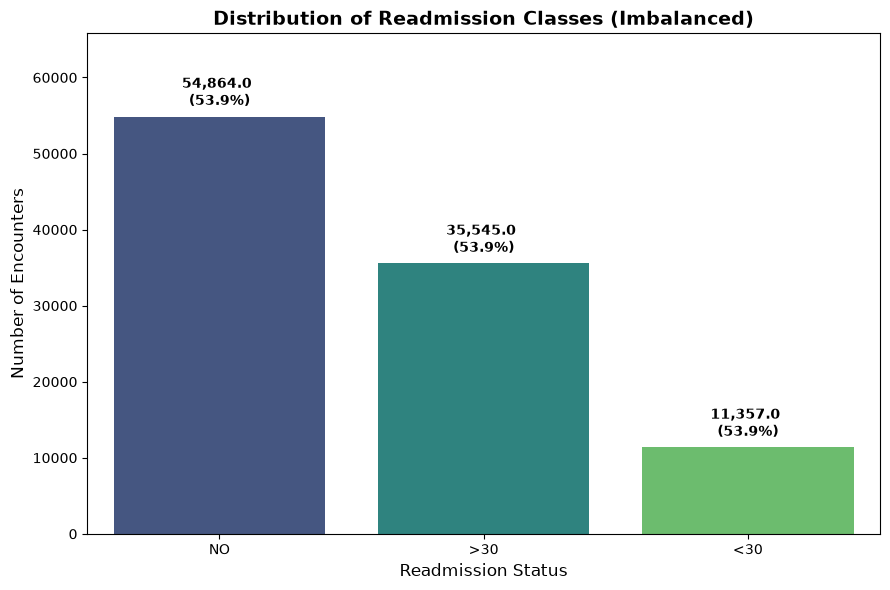

In [88]:
# Visualization
plt.figure(figsize=(9, 6))
# Use 'viridis' palette for better aesthetic, assign x to hue to avoid warnings

ax = sns.countplot(data=df, x=TARGET, order=target_counts.index, hue=TARGET, palette='viridis', legend=False)
plt.title("Distribution of Readmission Classes (Imbalanced)", fontsize=14, fontweight='bold')
plt.xlabel("Readmission Status", fontsize=12)
plt.ylabel("Number of Encounters", fontsize=12)

# Add both count and percentage labels on top of the bars
for i, container in enumerate(ax.containers):
    labels = [f'{v.get_height():,} \n({target_percentages.iloc[j]:.1f}%)' for j, v in enumerate(container)]
    ax.bar_label(container, labels=labels, padding=5, fontweight='bold')

# Expand y-axis slightly to fit the tall labels
plt.ylim(0, target_counts.max() * 1.2)
plt.tight_layout()
plt.show()

# Phase 2: Cohort Definition and Patient-Level Holdout Split

The primary analysis excludes encounters ending in death or discharge to hospice,
according to the supplied ID mapping. All other eligible encounters are retained.

The holdout split is performed by `patient_nbr` before detailed EDA. Several
Group Shuffle Split candidates are generated, and the candidate closest to the
overall class distribution is selected. This approximates stratification while
preserving complete patient separation.


In [89]:
from sklearn.model_selection import GroupShuffleSplit

DEAD_HOSPICE_IDS = {"11", "13", "14", "19", "20", "21"}

df_cohort = df.loc[
    ~df["discharge_disposition_id"].isin(DEAD_HOSPICE_IDS)
].copy()

print("Original encounters:", f"{len(df):,}")
print("Eligible encounters:", f"{len(df_cohort):,}")
print("Excluded death/hospice encounters:", f"{len(df) - len(df_cohort):,}")

overall_distribution = (
    df_cohort[TARGET].value_counts(normalize=True).reindex(CLASS_ORDER, fill_value=0)
)

splitter = GroupShuffleSplit(n_splits=20, test_size=0.20, random_state=RANDOM_STATE)
split_candidates = []
for candidate_id, (candidate_train, candidate_test) in enumerate(
    splitter.split(df_cohort, df_cohort[TARGET], groups=df_cohort["patient_nbr"])
):
    test_distribution = (
        df_cohort.iloc[candidate_test][TARGET]
        .value_counts(normalize=True)
        .reindex(CLASS_ORDER, fill_value=0)
    )
    class_gap = (test_distribution - overall_distribution).abs().sum()
    size_gap = abs(len(candidate_test) / len(df_cohort) - 0.20)
    split_candidates.append((class_gap + size_gap, candidate_id, candidate_train, candidate_test))

_, selected_candidate, train_positions, test_positions = min(
    split_candidates, key=lambda item: item[0]
)

df_train_raw = df_cohort.iloc[train_positions].copy()
df_test_raw = df_cohort.iloc[test_positions].copy()

train_patients = set(df_train_raw["patient_nbr"])
test_patients = set(df_test_raw["patient_nbr"])
patient_overlap = train_patients.intersection(test_patients)
assert not patient_overlap, "Patient leakage detected between train and test."

split_distribution = pd.concat({
    "cohort_pct": overall_distribution * 100,
    "train_pct": df_train_raw[TARGET].value_counts(normalize=True).reindex(CLASS_ORDER) * 100,
    "test_pct": df_test_raw[TARGET].value_counts(normalize=True).reindex(CLASS_ORDER) * 100,
}, axis=1)

print("Selected GroupShuffleSplit candidate:", selected_candidate)
print("Train encounters / patients:", f"{len(df_train_raw):,}", f"/ {len(train_patients):,}")
print("Test encounters / patients:", f"{len(df_test_raw):,}", f"/ {len(test_patients):,}")
print("Patient overlap:", len(patient_overlap))
display(split_distribution.round(2))

# All detailed EDA below uses only the training partition.
eda_df = df_train_raw


Original encounters: 101,766
Eligible encounters: 99,343
Excluded death/hospice encounters: 2,423
Selected GroupShuffleSplit candidate: 18
Train encounters / patients: 79,512 / 55,992
Test encounters / patients: 19,831 / 13,998
Patient overlap: 0


,cohort_pct,train_pct,test_pct
readmitted,,,
NO,52.87,52.88,52.86
>30,35.74,35.73,35.78
<30,11.39,11.40,11.36


# Phase 3: Exploratory Data Analysis on the Training Set

## 3.1 Categorical Features


In [90]:
TARGET = "readmitted"

print("=" * 60)
print("TRAINING-SET CATEGORICAL SUMMARY")
print("=" * 60)

categorical_cols = eda_df.select_dtypes(include=["object", "string"]).columns.tolist()
excluded_cols = [TARGET, "encounter_id", "patient_nbr"]
categorical_features_eda = [c for c in categorical_cols if c not in excluded_cols]

cat_summary_rows = []
for column in categorical_features_eda:
    values = eda_df[column].fillna("Missing")
    counts = values.value_counts()
    cat_summary_rows.append({
        "feature": column,
        "unique_values": values.nunique(),
        "dominant_value": counts.index[0],
        "dominant_pct": counts.iloc[0] / len(eda_df) * 100,
    })

cat_summary = pd.DataFrame(cat_summary_rows).sort_values("dominant_pct", ascending=False)
display(cat_summary.round(2))

near_constant_eda = cat_summary.query("dominant_pct > 95")
print(f"Near-constant candidates (>95% dominant): {len(near_constant_eda)}")
print("These are candidates for validation, not automatically useless features.")


TRAINING-SET CATEGORICAL SUMMARY


,feature,unique_values,dominant_value,dominant_pct
30,citoglipton,1,No,100.00
29,examide,1,No,100.00
19,acetohexamide,2,No,100.00
36,metformin-pioglitazone,2,No,100.00
34,glimepiride-pioglitazone,2,No,100.00
35,metformin-rosiglitazone,2,No,100.00
27,troglitazone,2,No,100.00
33,glipizide-metformin,2,No,99.99
22,tolbutamide,2,No,99.98
28,tolazamide,3,No,99.96


Near-constant candidates (>95% dominant): 17
These are candidates for validation, not automatically useless features.


DISTRIBUTION OF KEY CATEGORICAL FEATURES - TRAINING SET


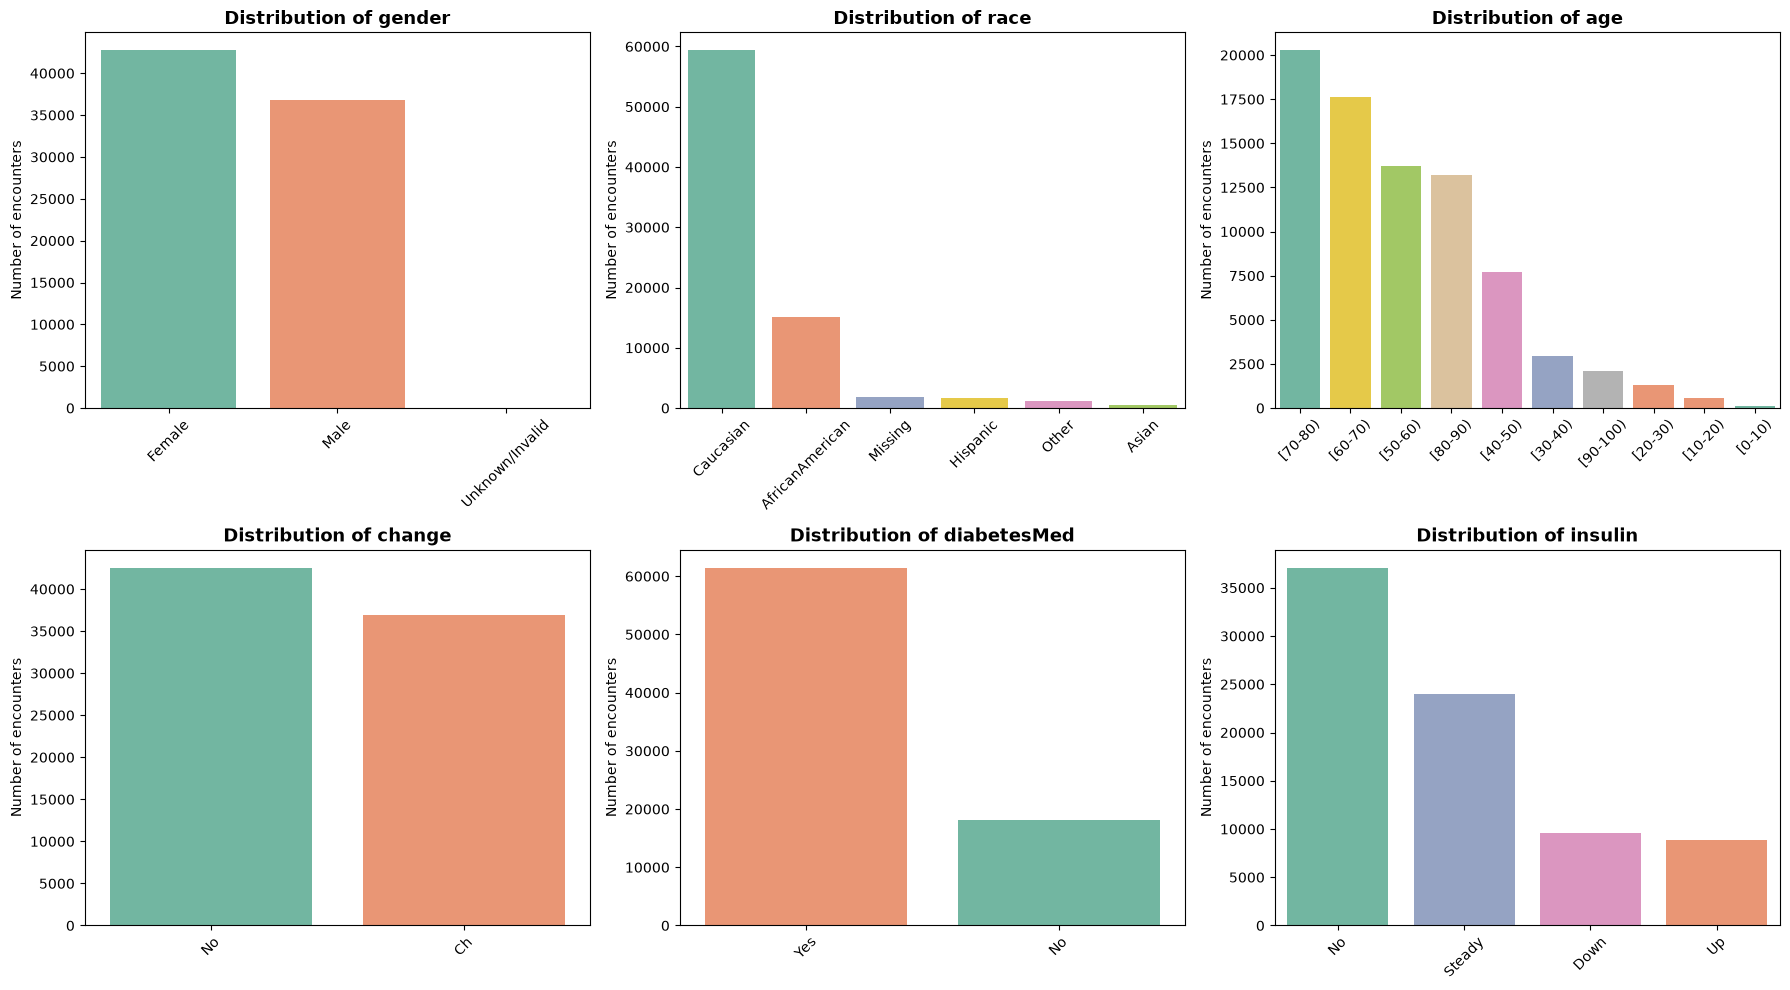

In [91]:
print("=" * 60)
print("DISTRIBUTION OF KEY CATEGORICAL FEATURES - TRAINING SET")
print("=" * 60)

key_categorical_features = ["gender", "race", "age", "change", "diabetesMed", "insulin"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for axis, column in zip(axes, key_categorical_features):
    plot_data = eda_df[column].fillna("Missing").astype(str)
    sns.countplot(
        x=plot_data,
        order=plot_data.value_counts().index,
        hue=plot_data,
        palette="Set2",
        legend=False,
        ax=axis,
    )
    axis.set_title(f"Distribution of {column}", fontsize=13, fontweight="bold")
    axis.set_xlabel("")
    axis.set_ylabel("Number of encounters")
    axis.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


## 3.2 Numerical Features and Outliers


NUMERICAL DISTRIBUTIONS AND OUTLIERS - TRAINING SET


,feature,skewness,iqr_outlier_pct,median
5,number_emergency,10.99,11.25,0.0
4,number_outpatient,8.81,16.43,0.0
6,number_inpatient,3.66,6.87,0.0
3,num_medications,1.34,2.48,15.0
2,num_procedures,1.32,4.81,1.0
0,time_in_hospital,1.14,2.14,4.0
7,number_diagnoses,-0.86,0.28,8.0
1,num_lab_procedures,-0.24,0.12,44.0


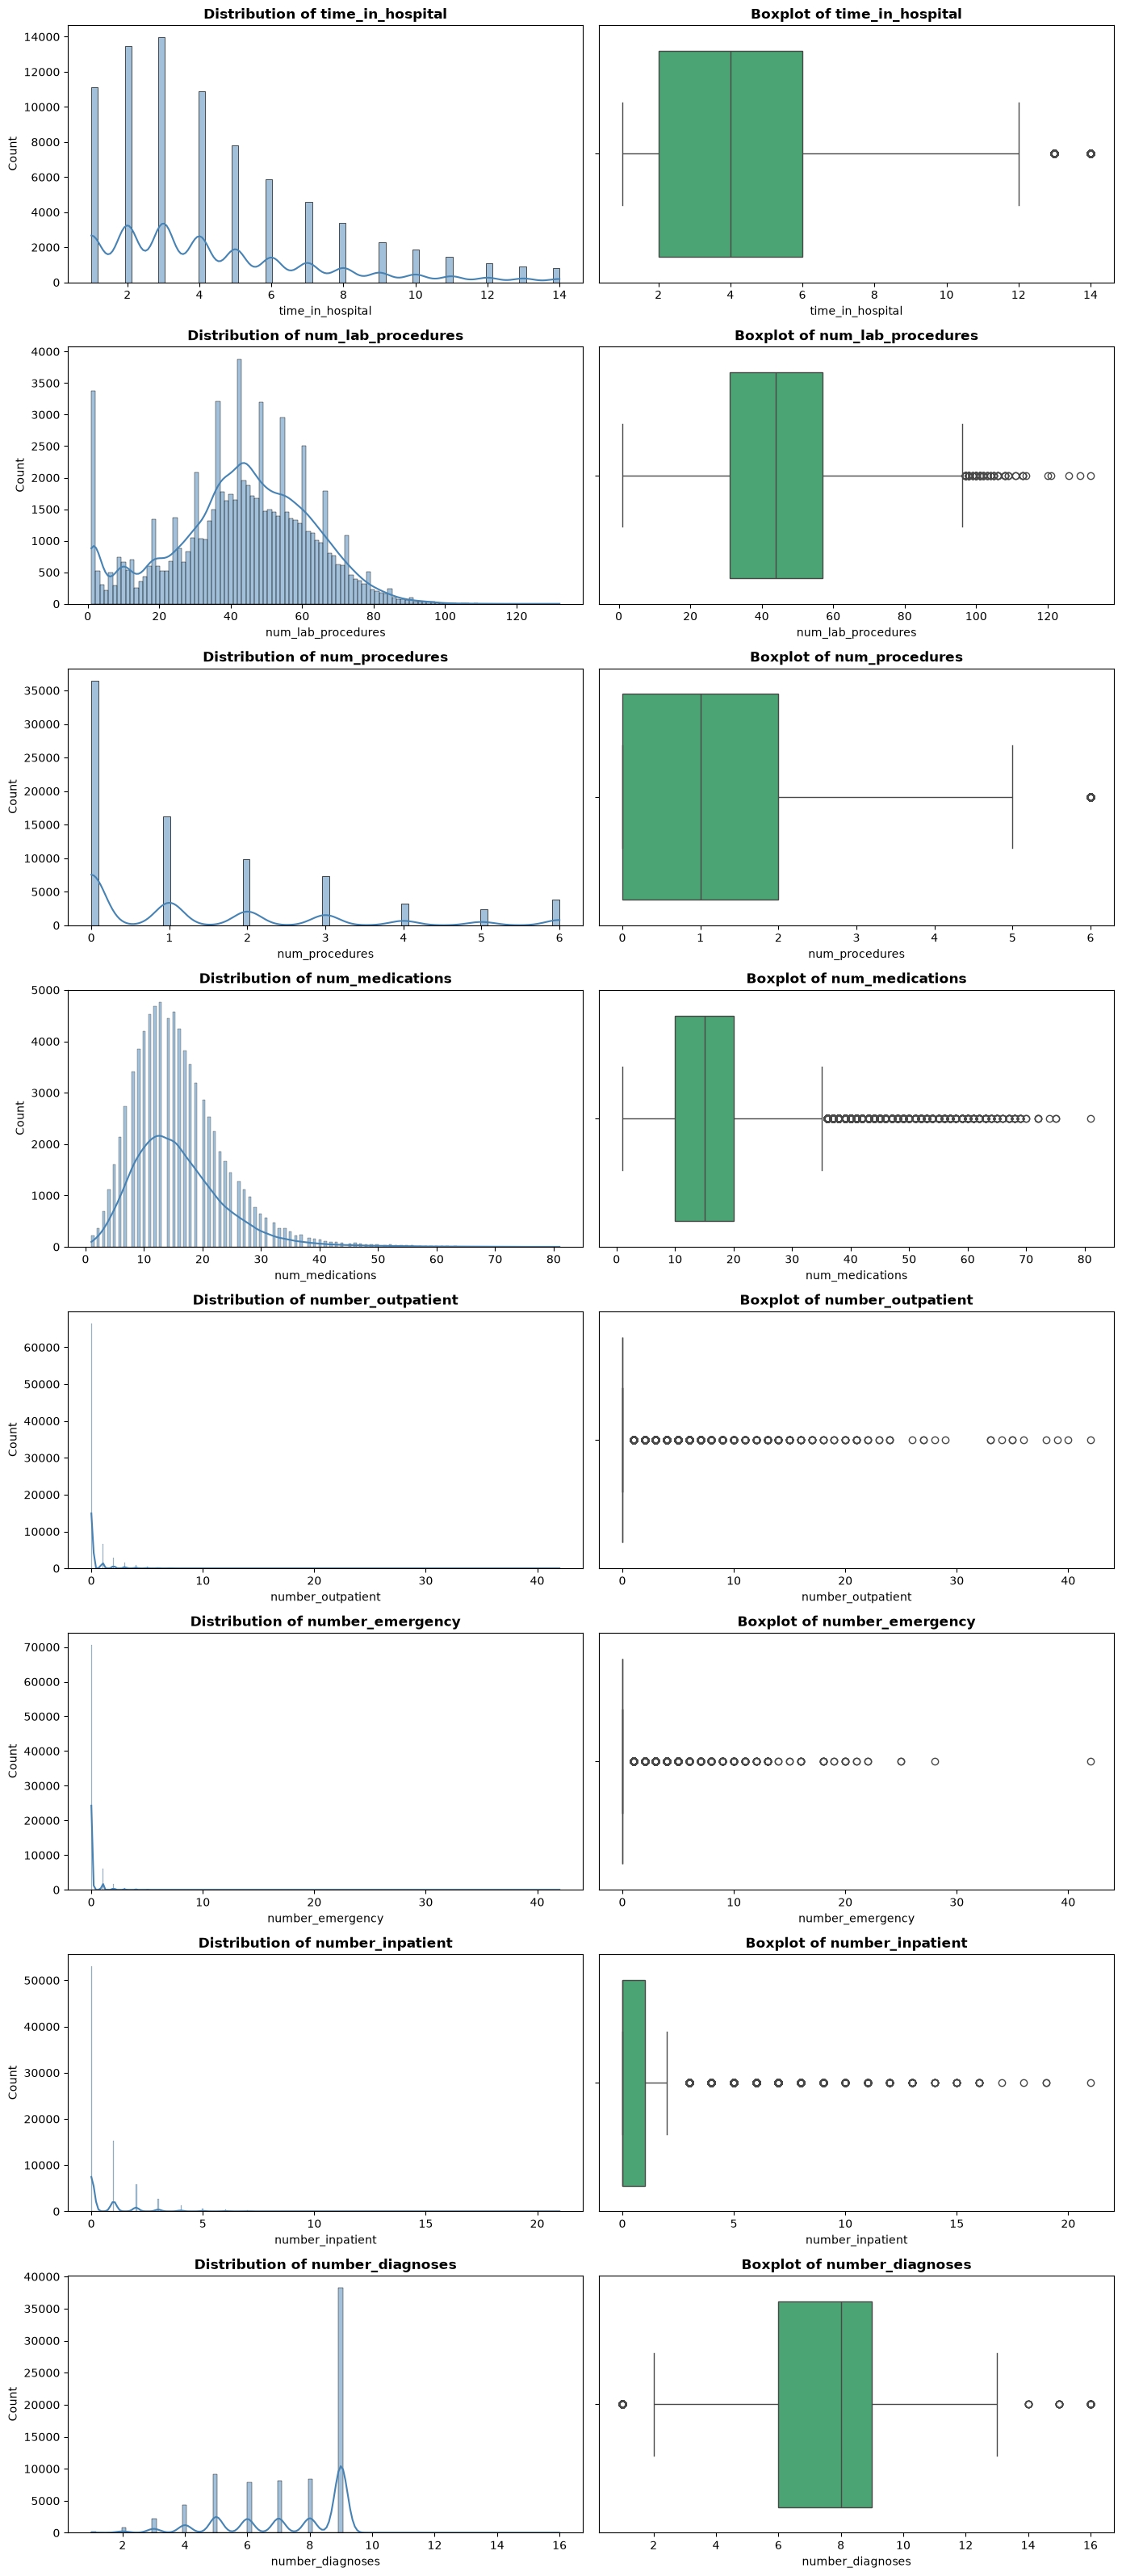

In [92]:
print("=" * 60)
print("NUMERICAL DISTRIBUTIONS AND OUTLIERS - TRAINING SET")
print("=" * 60)

numerical_cols = [
    column for column in eda_df.select_dtypes(include=["int64", "float64"]).columns
    if column != "encounter_id"
]

numeric_summary_rows = []
for column in numerical_cols:
    values = eda_df[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_mask = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
    numeric_summary_rows.append({
        "feature": column,
        "skewness": values.skew(),
        "iqr_outlier_pct": outlier_mask.mean() * 100,
        "median": values.median(),
    })

numeric_summary = pd.DataFrame(numeric_summary_rows).sort_values(
    "skewness", key=lambda series: series.abs(), ascending=False
)
display(numeric_summary.round(2))

fig, axes = plt.subplots(len(numerical_cols), 2, figsize=(14, 4 * len(numerical_cols)))
for row, column in enumerate(numerical_cols):
    sns.histplot(eda_df[column], kde=True, ax=axes[row, 0], color="steelblue")
    axes[row, 0].set_title(f"Distribution of {column}", fontweight="bold")
    sns.boxplot(x=eda_df[column], ax=axes[row, 1], color="mediumseagreen")
    axes[row, 1].set_title(f"Boxplot of {column}", fontweight="bold")

plt.tight_layout()
plt.show()


## 3.3 Numerical Correlation


NUMERICAL CORRELATION - TRAINING SET
Ten strongest pairwise correlations by absolute value:


correlation  abs_correlation
time_in_hospital   num_medications           0.465            0.465
num_procedures     num_medications           0.383            0.383
time_in_hospital   num_lab_procedures        0.319            0.319
number_emergency   number_inpatient          0.297            0.297
num_lab_procedures num_medications           0.267            0.267
num_medications    number_diagnoses          0.261            0.261
time_in_hospital   number_diagnoses          0.220            0.220
                   num_procedures            0.191            0.191
num_lab_procedures number_diagnoses          0.152            0.152
number_outpatient  number_inpatient          0.108            0.108

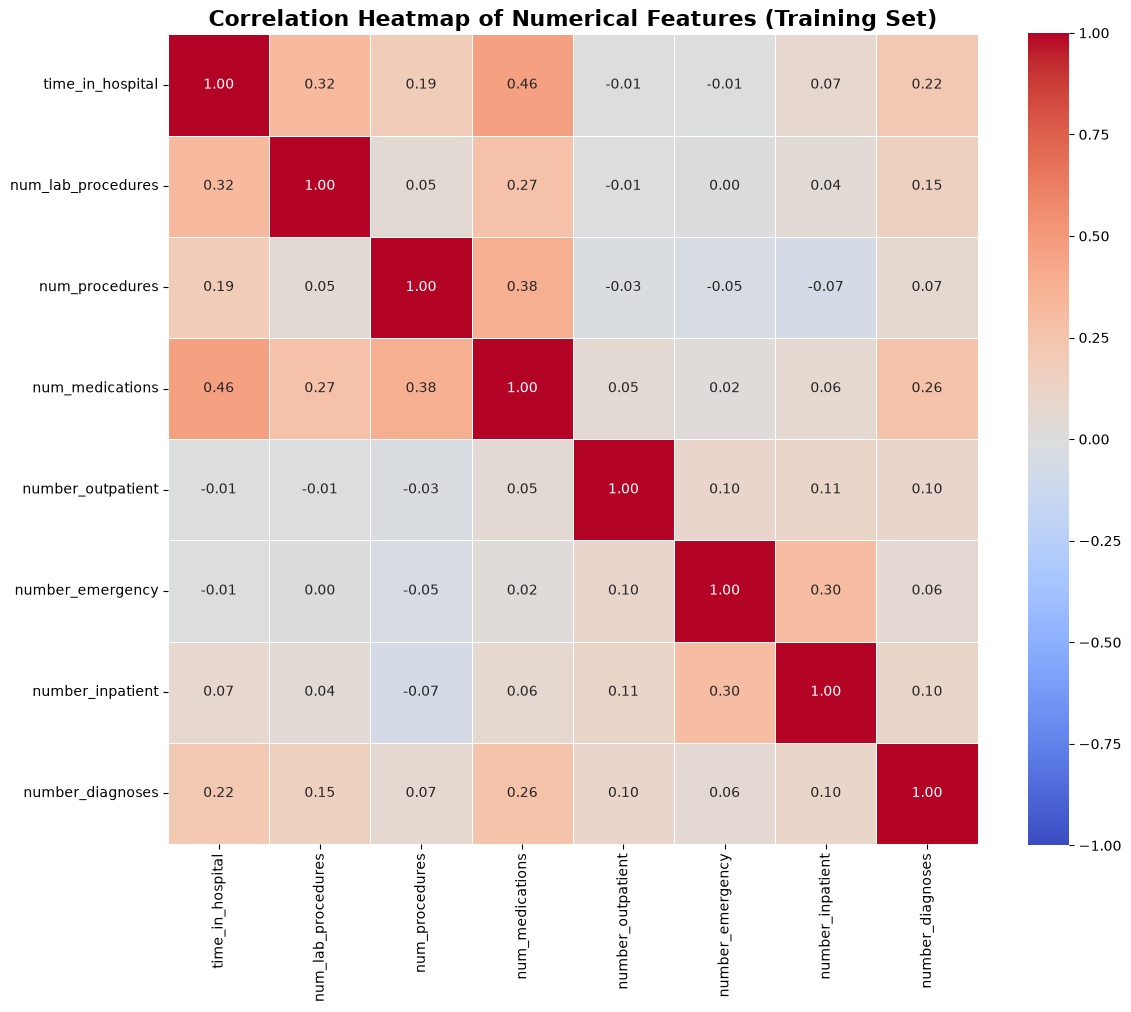

In [93]:
print("=" * 60)
print("NUMERICAL CORRELATION - TRAINING SET")
print("=" * 60)

corr_matrix = eda_df[numerical_cols].corr()
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
top_correlations = (
    upper_triangle.stack()
    .rename("correlation")
    .to_frame()
    .assign(abs_correlation=lambda table: table["correlation"].abs())
    .sort_values("abs_correlation", ascending=False)
    .head(10)
)

print("Ten strongest pairwise correlations by absolute value:")
display(top_correlations.round(3))

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
)
plt.title("Correlation Heatmap of Numerical Features (Training Set)", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()


BIVARIATE ANALYSIS - TRAINING SET
Time in hospital by target class:


,count,mean,median,std
readmitted,,,,
NO,42044,4.22,3.0,2.93
>30,28406,4.49,4.0,2.99
<30,9062,4.78,4.0,3.04


Target percentages within each age group:


readmitted,NO,>30,<30
age,,,
[0-10),82.58,15.15,2.27
[10-20),60.61,32.91,6.47
[20-30),55.17,30.40,14.44
[30-40),57.97,31.30,10.73
[40-50),55.10,34.28,10.61
[50-60),55.61,34.69,9.70
[60-70),53.06,35.83,11.11
[70-80),50.61,37.20,12.19
[80-90),49.28,37.86,12.86


Target percentages within each gender group:


...

readmitted,NO,>30,<30
race,,,
AfricanAmerican,53.14,35.31,11.55
Asian,63.94,25.16,10.90
Caucasian,52.01,36.46,11.53
Hispanic,57.24,32.37,10.39
Missing,67.81,24.12,8.08
Other,60.03,30.61,9.36


Target percentages within each insulin group:


readmitted,NO,>30,<30
insulin,,,
Down,46.45,39.22,14.34
No,55.43,34.43,10.13
Steady,53.83,34.84,11.33
Up,46.56,39.75,13.69


Target percentages within each A1Cresult group:


readmitted,NO,>30,<30
A1Cresult,,,
>7,55.57,34.06,10.38
>8,54.50,35.75,9.75
Norm,58.13,31.94,9.93
NotMeasured,52.28,36.03,11.70


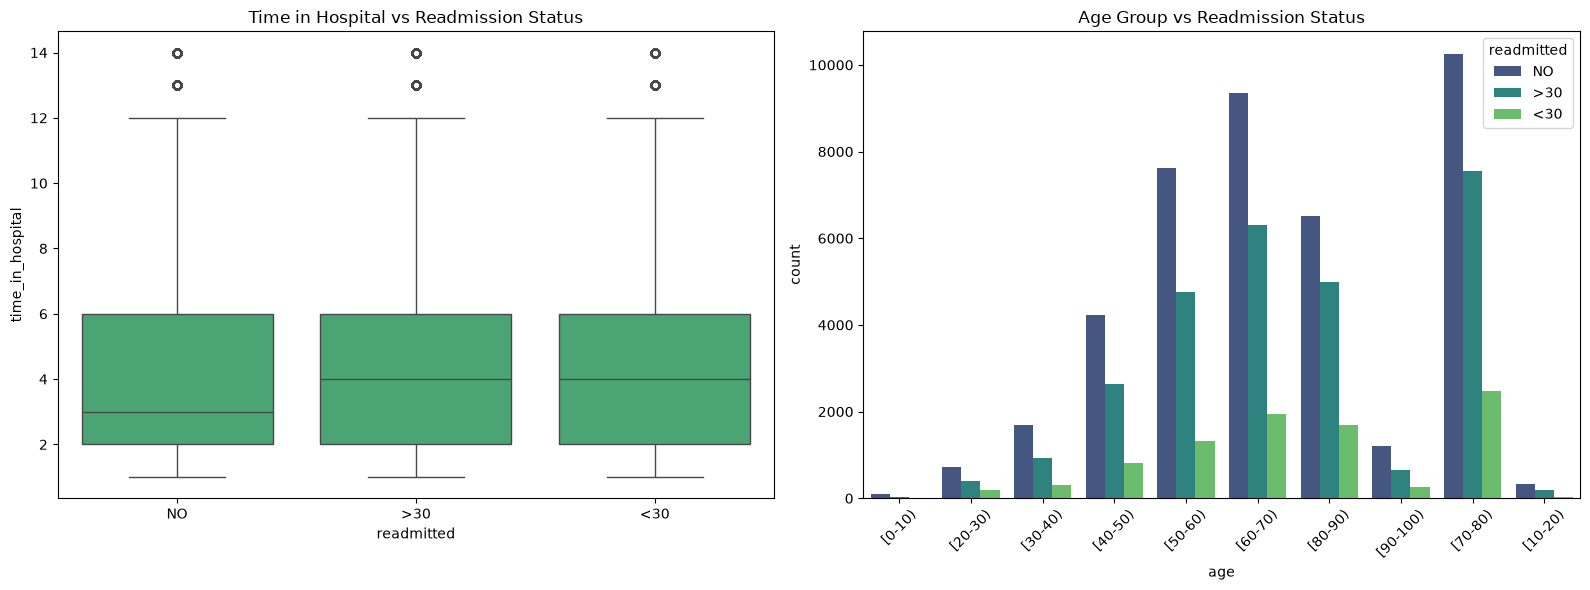

In [94]:
print("=" * 60)
print("BIVARIATE ANALYSIS - TRAINING SET")
print("=" * 60)

time_summary = eda_df.groupby(TARGET, observed=False)["time_in_hospital"].agg(
    count="size", mean="mean", median="median", std="std"
).reindex(CLASS_ORDER)
print("Time in hospital by target class:")
display(time_summary.round(2))

def target_rate_table(data, feature):
    values = data[feature].fillna("Missing")
    table = pd.crosstab(values, data[TARGET], normalize="index")
    return (table.reindex(columns=CLASS_ORDER, fill_value=0) * 100).round(2)

for feature in ["age", "gender", "race", "insulin", "A1Cresult"]:
    print(f"Target percentages within each {feature} group:")
    display(target_rate_table(eda_df, feature))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=eda_df, x=TARGET, y="time_in_hospital", order=CLASS_ORDER,
            color="mediumseagreen", ax=axes[0])
axes[0].set_title("Time in Hospital vs Readmission Status")

sns.countplot(data=eda_df, x="age", hue=TARGET, hue_order=CLASS_ORDER,
              palette="viridis", ax=axes[1])
axes[1].set_title("Age Group vs Readmission Status")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


## 3.5 EDA Summary and Decisions

### Finding 1 - The target is meaningfully, but not extremely, imbalanced

`<30` is the smallest and most operationally important class. Class proportions are
reported for the full cohort and both patient-disjoint splits.

**Interpretation:** Accuracy alone can hide poor detection of early readmission.

**Action:** Report macro-F1, weighted-F1, the confusion matrix, and precision/recall/F1
for `<30`. Multiclass ROC-AUC or PR-AUC must state the One-vs-Rest and averaging scheme.

### Finding 2 - Repeated patients create a leakage risk, not automatic leakage

Multiple encounters from one patient are valid observations. Leakage occurs if the
same patient is present in both training and test data.

**Action:** Retain all eligible encounters and split by `patient_nbr`. Keep patient IDs
only for grouping; never expose them to the model. Use group-aware cross-validation.

### Finding 3 - Missingness and non-measurement are not always equivalent

`weight` has very little observed information. `max_glu_serum` and `A1Cresult` are often
not measured, which may describe the care process rather than a recording error.

**Action:** Drop `weight`, preserve `NotMeasured` as an explicit laboratory state, and
impute genuinely missing categorical values inside the training pipeline.

### Finding 4 - Low variance does not prove that a feature has no signal

Some medication columns are constant or nearly constant. Rare values can still be
associated with the rare `<30` outcome.

**Action:** Drop only zero-variance columns by default. Treat near-constant columns as
experiment candidates and compare model performance before removing them.

### Finding 5 - Prediction time determines whether a feature is valid

This notebook assumes prediction at discharge, so information available by discharge
may be used. In an admission-time deployment, fields such as
`discharge_disposition_id` would be future information and must be removed.

### Finding 6 - Visual counts must be separated from within-group risk

Large groups naturally produce more readmissions in count plots.

**Action:** Use within-group target percentages, sample sizes, numerical summaries,
and correlation tables alongside visualizations. Differences observed in EDA are
descriptive and are not evidence of causality.


# Phase 4: Data Preprocessing

The held-out test set was created before detailed EDA. Deterministic cleaning rules
are now applied consistently to the training and test frames. All data-dependent
operations, including imputation, rare-category grouping, scaling, feature selection,
and PCA, are fitted using training data only.


## 4.1 Initialize the Patient-Disjoint Splits


In [95]:
print("=" * 60)
print("INITIALIZE CLEAN TRAIN AND TEST FRAMES")
print("=" * 60)

df_train_clean = df_train_raw.copy()
df_test_clean = df_test_raw.copy()

print(f"Training encounters: {len(df_train_clean):,}")
print(f"Test encounters: {len(df_test_clean):,}")
print("Repeated encounters are retained; patient groups remain disjoint.")


INITIALIZE CLEAN TRAIN AND TEST FRAMES
Training encounters: 79,512
Test encounters: 19,831
Repeated encounters are retained; patient groups remain disjoint.


## 4.2 Remove Non-Predictive and Unusable Columns


In [96]:
print("=" * 60)
print("DROP NON-PREDICTIVE AND HEAVILY MISSING COLUMNS")
print("=" * 60)

# patient_nbr is deliberately retained until X/y/groups are separated.
columns_to_drop = ["encounter_id", "weight"]
df_train_clean = df_train_clean.drop(columns=columns_to_drop, errors="ignore")
df_test_clean = df_test_clean.drop(columns=columns_to_drop, errors="ignore")

print("Dropped from both splits:", columns_to_drop)
print("patient_nbr retained temporarily for grouped validation.")
print("Train shape:", df_train_clean.shape)
print("Test shape:", df_test_clean.shape)


DROP NON-PREDICTIVE AND HEAVILY MISSING COLUMNS
Dropped from both splits: ['encounter_id', 'weight']
patient_nbr retained temporarily for grouped validation.
Train shape: (79512, 48)
Test shape: (19831, 48)


In [97]:
print("=" * 60)
print("LOW-VARIANCE AUDIT ON TRAINING DATA")
print("=" * 60)

audit_features = [
    column for column in df_train_clean.columns
    if column not in {TARGET, "patient_nbr"}
]

variance_audit_rows = []
for column in audit_features:
    counts = df_train_clean[column].value_counts(dropna=False)
    variance_audit_rows.append({
        "feature": column,
        "unique_values": df_train_clean[column].nunique(dropna=False),
        "dominant_pct": counts.iloc[0] / len(df_train_clean) * 100,
    })

variance_audit = pd.DataFrame(variance_audit_rows).sort_values("dominant_pct", ascending=False)
constant_candidates = variance_audit.query("unique_values <= 1")["feature"].tolist()
near_constant_candidates = variance_audit.query(
    "unique_values > 1 and dominant_pct > 95"
)["feature"].tolist()

display(variance_audit.head(25).round(2))
print("Zero-variance columns to drop:", constant_candidates)
print("Near-constant columns retained for comparison:", near_constant_candidates)


LOW-VARIANCE AUDIT ON TRAINING DATA


,feature,unique_values,dominant_pct
36,examide,1,100.00
37,citoglipton,1,100.00
43,metformin-pioglitazone,2,100.00
26,acetohexamide,2,100.00
41,glimepiride-pioglitazone,2,100.00
42,metformin-rosiglitazone,2,100.00
34,troglitazone,2,100.00
40,glipizide-metformin,2,99.99
29,tolbutamide,2,99.98
35,tolazamide,3,99.96


Zero-variance columns to drop: ['examide', 'citoglipton']
Near-constant columns retained for comparison: ['metformin-pioglitazone', 'acetohexamide', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'troglitazone', 'glipizide-metformin', 'tolbutamide', 'tolazamide', 'miglitol', 'chlorpropamide', 'acarbose', 'nateglinide', 'glyburide-metformin', 'repaglinide']


In [98]:
print("=" * 60)
print("CURRENT STATE BEFORE MISSING-CODE STANDARDIZATION")
print("=" * 60)

print(f"Training data: {df_train_clean.shape[0]:,} rows, {df_train_clean.shape[1]} columns")
print(f"Test data:     {df_test_clean.shape[0]:,} rows, {df_test_clean.shape[1]} columns")

train_missing = pd.DataFrame({
    "missing_count": df_train_clean.isna().sum(),
    "missing_pct": df_train_clean.isna().mean() * 100,
}).query("missing_count > 0").sort_values("missing_pct", ascending=False)

display(train_missing.round(2))


CURRENT STATE BEFORE MISSING-CODE STANDARDIZATION
Training data: 79,512 rows, 48 columns
Test data:     19,831 rows, 48 columns


,missing_count,missing_pct
medical_specialty,38745,48.73
payer_code,31438,39.54
race,1808,2.27
diag_3,1129,1.42
diag_2,295,0.37
diag_1,17,0.02


## 4.3 Standardize Hidden Missing Codes


In [99]:
print("STANDARDIZING HIDDEN MISSING CODES")

invalid_code_map = {
    "admission_type_id": ["5", "6", "8"],
    "discharge_disposition_id": ["18", "25", "26"],
    "admission_source_id": ["9", "15", "17", "20", "21"],
}

def standardize_hidden_missing(frame):
    result = frame.copy()
    for column, invalid_codes in invalid_code_map.items():
        result[column] = result[column].replace(invalid_codes, np.nan)
    return result

df_train_clean = standardize_hidden_missing(df_train_clean)
df_test_clean = standardize_hidden_missing(df_test_clean)


STANDARDIZING HIDDEN MISSING CODES


In [100]:
missing_summary = pd.DataFrame({
    "missing_count": df_train_clean.isna().sum(),
    "missing_pct": df_train_clean.isna().mean() * 100,
}).query("missing_count > 0").sort_values("missing_pct", ascending=False)

print("Training-set missing values after hidden-code standardization:")
display(missing_summary.round(2))

print("Laboratory states are retained separately from genuine missing values:")
display(pd.DataFrame({
    "not_measured_pct": [df_train_clean[c].eq("NotMeasured").mean() * 100 for c in LAB_COLS],
    "missing_pct": [df_train_clean[c].isna().mean() * 100 for c in LAB_COLS],
}, index=LAB_COLS).round(2))

print("No imputer is fitted here; imputation remains inside the sklearn pipeline.")


Training-set missing values after hidden-code standardization:


,missing_count,missing_pct
medical_specialty,38745,48.73
payer_code,31438,39.54
admission_type_id,8099,10.19
admission_source_id,5446,6.85
discharge_disposition_id,3741,4.70
race,1808,2.27
diag_3,1129,1.42
diag_2,295,0.37
diag_1,17,0.02


Laboratory states are retained separately from genuine missing values:


,not_measured_pct,missing_pct
max_glu_serum,94.79,0.0
A1Cresult,82.93,0.0


No imputer is fitted here; imputation remains inside the sklearn pipeline.


## 4.4 Feature Engineering: Age and ICD-9


In [101]:
print("=" * 60)
print("CONFIGURABLE FEATURE ENGINEERING")
print("=" * 60)

AGE_ENCODING = "onehot"  # Alternative experiment: "midpoint"

age_mapping = {
    "[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35,
    "[40-50)": 45, "[50-60)": 55, "[60-70)": 65, "[70-80)": 75,
    "[80-90)": 85, "[90-100)": 95,
}

def map_icd9_to_category(value):
    if pd.isna(value):
        return np.nan

    code = str(value).upper()
    if code.startswith("250"):
        return "Diabetes"
    if code.startswith(("V", "E")):
        return "Supplemental"

    try:
        number = float(code)
    except ValueError:
        return "Other"

    if 390 <= number <= 459 or number == 785:
        return "Circulatory"
    if 460 <= number <= 519 or number == 786:
        return "Respiratory"
    if 520 <= number <= 579 or number == 787:
        return "Digestive"
    if 800 <= number <= 999:
        return "Injury"
    if 710 <= number <= 739:
        return "Musculoskeletal"
    if 580 <= number <= 629 or number == 788:
        return "Genitourinary"
    if 140 <= number <= 239:
        return "Neoplasms"
    return "Other"

def apply_feature_engineering(frame, age_encoding=AGE_ENCODING):
    result = frame.copy()
    if age_encoding == "midpoint":
        result["age"] = result["age"].map(age_mapping)
    elif age_encoding != "onehot":
        raise ValueError("age_encoding must be 'onehot' or 'midpoint'")

    for column in DIAG_COLS:
        result[column] = result[column].map(map_icd9_to_category)
    return result

df_train_clean = apply_feature_engineering(df_train_clean)
df_test_clean = apply_feature_engineering(df_test_clean)

print("Age representation:", AGE_ENCODING)
print("ICD-9 codes mapped to 10 categories, including Supplemental and Other.")
display(df_train_clean["diag_1"].value_counts(dropna=False).to_frame("train_count"))


CONFIGURABLE FEATURE ENGINEERING
Age representation: onehot
ICD-9 codes mapped to 10 categories, including Supplemental and Other.


,train_count
diag_1,
Circulatory,23797
Other,12905
Respiratory,11166
Digestive,7416
Diabetes,6958
Injury,5474
Genitourinary,4020
Musculoskeletal,3946
Neoplasms,2527


## 4.5 Target Encoding and Final Feature Matrices


In [102]:
print("=" * 60)
print("TARGET ENCODING AND GROUP EXTRACTION")
print("=" * 60)

target_mapping = {"NO": 0, ">30": 1, "<30": 2}
target_names = {value: key for key, value in target_mapping.items()}

groups_train = df_train_clean.pop("patient_nbr")
groups_test = df_test_clean.pop("patient_nbr")

y_train = df_train_clean.pop(TARGET).map(target_mapping)
y_test = df_test_clean.pop(TARGET).map(target_mapping)
X_train = df_train_clean.copy()
X_test = df_test_clean.copy()

assert y_train.notna().all() and y_test.notna().all()
assert set(groups_train).isdisjoint(set(groups_test))

print("Target labels are class identifiers: NO=0, >30=1, <30=2")
print("Train shapes:", X_train.shape, y_train.shape)
print("Test shapes:", X_test.shape, y_test.shape)


TARGET ENCODING AND GROUP EXTRACTION
Target labels are class identifiers: NO=0, >30=1, <30=2
Train shapes: (79512, 46) (79512,)
Test shapes: (19831, 46) (19831,)


In [103]:
from sklearn.model_selection import StratifiedGroupKFold

print("=" * 60)
print("TRAIN-ONLY FEATURE FILTER AND GROUPED CROSS-VALIDATION")
print("=" * 60)

dominance = {
    column: X_train[column].value_counts(dropna=False).iloc[0] / len(X_train)
    for column in X_train.columns
}
constant_train_cols = [
    column for column in X_train.columns
    if X_train[column].nunique(dropna=False) <= 1
]
near_constant_train_cols = [
    column for column, ratio in dominance.items()
    if ratio > 0.95 and column not in constant_train_cols
]

# Default: remove only true constants. Near-constant features remain available
# for an explicit ablation experiment instead of being assumed useless.
DROP_NEAR_CONSTANT = False
columns_to_remove = constant_train_cols + (
    near_constant_train_cols if DROP_NEAR_CONSTANT else []
)

X_train = X_train.drop(columns=columns_to_remove)
X_test = X_test.drop(columns=columns_to_remove)

group_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Dropped zero-variance columns:", constant_train_cols)
print("Retained near-constant candidates:", near_constant_train_cols)
print("Group CV:", group_cv)
print("Final raw feature shapes:", X_train.shape, X_test.shape)


TRAIN-ONLY FEATURE FILTER AND GROUPED CROSS-VALIDATION
Dropped zero-variance columns: ['examide', 'citoglipton']
Retained near-constant candidates: ['repaglinide', 'nateglinide', 'chlorpropamide', 'acetohexamide', 'tolbutamide', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']
Group CV: StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True)
Final raw feature shapes: (79512, 44) (19831, 44)


## 4.6 Configurable Preprocessing Pipeline


### 4.6.1 Numerical and Categorical Feature Groups


In [104]:
print("=" * 60)
print("DEFINE FEATURE GROUPS")
print("=" * 60)

numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

assert set(numerical_features).isdisjoint(categorical_features)
assert set(numerical_features + categorical_features) == set(X_train.columns)

print(f"Numerical features ({len(numerical_features)}):")
print(numerical_features)
print(f"Categorical features ({len(categorical_features)}):")
print(categorical_features)


DEFINE FEATURE GROUPS
Numerical features (8):
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
Categorical features (36):
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


In [105]:
from modules.preprocessing import get_preprocessor

print("=" * 60)
print("BUILD CONFIGURABLE PREPROCESSOR")
print("=" * 60)

print("Available scaler options: standard, robust, minmax, none")
print("Rare categories are grouped using training-set frequency only.")


BUILD CONFIGURABLE PREPROCESSOR
Available scaler options: standard, robust, minmax, none
Rare categories are grouped using training-set frequency only.


In [106]:
print("=" * 60)
print("VALIDATE THE PREPROCESSOR")
print("=" * 60)

test_preprocessor = get_preprocessor(
    numerical_features=numerical_features,
    categorical_features=categorical_features,
    scaler_type="standard",
    log_numeric=False,
    min_category_frequency=20,
)

X_train_processed = test_preprocessor.fit_transform(X_train)
X_test_processed = test_preprocessor.transform(X_test)

assert X_train_processed.shape[1] == X_test_processed.shape[1]
assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_test_processed).all()

print("Original train shape:", X_train.shape)
print("Processed train shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)
print("No non-finite values remain after preprocessing.")


VALIDATE THE PREPROCESSOR
Original train shape: (79512, 44)
Processed train shape: (79512, 226)
Processed test shape: (19831, 226)
No non-finite values remain after preprocessing.


# Phase 5: Feature Extraction and Dimensionality Reduction

PCA is treated as an experimental representation, not a mandatory preprocessing
step. Downstream models should compare no PCA, 90% explained variance, and 95%
explained variance under the same grouped cross-validation procedure.


In [107]:
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

print("=" * 60)
print("PCA EXPLAINED VARIANCE - TRAINING DATA ONLY")
print("=" * 60)

preprocessor_pca = get_preprocessor(
    numerical_features=numerical_features,
    categorical_features=categorical_features,
    scaler_type="standard",
    log_numeric=False,
    min_category_frequency=20,
)
X_train_pca_ready = preprocessor_pca.fit_transform(X_train)
X_test_pca_ready = preprocessor_pca.transform(X_test)

pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train_pca_ready)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
threshold_90 = np.argmax(cumulative_variance >= 0.90) + 1
threshold_95 = np.argmax(cumulative_variance >= 0.95) + 1


PCA EXPLAINED VARIANCE - TRAINING DATA ONLY


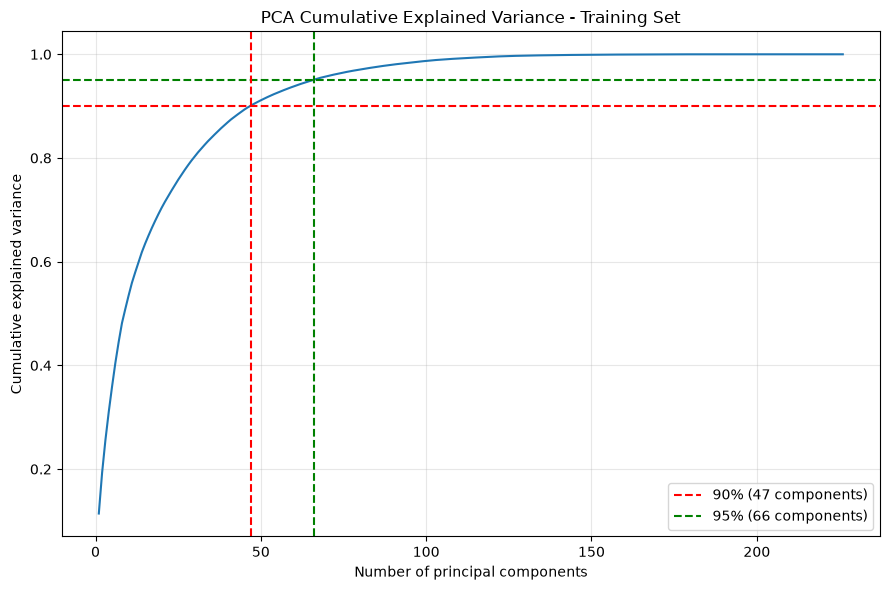

Encoded feature count: 226
Components for 90% variance: 47
Components for 95% variance: 66
Feature pipelines prepared for downstream grouped model comparison.


In [108]:
plt.figure(figsize=(9, 6))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance)
plt.axhline(0.90, color="red", linestyle="--", label=f"90% ({threshold_90} components)")
plt.axhline(0.95, color="green", linestyle="--", label=f"95% ({threshold_95} components)")
plt.axvline(threshold_90, color="red", linestyle="--")
plt.axvline(threshold_95, color="green", linestyle="--")
plt.title("PCA Cumulative Explained Variance - Training Set")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Encoded feature count:", X_train_pca_ready.shape[1])
print("Components for 90% variance:", threshold_90)
print("Components for 95% variance:", threshold_95)

def get_feature_pipeline(pca_variance=None, **preprocessor_options):
    """Create a comparable feature pipeline with optional train-fitted PCA."""
    steps = [("preprocessor", get_preprocessor(
        numerical_features=numerical_features,
        categorical_features=categorical_features,
        **preprocessor_options,
    ))]
    if pca_variance is not None:
        if pca_variance not in (0.90, 0.95):
            raise ValueError("pca_variance must be None, 0.90, or 0.95")
        steps.append(("pca", PCA(n_components=pca_variance, svd_solver="full")))
    return Pipeline(steps)

feature_pipeline_no_pca = get_feature_pipeline(pca_variance=None)
feature_pipeline_pca_90 = get_feature_pipeline(pca_variance=0.90)
feature_pipeline_pca_95 = get_feature_pipeline(pca_variance=0.95)

print("Feature pipelines prepared for downstream grouped model comparison.")


## Phase 5.1: Export Extracted Feature Matrices (.npy)

Preprocessed feature representations and dimensionality-reduced feature matrices
are saved in `.npy` format inside the `features/` directory.

These exported matrices serve as standardized, leakage-free representations
available for **all downstream traditional classifiers** (SVM, Logistic Regression,
Random Forest) as well as the Deep Learning pipeline extension:

- `X_train_processed.npy` & `X_test_processed.npy`: Full dense preprocessed feature space (226 encoded features).
- `X_train_pca90.npy` & `X_test_pca90.npy`: Feature space projected onto components retaining 90% cumulative variance.
- `X_train_pca95.npy` & `X_test_pca95.npy`: Feature space projected onto components retaining 95% cumulative variance.
- `y_train.npy` & `y_test.npy`: Target labels (NO=0, >30=1, <30=2).
- `feature_names.json`: Feature column names corresponding to the encoded dimensions for model interpretability.

In [109]:
import json as _json

print("=" * 60)
print("PHASE 5.1: EXPORT EXTRACTED FEATURE MATRICES (.npy)")
print("=" * 60)

# Ensure FEATURES_DIR exists
FEATURES_DIR.mkdir(parents=True, exist_ok=True)

# 1. Transform full train and test sets using the fitted baseline preprocessor
#    (StandardScaler + OneHotEncoder with min_category_frequency=20)
#    Re-use same configuration as the PCA analysis above.
preprocessor_export = get_preprocessor(
    numerical_features=numerical_features,
    categorical_features=categorical_features,
    scaler_type="standard",
    log_numeric=False,
    min_category_frequency=20,
)
X_train_export = preprocessor_export.fit_transform(X_train).astype(np.float32)
X_test_export = preprocessor_export.transform(X_test).astype(np.float32)

# Extract column names after one-hot encoding
feature_names_out = list(preprocessor_export.get_feature_names_out())

# 2. PCA projections (90% and 95% variance)
pca_90_export = PCA(n_components=0.90, svd_solver="full", random_state=RANDOM_STATE)
X_train_pca90 = pca_90_export.fit_transform(X_train_export).astype(np.float32)
X_test_pca90 = pca_90_export.transform(X_test_export).astype(np.float32)

pca_95_export = PCA(n_components=0.95, svd_solver="full", random_state=RANDOM_STATE)
X_train_pca95 = pca_95_export.fit_transform(X_train_export).astype(np.float32)
X_test_pca95 = pca_95_export.transform(X_test_export).astype(np.float32)

y_train_arr = np.asarray(y_train, dtype=np.int64)
y_test_arr = np.asarray(y_test, dtype=np.int64)

# 3. Save all artifacts to FEATURES_DIR
feature_artifacts = {
    "X_train_processed.npy": X_train_export,
    "X_test_processed.npy": X_test_export,
    "X_train_pca90.npy": X_train_pca90,
    "X_test_pca90.npy": X_test_pca90,
    "X_train_pca95.npy": X_train_pca95,
    "X_test_pca95.npy": X_test_pca95,
    "y_train.npy": y_train_arr,
    "y_test.npy": y_test_arr,
    "groups_train.npy": np.asarray(groups_train, dtype=np.int64),
    "groups_test.npy": np.asarray(groups_test, dtype=np.int64),
}

for fname, arr in feature_artifacts.items():
    fpath = FEATURES_DIR / fname
    np.save(fpath, arr)
    print(f"  Saved {fname:30s} shape={str(arr.shape):15s} dtype={arr.dtype}")

# 4. Save feature names for interpretability
feature_names_path = FEATURES_DIR / "feature_names.json"
with open(feature_names_path, "w", encoding="utf-8") as f:
    _json.dump(feature_names_out, f, ensure_ascii=False, indent=2)
print(f"  Saved feature_names.json ({len(feature_names_out)} features)")

print()
print("All feature matrices exported to:", FEATURES_DIR)


PHASE 5.1: EXPORT EXTRACTED FEATURE MATRICES (.npy)
  Saved X_train_processed.npy          shape=(79512, 226)    dtype=float32
  Saved X_test_processed.npy           shape=(19831, 226)    dtype=float32
  Saved X_train_pca90.npy              shape=(79512, 47)     dtype=float32
  Saved X_test_pca90.npy               shape=(19831, 47)     dtype=float32
  Saved X_train_pca95.npy              shape=(79512, 66)     dtype=float32
  Saved X_test_pca95.npy               shape=(19831, 66)     dtype=float32
  Saved y_train.npy                    shape=(79512,)        dtype=int64
  Saved y_test.npy                     shape=(19831,)        dtype=int64
  Saved feature_names.json (226 features)

All feature matrices exported to: D:\HCMUT\5th_Semester\ML\Assignment\features


# Phase 6: Model Training and Evaluation

## 6.1: Support Vector Machine Training and Evaluation

This section trains and evaluates a Support Vector Machine classifier using the
patient-disjoint training and test sets prepared in the previous phases.

Model selection is performed exclusively on the training set using
StratifiedGroupKFold so that encounters from the same patient remain within the
same fold.

Because the dataset contains nearly 80,000 training encounters, LinearSVC is
used as the primary SVM implementation. This provides a computationally
practical maximum-margin classifier for the high-dimensional one-hot encoded
feature space.

The experiments compare:

- numerical scaling strategies;
- class weighting;
- PCA representations;
- regularization strength C.

Macro-F1 is used as the primary model-selection metric because the target is
imbalanced and the `<30` readmission class is the minority class.

The held-out test set is used only once after model selection.

In [110]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
    average_precision_score,
)
from sklearn.preprocessing import label_binarize
from sklearn.dummy import DummyClassifier

from modules.evaluation import evaluate_classifier
from modules.svm_model import (
    build_linear_svm_pipeline,
    run_svm_cross_validation,
)

print("=" * 60)
print("SVM EXPERIMENT SETUP")
print("=" * 60)

LABELS = [0, 1, 2]
CLASS_NAMES = [target_names[label] for label in LABELS]

print("Class mapping:")
for label, name in zip(LABELS, CLASS_NAMES):
    print(f"  {label}: {name}")

print("\nPrimary selection metric: Macro-F1")
print("Cross-validation:", group_cv)

SVM EXPERIMENT SETUP
Class mapping:
  0: NO
  1: >30
  2: <30

Primary selection metric: Macro-F1
Cross-validation: StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True)


In [111]:
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted",
}

print("Evaluation metrics:")
for metric in scoring:
    print("-", metric)

Evaluation metrics:
- accuracy
- balanced_accuracy
- precision_macro
- recall_macro
- f1_macro
- f1_weighted


In [112]:
print("=" * 60)
print("DUMMY CLASSIFIER BASELINE")
print("=" * 60)

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_cv = cross_validate(
    estimator=dummy_model,
    X=X_train,
    y=y_train,
    groups=groups_train,
    cv=group_cv,
    scoring=scoring,
    n_jobs=2,
)

dummy_summary = {
    metric: dummy_cv[f"test_{metric}"].mean()
    for metric in scoring
}

display(
    pd.DataFrame(
        [dummy_summary],
        index=["Dummy - Most Frequent"]
    ).round(4)
)

DUMMY CLASSIFIER BASELINE


,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
Dummy - Most Frequent,0.5288,0.3333,0.1763,0.3333,0.2306,0.3658


In [113]:
print("SVM model and evaluation utilities imported successfully.")

SVM model and evaluation utilities imported successfully.


In [114]:
svm_configs = [
    {
        "name": "SVM-1 | Standard | No PCA | C=1 | No class weight",
        "scaler_type": "standard",
        "pca_variance": None,
        "C": 1.0,
        "class_weight": None,
    },
    {
        "name": "SVM-2 | Standard | No PCA | C=1 | Balanced",
        "scaler_type": "standard",
        "pca_variance": None,
        "C": 1.0,
        "class_weight": "balanced",
    },
    {
        "name": "SVM-3 | MinMax | No PCA | C=1 | Balanced",
        "scaler_type": "minmax",
        "pca_variance": None,
        "C": 1.0,
        "class_weight": "balanced",
    },
    {
        "name": "SVM-4 | Standard | PCA 90% | C=1 | Balanced",
        "scaler_type": "standard",
        "pca_variance": 0.90,
        "C": 1.0,
        "class_weight": "balanced",
    },
    {
        "name": "SVM-5 | Standard | PCA 95% | C=1 | Balanced",
        "scaler_type": "standard",
        "pca_variance": 0.95,
        "C": 1.0,
        "class_weight": "balanced",
    },
    {
        "name": "SVM-6 | Standard | No PCA | C=0.1 | Balanced",
        "scaler_type": "standard",
        "pca_variance": None,
        "C": 0.1,
        "class_weight": "balanced",
    },
    {
        "name": "SVM-7 | Standard | No PCA | C=10 | Balanced",
        "scaler_type": "standard",
        "pca_variance": None,
        "C": 10.0,
        "class_weight": "balanced",
    },
]

print(f"Number of SVM configurations: {len(svm_configs)}")

Number of SVM configurations: 7


In [115]:
print("=" * 60)
print("RUN SVM CROSS-VALIDATION EXPERIMENTS")
print("=" * 60)

svm_results = run_svm_cross_validation(
    X_train=X_train,
    y_train=y_train,
    groups_train=groups_train,
    group_cv=group_cv,
    configs=svm_configs,
    numerical_features=numerical_features,
    categorical_features=categorical_features,
    scoring=scoring,
    random_state=RANDOM_STATE,
    n_jobs=2,
)

display(svm_results.round(4))

RUN SVM CROSS-VALIDATION EXPERIMENTS


,configuration,scaler,pca,C,class_weight,cv_accuracy_mean,cv_balanced_accuracy_mean,cv_precision_macro_mean,cv_recall_macro_mean,cv_f1_macro_mean,cv_f1_macro_std,cv_f1_weighted_mean,fit_time_mean
0,SVM-2 | Standard | No PCA | C=1 | Balanced,standard,None,1.0,balanced,0.5571,0.4388,0.4583,0.4388,0.4414,0.0022,0.5388,30.3785
1,SVM-6 | Standard | No PCA | C=0.1 | Balanced,standard,None,0.1,balanced,0.5573,0.4388,0.4585,0.4388,0.4414,0.0022,0.5389,24.3228
2,SVM-7 | Standard | No PCA | C=10 | Balanced,standard,None,10.0,balanced,0.5570,0.4387,0.4582,0.4387,0.4413,0.0023,0.5387,54.2504
3,SVM-3 | MinMax | No PCA | C=1 | Balanced,minmax,None,1.0,balanced,0.5568,0.4386,0.4581,0.4386,0.4412,0.0023,0.5385,24.4825
4,SVM-5 | Standard | PCA 95% | C=1 | Balanced,standard,95%,1.0,balanced,0.5574,0.4275,0.4519,0.4275,0.4282,0.0022,0.5330,7.2978
5,SVM-4 | Standard | PCA 90% | C=1 | Balanced,standard,90%,1.0,balanced,0.5529,0.4189,0.4442,0.4189,0.4168,0.0034,0.5226,40.2680
6,SVM-1 | Standard | No PCA | C=1 | No class weight,standard,None,1.0,None,0.5708,0.3936,0.5010,0.3936,0.3641,0.0007,0.5070,33.1579


,configuration,cv_accuracy_mean,cv_balanced_accuracy_mean,cv_f1_macro_mean,cv_f1_macro_std,cv_f1_weighted_mean
0,SVM-2 | Standard | No PCA | C=1 | Balanced,0.5571,0.4388,0.4414,0.0022,0.5388
1,SVM-6 | Standard | No PCA | C=0.1 | Balanced,0.5573,0.4388,0.4414,0.0022,0.5389
2,SVM-7 | Standard | No PCA | C=10 | Balanced,0.5570,0.4387,0.4413,0.0023,0.5387
3,SVM-3 | MinMax | No PCA | C=1 | Balanced,0.5568,0.4386,0.4412,0.0023,0.5385
4,SVM-5 | Standard | PCA 95% | C=1 | Balanced,0.5574,0.4275,0.4282,0.0022,0.5330
5,SVM-4 | Standard | PCA 90% | C=1 | Balanced,0.5529,0.4189,0.4168,0.0034,0.5226
6,SVM-1 | Standard | No PCA | C=1 | No class weight,0.5708,0.3936,0.3641,0.0007,0.5070


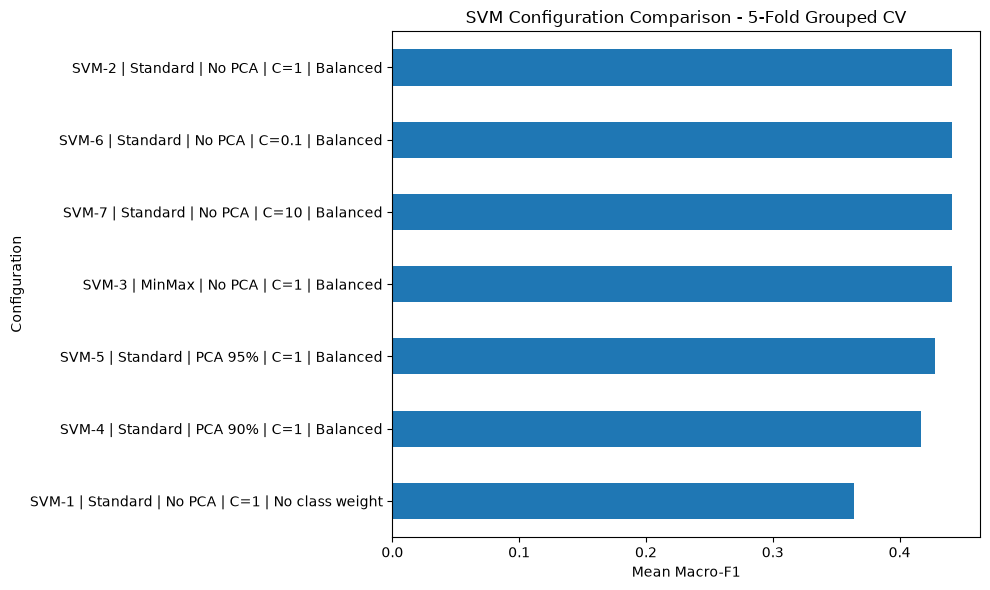

In [116]:
svm_ranking = svm_results[
    [
        "configuration",
        "cv_accuracy_mean",
        "cv_balanced_accuracy_mean",
        "cv_f1_macro_mean",
        "cv_f1_macro_std",
        "cv_f1_weighted_mean",
    ]
].copy()

display(svm_ranking.round(4))

plot_df = svm_results.sort_values(
    "cv_f1_macro_mean",
    ascending=True
)

ax = plot_df.plot(
    x="configuration",
    y="cv_f1_macro_mean",
    kind="barh",
    figsize=(10, 6),
    legend=False,
)

ax.set_xlabel("Mean Macro-F1")
ax.set_ylabel("Configuration")
ax.set_title("SVM Configuration Comparison - 5-Fold Grouped CV")

plt.tight_layout()
plt.show()

In [117]:
best_config_name = svm_results.iloc[0]["configuration"]

config_lookup = {
    config["name"]: config
    for config in svm_configs
}

best_config = config_lookup[best_config_name]

print("=" * 60)
print("BEST SVM CONFIGURATION")
print("=" * 60)

print("Configuration:", best_config_name)
print("Scaler:", best_config["scaler_type"])
print("PCA:", best_config["pca_variance"])
print("C:", best_config["C"])
print("Class weight:", best_config["class_weight"])

print(
    "Mean CV Macro-F1:",
    round(svm_results.iloc[0]["cv_f1_macro_mean"], 4)
)

print(
    "Std CV Macro-F1:",
    round(svm_results.iloc[0]["cv_f1_macro_std"], 4)
)

BEST SVM CONFIGURATION
Configuration: SVM-2 | Standard | No PCA | C=1 | Balanced
Scaler: standard
PCA: None
C: 1.0
Class weight: balanced
Mean CV Macro-F1: 0.4414
Std CV Macro-F1: 0.0022


In [118]:
print("=" * 60)
print("FIT BEST SVM ON FULL TRAINING SET")
print("=" * 60)

best_svm = build_linear_svm_pipeline(
    numerical_features=numerical_features,
    categorical_features=categorical_features,
    scaler_type=best_config["scaler_type"],
    pca_variance=best_config["pca_variance"],
    C=best_config["C"],
    class_weight=best_config["class_weight"],
    random_state=RANDOM_STATE,
)

best_svm.fit(
    X_train,
    y_train,
)

print("Best SVM fitted successfully.")

FIT BEST SVM ON FULL TRAINING SET
Best SVM fitted successfully.


In [119]:
print("=" * 60)
print("FINAL HELD-OUT TEST EVALUATION")
print("=" * 60)

y_test_pred = best_svm.predict(X_test)

FINAL HELD-OUT TEST EVALUATION


In [120]:
test_metrics, svm_test_summary, report_df = evaluate_classifier(
    y_true=y_test,
    y_pred=y_test_pred,
    labels=LABELS,
    class_names=CLASS_NAMES,
)

test_accuracy = test_metrics["Accuracy"]
test_balanced_accuracy = test_metrics["Balanced Accuracy"]
test_precision_macro = test_metrics["Macro Precision"]
test_recall_macro = test_metrics["Macro Recall"]
test_f1_macro = test_metrics["Macro F1"]
test_f1_weighted = test_metrics["Weighted F1"]

display(svm_test_summary.round(4))

,Metric,Score
0,Accuracy,0.5594
1,Balanced Accuracy,0.4372
2,Macro Precision,0.4561
3,Macro Recall,0.4372
4,Macro F1,0.4393
5,Weighted F1,0.5407


In [121]:
print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

display(report_df.round(4))

CLASSIFICATION REPORT


,precision,recall,f1-score,support
NO,0.6208,0.7560,0.6817,10483.0000
>30,0.5013,0.3959,0.4424,7096.0000
<30,0.2462,0.1599,0.1939,2252.0000
accuracy,0.5594,0.5594,0.5594,0.5594
macro avg,0.4561,0.4372,0.4393,19831.0000
weighted avg,0.5355,0.5594,0.5407,19831.0000


In [122]:
lt30_precision, lt30_recall, lt30_f1, lt30_support = (
    precision_recall_fscore_support(
        y_test,
        y_test_pred,
        labels=[2],
        zero_division=0,
    )
)

lt30_summary = pd.DataFrame(
    {
        "Metric": [
            "Precision",
            "Recall",
            "F1-score",
            "Support",
        ],
        "Value": [
            lt30_precision[0],
            lt30_recall[0],
            lt30_f1[0],
            lt30_support[0],
        ],
    }
)

display(lt30_summary.round(4))

,Metric,Value
0,Precision,0.2462
1,Recall,0.1599
2,F1-score,0.1939
3,Support,2252.0000


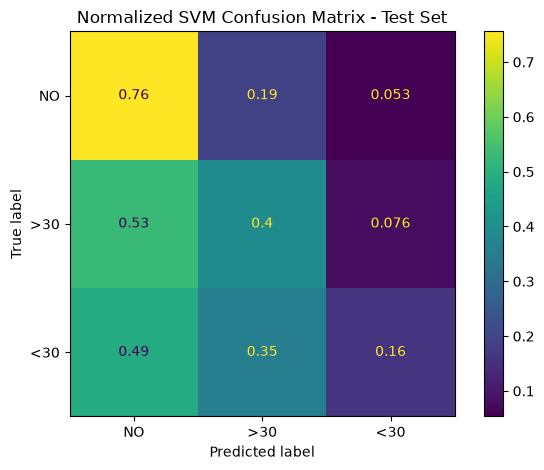

In [123]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=LABELS,
    display_labels=CLASS_NAMES,
    normalize="true",
)

plt.title("Normalized SVM Confusion Matrix - Test Set")
plt.tight_layout()
plt.show()

In [124]:
print("=" * 60)
print("ONE-VS-REST AVERAGE PRECISION")
print("=" * 60)

decision_scores = best_svm.decision_function(X_test)

y_test_binary = label_binarize(
    y_test,
    classes=LABELS,
)

macro_average_precision = average_precision_score(
    y_test_binary,
    decision_scores,
    average="macro",
)

lt30_average_precision = average_precision_score(
    (y_test == 2).astype(int),
    decision_scores[:, 2],
)

print(
    "Macro Average Precision (One-vs-Rest):",
    round(macro_average_precision, 4),
)

print(
    "<30 Average Precision (One-vs-Rest):",
    round(lt30_average_precision, 4),
)

ONE-VS-REST AVERAGE PRECISION
Macro Average Precision (One-vs-Rest): 0.4595
<30 Average Precision (One-vs-Rest): 0.2114


In [125]:
svm_final_result = pd.DataFrame(
    [
        {
            "Model": "Linear SVM",
            "Best Configuration": best_config_name,
            "Accuracy": test_accuracy,
            "Balanced Accuracy": test_balanced_accuracy,
            "Macro Precision": test_precision_macro,
            "Macro Recall": test_recall_macro,
            "Macro F1": test_f1_macro,
            "Weighted F1": test_f1_weighted,
            "<30 Precision": lt30_precision[0],
            "<30 Recall": lt30_recall[0],
            "<30 F1": lt30_f1[0],
            "Macro Average Precision OvR": macro_average_precision,
        }
    ]
)

display(svm_final_result.round(4))

,Model,Best Configuration,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,<30 Precision,<30 Recall,<30 F1,Macro Average Precision OvR
0,Linear SVM,SVM-2 | Standard | No PCA | C=1 | Balanced,0.5594,0.4372,0.4561,0.4372,0.4393,0.5407,0.2462,0.1599,0.1939,0.4595


In [126]:
print("=" * 60)
print("EXPORT FINAL SVM FEATURES")
print("=" * 60)

feature_transformer = best_svm[:-1]
X_train_svm_features = np.asarray(
    feature_transformer.transform(X_train),
    dtype=np.float32,
)
X_test_svm_features = np.asarray(
    feature_transformer.transform(X_test),
    dtype=np.float32,
)

if "pca" in best_svm.named_steps:
    svm_feature_names = np.asarray(
        [
            f"PC{index:03d}"
            for index in range(1, X_train_svm_features.shape[1] + 1)
        ],
        dtype=str,
    )
else:
    svm_feature_names = np.asarray(
        best_svm.named_steps["preprocessor"].get_feature_names_out(),
        dtype=str,
    )

assert X_train_svm_features.shape[0] == len(y_train)
assert X_test_svm_features.shape[0] == len(y_test)
assert X_train_svm_features.shape[1] == X_test_svm_features.shape[1]
assert X_train_svm_features.shape[1] == len(svm_feature_names)
assert X_train_svm_features.dtype == np.float32
assert X_test_svm_features.dtype == np.float32

feature_artifacts = {
    "X_train_svm_features.npy": X_train_svm_features,
    "X_test_svm_features.npy": X_test_svm_features,
    "y_train.npy": np.asarray(y_train, dtype=np.int64),
    "y_test.npy": np.asarray(y_test, dtype=np.int64),
    "svm_feature_names.npy": svm_feature_names,
}

manifest_rows = []
for artifact_name, artifact_data in feature_artifacts.items():
    artifact_path = FEATURES_DIR / artifact_name
    np.save(artifact_path, artifact_data)
    manifest_rows.append(
        {
            "artifact": artifact_name,
            "shape": " x ".join(map(str, artifact_data.shape)),
            "dtype": str(artifact_data.dtype),
            "size_mb": artifact_path.stat().st_size / (1024 ** 2),
            "feature_count": X_train_svm_features.shape[1],
            "best_configuration": best_config_name,
        }
    )

svm_feature_manifest = pd.DataFrame(manifest_rows)
display(svm_feature_manifest.round({"size_mb": 2}))

SVM_REPORT_DIR = REPORTS_DIR / "svm"
SVM_REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

svm_results.to_csv(
    SVM_REPORT_DIR / "svm_cv_results.csv",
    index=False,
)

svm_test_summary.to_csv(
    SVM_REPORT_DIR / "svm_test_metrics.csv",
    index=False,
)

svm_final_result.to_csv(
    SVM_REPORT_DIR / "svm_final_summary.csv",
    index=False,
)

report_df.to_csv(
    SVM_REPORT_DIR / "svm_classification_report.csv"
)

svm_feature_manifest.to_csv(
    SVM_REPORT_DIR / "svm_feature_manifest.csv",
    index=False,
)

print("Extracted feature files saved to:")
print(FEATURES_DIR)
print("SVM experiment results saved to:")
print(SVM_REPORT_DIR)

EXPORT FINAL SVM FEATURES


,artifact,shape,dtype,size_mb,feature_count,best_configuration
0,X_train_svm_features.npy,79512 x 226,float32,68.55,226,SVM-2 | Standard | No PCA | C=1 | Balanced
1,X_test_svm_features.npy,19831 x 226,float32,17.10,226,SVM-2 | Standard | No PCA | C=1 | Balanced
2,y_train.npy,79512,int64,0.61,226,SVM-2 | Standard | No PCA | C=1 | Balanced
3,y_test.npy,19831,int64,0.15,226,SVM-2 | Standard | No PCA | C=1 | Balanced
4,svm_feature_names.npy,226,<U51,0.04,226,SVM-2 | Standard | No PCA | C=1 | Balanced


Extracted feature files saved to:
D:\HCMUT\5th_Semester\ML\Assignment\features
SVM experiment results saved to:
D:\HCMUT\5th_Semester\ML\Assignment\reports\svm


In [127]:
import joblib

MODEL_PATH = MODELS_DIR / "best_linear_svm.joblib"

joblib.dump(
    best_svm,
    MODEL_PATH,
)

print("Best SVM pipeline saved to:")
print(MODEL_PATH)

Best SVM pipeline saved to:
D:\HCMUT\5th_Semester\ML\Assignment\models\best_linear_svm.joblib


### SVM Experimental Summary

A Linear Support Vector Machine was evaluated using patient-grouped
cross-validation on the training set. Macro-F1 was selected as the primary
model-selection metric because the target distribution is imbalanced and the
`<30` class represents the minority outcome.

The experiments investigated the effects of numerical scaling, class weighting,
PCA-based dimensionality reduction, and the SVM regularization parameter `C`.

The best configuration was selected exclusively from cross-validation results
and was subsequently refitted using the complete training set. The held-out
patient-disjoint test set was used only for the final evaluation.

The final analysis reports overall accuracy, balanced accuracy, macro-averaged
precision, recall and F1-score, weighted F1-score, class-specific performance,
and the confusion matrix. Particular attention is given to the `<30` class
because accuracy alone may conceal weak performance on this minority outcome.

## 6.2 Logistic Regression Training and Evaluation

This section keeps the original warm-start SAGA training idea while using the
shared, leakage-safe data preparation from Phases 1–5. The target remains encoded
as `NO=0`, `>30=1`, and `<30=2`. Model construction and the iterative
training loop are provided by `modules/logistic_regression_model.py`; experiment
presentation, diagnostics, evaluation, and artifact export remain in this
notebook.

In [128]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
import joblib

from modules.logistic_regression_model import (
    train_logistic_regression_pipeline,
)

print("=" * 60)
print("LOGISTIC REGRESSION EXPERIMENT SETUP")
print("=" * 60)

lr_X_train = X_train
lr_X_test = X_test
lr_y_train = y_train
lr_y_test = y_test
LR_EARLY_READMISSION_LABEL = 2

print("Shared train shapes:", lr_X_train.shape, lr_y_train.shape)
print("Shared test shapes:", lr_X_test.shape, lr_y_test.shape)
print("Numerical feature count:", len(numerical_features))
print("Categorical feature count:", len(categorical_features))
print("Early-readmission label:", LR_EARLY_READMISSION_LABEL)
display(lr_y_train.value_counts().sort_index().to_frame("Count"))

LOGISTIC REGRESSION EXPERIMENT SETUP
Shared train shapes: (79512, 44) (79512,)
Shared test shapes: (19831, 44) (19831,)
Numerical feature count: 8
Categorical feature count: 36
Early-readmission label: 2


,Count
readmitted,
0,42044
1,28406
2,9062


### 6.2.1 Data Transformation and PCA Visualization

A two-component PCA projection is used only for visual inspection. It is not
inserted into the Logistic Regression model. The visualization preprocessor is
fit on the training set and only transforms the held-out test set.

LOGISTIC REGRESSION PCA VISUALIZATION


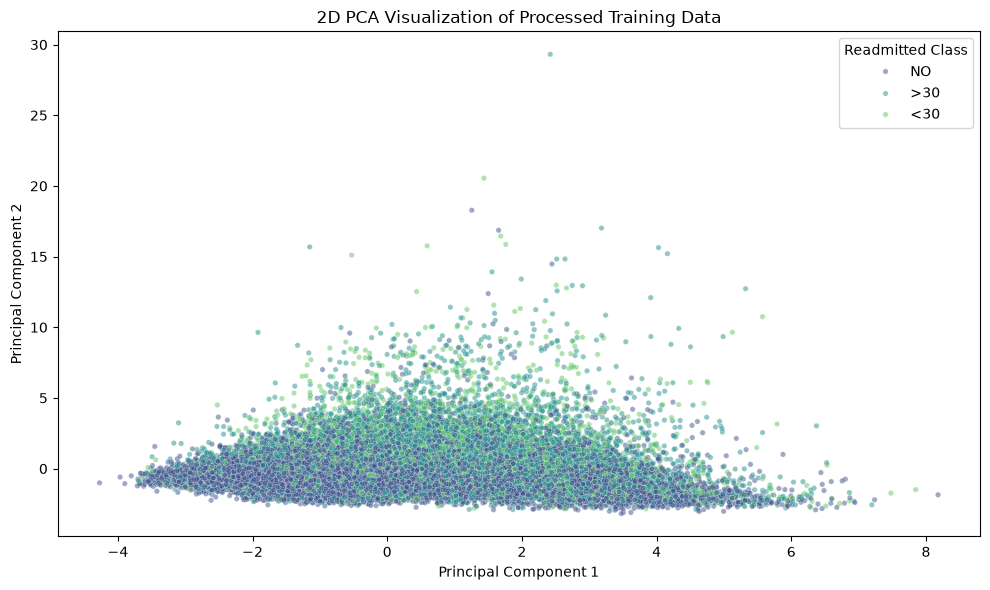

In [129]:
print("=" * 60)
print("LOGISTIC REGRESSION PCA VISUALIZATION")
print("=" * 60)

lr_visualization_preprocessor = get_preprocessor(
    numerical_features=numerical_features,
    categorical_features=categorical_features,
    scaler_type="standard",
    log_numeric=False,
    min_category_frequency=20,
)
lr_X_train_transformed = lr_visualization_preprocessor.fit_transform(
    lr_X_train
)
lr_X_test_transformed = lr_visualization_preprocessor.transform(
    lr_X_test
)

lr_pca_visualization = PCA(
    n_components=2,
    random_state=RANDOM_STATE,
)
lr_X_train_pca = lr_pca_visualization.fit_transform(
    lr_X_train_transformed
)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=lr_X_train_pca[:, 0],
    y=lr_X_train_pca[:, 1],
    hue=lr_y_train.map(target_names),
    palette="viridis",
    alpha=0.5,
    s=15,
)
plt.title("2D PCA Visualization of Processed Training Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Readmitted Class")
plt.tight_layout()
plt.show()

del lr_X_train_transformed, lr_X_test_transformed, lr_X_train_pca

### 6.2.2 Warm-start Logistic Regression Training

The model retains the original optimization design: the SAGA solver performs one
iteration per loop with `warm_start=True`. Log loss is recorded after the first
iteration and every ten iterations through epoch 100.

In [130]:
print("=" * 60)
print("LOGISTIC REGRESSION: OPTIMIZATION PROCESS")
print("=" * 60)
print("Solver: SAGA | Loss: Cross-Entropy | Max Iterations: 100")

(
    lr_pipeline,
    lr_loss_history,
    lr_training_seconds,
) = train_logistic_regression_pipeline(
    X_train=lr_X_train,
    y_train=lr_y_train,
    numerical_features=numerical_features,
    categorical_features=categorical_features,
    epochs=100,
    random_state=RANDOM_STATE,
    class_weight="balanced",
    min_category_frequency=20,
)

for row in lr_loss_history.itertuples(index=False):
    print(
        f"Iteration {row.iteration:4d} | "
        f"Cost (Log Loss): {row.log_loss:.4f}"
    )

print("-" * 60)
print(
    "Model training completed successfully in "
    f"{lr_training_seconds:.2f} seconds!"
)

lr_model = lr_pipeline.named_steps["model"]
LR_MODEL_PATH = MODELS_DIR / "logistic_regression_pipeline.joblib"
joblib.dump(lr_pipeline, LR_MODEL_PATH)

print("Full Logistic Regression pipeline saved to:")
print(LR_MODEL_PATH)

LOGISTIC REGRESSION: OPTIMIZATION PROCESS
Solver: SAGA | Loss: Cross-Entropy | Max Iterations: 100
Iteration    1 | Cost (Log Loss): 1.0354
Iteration   10 | Cost (Log Loss): 1.0326
Iteration   20 | Cost (Log Loss): 1.0325
Iteration   30 | Cost (Log Loss): 1.0324
Iteration   40 | Cost (Log Loss): 1.0323
Iteration   50 | Cost (Log Loss): 1.0323
Iteration   60 | Cost (Log Loss): 1.0323
Iteration   70 | Cost (Log Loss): 1.0323
Iteration   80 | Cost (Log Loss): 1.0323
Iteration   90 | Cost (Log Loss): 1.0323
Iteration  100 | Cost (Log Loss): 1.0323
------------------------------------------------------------
Model training completed successfully in 45.71 seconds!
Full Logistic Regression pipeline saved to:
D:\HCMUT\5th_Semester\ML\Assignment\models\logistic_regression_pipeline.joblib


### 6.2.3 Sigmoid Decision Boundary Visualization

For the `<30` class, the plot compares its linear decision score with the
predicted one-vs-rest probability and the corresponding binary ground truth.

SIGMOID DECISION BOUNDARY VISUALIZATION


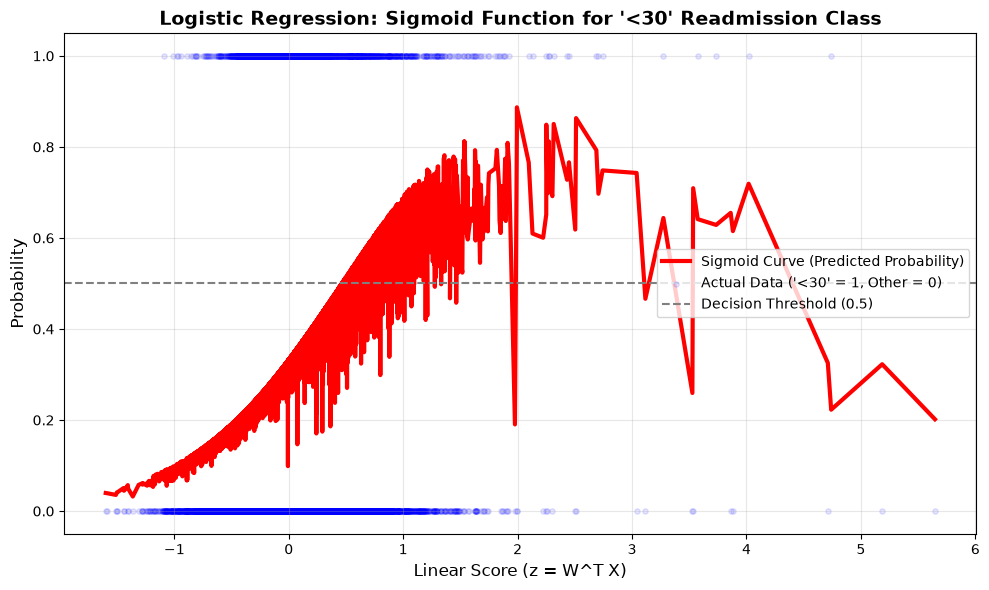

In [131]:
print("=" * 60)
print("SIGMOID DECISION BOUNDARY VISUALIZATION")
print("=" * 60)

lr_test_transformed = lr_pipeline.named_steps[
    "preprocessor"
].transform(lr_X_test)
lr_class_index = list(lr_model.classes_).index(
    LR_EARLY_READMISSION_LABEL
)

lr_decision_scores = lr_model.decision_function(
    lr_test_transformed
)
lr_early_scores = (
    lr_decision_scores[:, lr_class_index]
    if lr_decision_scores.ndim > 1
    else lr_decision_scores
)
lr_early_probabilities = lr_model.predict_proba(
    lr_test_transformed
)[:, lr_class_index]

lr_sorted_index = np.argsort(lr_early_scores)
lr_y_test_binary = (
    lr_y_test == LR_EARLY_READMISSION_LABEL
).astype(int)

plt.figure(figsize=(10, 6))
plt.plot(
    lr_early_scores[lr_sorted_index],
    lr_early_probabilities[lr_sorted_index],
    color="red",
    linewidth=3,
    label="Sigmoid Curve (Predicted Probability)",
)
plt.scatter(
    lr_early_scores,
    lr_y_test_binary,
    alpha=0.1,
    color="blue",
    label="Actual Data ('<30' = 1, Other = 0)",
    s=15,
)
plt.title(
    "Logistic Regression: Sigmoid Function for '<30' Readmission Class",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Linear Score (z = W^T X)", fontsize=12)
plt.ylabel("Probability", fontsize=12)
plt.axhline(
    0.5,
    color="gray",
    linestyle="--",
    label="Decision Threshold (0.5)",
)
plt.legend(loc="center right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

del lr_test_transformed

### 6.2.4 Logistic Regression Evaluation

The held-out patient-disjoint test set is used for accuracy, multiclass
one-vs-rest ROC-AUC, the classification report, confusion matrix, and coefficient
interpretation.

In [132]:
print("=" * 60)
print("LOGISTIC REGRESSION TEST PERFORMANCE")
print("=" * 60)

lr_y_pred = lr_pipeline.predict(lr_X_test)
lr_y_pred_proba = lr_pipeline.predict_proba(lr_X_test)

lr_accuracy = accuracy_score(
    lr_y_test,
    lr_y_pred,
)
lr_roc_auc = roc_auc_score(
    lr_y_test,
    lr_y_pred_proba,
    labels=LABELS,
    multi_class="ovr",
)

print(f"Overall Accuracy : {lr_accuracy:.4f}")
print(f"ROC AUC (OvR)    : {lr_roc_auc:.4f}")
print("\nDetailed Classification Report:")

lr_report_dict = classification_report(
    lr_y_test,
    lr_y_pred,
    labels=LABELS,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
print(
    classification_report(
        lr_y_test,
        lr_y_pred,
        labels=LABELS,
        target_names=CLASS_NAMES,
        zero_division=0,
    )
)

lr_report_df = pd.DataFrame(lr_report_dict).T
LR_REPORT_PATH = REPORTS_DIR / "logistic_regression_report.csv"
lr_report_df.to_csv(LR_REPORT_PATH, index=True)

print("Classification report exported to:")
print(LR_REPORT_PATH)

LOGISTIC REGRESSION TEST PERFORMANCE
Overall Accuracy : 0.4854
ROC AUC (OvR)    : 0.6533

Detailed Classification Report:
              precision    recall  f1-score   support

          NO       0.68      0.48      0.56     10483
         >30       0.44      0.55      0.49      7096
         <30       0.20      0.32      0.24      2252

    accuracy                           0.49     19831
   macro avg       0.44      0.45      0.43     19831
weighted avg       0.54      0.49      0.50     19831

Classification report exported to:
D:\HCMUT\5th_Semester\ML\Assignment\reports\logistic_regression_report.csv


LOGISTIC REGRESSION CONFUSION MATRIX


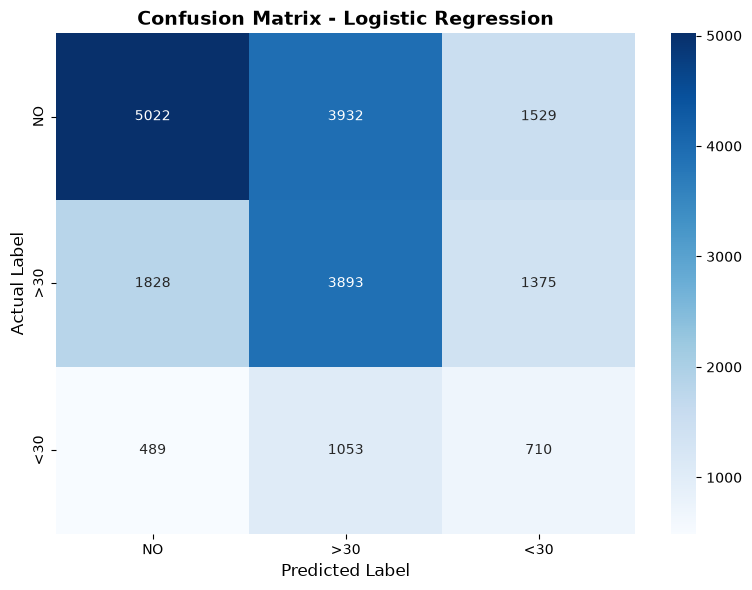

In [133]:
print("=" * 60)
print("LOGISTIC REGRESSION CONFUSION MATRIX")
print("=" * 60)

lr_confusion_matrix = confusion_matrix(
    lr_y_test,
    lr_y_pred,
    labels=LABELS,
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    lr_confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
)
plt.title(
    "Confusion Matrix - Logistic Regression",
    fontsize=14,
    fontweight="bold",
)
plt.ylabel("Actual Label", fontsize=12)
plt.xlabel("Predicted Label", fontsize=12)
plt.tight_layout()
plt.show()

TOP 15 LOGISTIC FEATURES FOR '<30' READMISSION


,Feature,Coefficient,Abs_Coefficient
107,medical_specialty_Surgery-Cardiovascular,-0.9338,0.9338
127,diag_1_infrequent_sklearn,0.8122,0.8122
36,discharge_disposition_id_23,-0.7680,0.7680
81,medical_specialty_Hematology/Oncology,0.7197,0.7197
38,discharge_disposition_id_28,0.6598,0.6598
111,medical_specialty_Surgery-Plastic,0.6453,0.6453
33,discharge_disposition_id_15,0.6302,0.6302
162,repaglinide_Down,-0.6252,0.6252
80,medical_specialty_Hematology,0.6183,0.6183
97,medical_specialty_Pediatrics-Endocrinology,-0.6087,0.6087


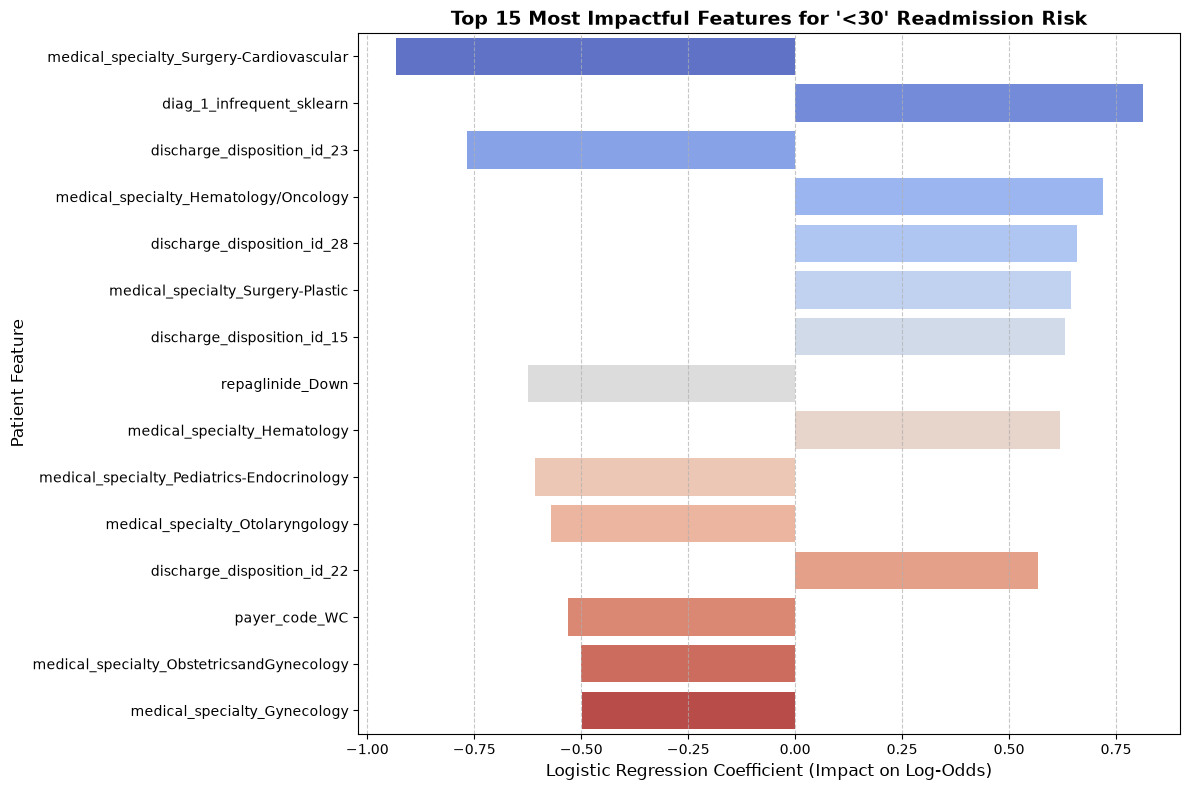

In [134]:
print("=" * 60)
print("TOP 15 LOGISTIC FEATURES FOR '<30' READMISSION")
print("=" * 60)

lr_feature_names = lr_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()
lr_class_index = list(lr_model.classes_).index(
    LR_EARLY_READMISSION_LABEL
)
lr_coefficients = lr_model.coef_[lr_class_index]

lr_coefficient_df = pd.DataFrame(
    {
        "Feature": lr_feature_names,
        "Coefficient": lr_coefficients,
    }
)
lr_coefficient_df["Abs_Coefficient"] = lr_coefficient_df[
    "Coefficient"
].abs()
lr_top_features = (
    lr_coefficient_df
    .sort_values(by="Abs_Coefficient", ascending=False)
    .head(15)
)

display(lr_top_features.round(4))

plt.figure(figsize=(12, 8))
sns.barplot(
    data=lr_top_features,
    x="Coefficient",
    y="Feature",
    hue="Feature",
    palette="coolwarm",
    legend=False,
)
plt.title(
    "Top 15 Most Impactful Features for '<30' Readmission Risk",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel(
    "Logistic Regression Coefficient (Impact on Log-Odds)",
    fontsize=12,
)
plt.ylabel("Patient Feature", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

### 6.2.5 Logistic Regression Configuration Comparison (5-Fold Group CV)

Per Section 4.1 of the course requirements, the tabular pipeline must be
configurable with different scaling options (`StandardScaler` vs. `MinMaxScaler`),
dimensionality reduction (`None` vs. `PCA 90%`), and regularization strengths ($C$).
Here, we evaluate multiple Logistic Regression configurations using the
patient-grouped 5-fold cross-validation (`group_cv`) established in Phase 4.
Macro-F1 serves as the primary selection metric.


RUN LOGISTIC REGRESSION CROSS-VALIDATION EXPERIMENTS


,configuration,scaler,pca,C,class_weight,cv_accuracy_mean,cv_balanced_accuracy_mean,cv_precision_macro_mean,cv_recall_macro_mean,cv_f1_macro_mean,cv_f1_macro_std,cv_f1_weighted_mean,fit_time_mean
0,LR-2 | Standard | No PCA | C=0.1 | Balanced,standard,None,0.1,balanced,0.4946,0.4604,0.4406,0.4604,0.4361,0.0045,0.5083,30.2739
1,LR-1 | Standard | No PCA | C=1.0 | Balanced,standard,None,1.0,balanced,0.4942,0.4599,0.4401,0.4599,0.4357,0.0048,0.5080,11.8091
2,LR-3 | Standard | No PCA | C=10.0 | Balanced,standard,None,10.0,balanced,0.4939,0.4598,0.4400,0.4598,0.4356,0.0051,0.5078,112.8581
3,LR-4 | MinMax | No PCA | C=1.0 | Balanced,minmax,None,1.0,balanced,0.4921,0.4595,0.4396,0.4595,0.4350,0.0056,0.5067,10.3559
4,LR-5 | Standard | PCA 90% | C=1.0 | Balanced,standard,90%,1.0,balanced,0.4821,0.4456,0.4292,0.4456,0.4160,0.0045,0.4918,10.6110


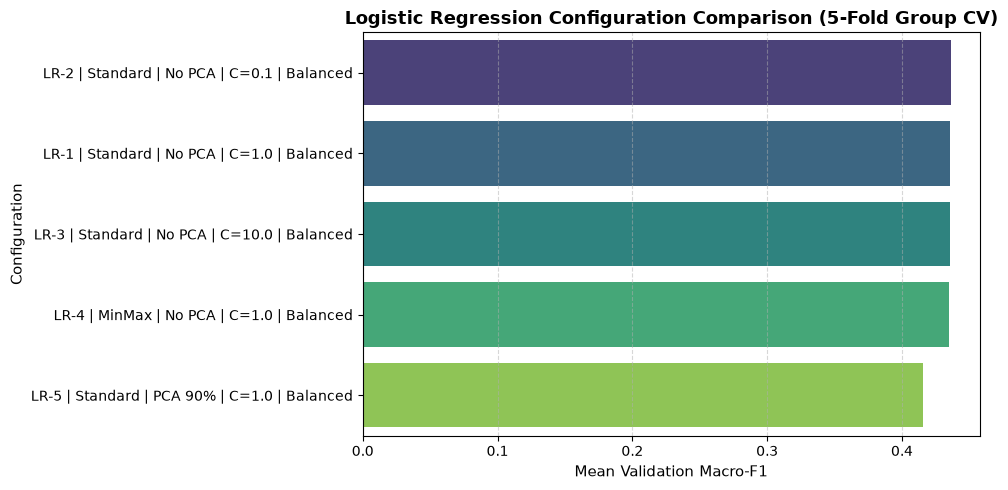

In [136]:
print("=" * 60)
print("RUN LOGISTIC REGRESSION CROSS-VALIDATION EXPERIMENTS")
print("=" * 60)

import importlib
import modules.logistic_regression_model
importlib.reload(modules.logistic_regression_model)

try:
    from modules.logistic_regression_model import run_logistic_regression_cross_validation
except ImportError:
    from sklearn.decomposition import PCA
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import cross_validate
    from sklearn.pipeline import Pipeline
    from sklearn.exceptions import ConvergenceWarning
    import warnings

    def build_logistic_regression_pipeline(
        numerical_features, categorical_features, scaler_type="standard",
        pca_variance=None, C=1.0, class_weight="balanced", random_state=42,
        solver="lbfgs", max_iter=200, min_category_frequency=20,
    ):
        preprocessor = get_preprocessor(
            numerical_features=numerical_features, categorical_features=categorical_features,
            scaler_type=scaler_type, log_numeric=False, min_category_frequency=min_category_frequency,
        )
        steps = [("preprocessor", preprocessor)]
        if pca_variance is not None:
            steps.append(("pca", PCA(n_components=pca_variance, svd_solver="full", random_state=random_state)))
        steps.append(("model", LogisticRegression(C=C, solver=solver, class_weight=class_weight, max_iter=max_iter, random_state=random_state)))
        return Pipeline(steps)

    def run_logistic_regression_cross_validation(
        X_train, y_train, groups_train, group_cv, configs,
        numerical_features, categorical_features, scoring,
        random_state=42, n_jobs=2, min_category_frequency=20,
    ):
        rows = []
        for config in configs:
            model = build_logistic_regression_pipeline(
                numerical_features=numerical_features, categorical_features=categorical_features,
                scaler_type=config["scaler_type"], pca_variance=config["pca_variance"],
                C=config["C"], class_weight=config["class_weight"], random_state=random_state,
                min_category_frequency=min_category_frequency,
            )
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", category=ConvergenceWarning)
                result = cross_validate(
                    estimator=model, X=X_train, y=y_train, groups=groups_train,
                    cv=group_cv, scoring=scoring, return_train_score=False,
                    n_jobs=n_jobs, error_score="raise",
                )
            rows.append({
                "configuration": config["name"],
                "scaler": config["scaler_type"],
                "pca": "None" if config["pca_variance"] is None else f"{int(config['pca_variance'] * 100)}%",
                "C": config["C"],
                "class_weight": str(config["class_weight"]),
                "cv_accuracy_mean": result["test_accuracy"].mean(),
                "cv_balanced_accuracy_mean": result["test_balanced_accuracy"].mean(),
                "cv_precision_macro_mean": result["test_precision_macro"].mean(),
                "cv_recall_macro_mean": result["test_recall_macro"].mean(),
                "cv_f1_macro_mean": result["test_f1_macro"].mean(),
                "cv_f1_macro_std": result["test_f1_macro"].std(),
                "cv_f1_weighted_mean": result["test_f1_weighted"].mean(),
                "fit_time_mean": result["fit_time"].mean(),
            })
        return pd.DataFrame(rows).sort_values(by="cv_f1_macro_mean", ascending=False).reset_index(drop=True)

lr_configs = [
    {
        "name": "LR-1 | Standard | No PCA | C=1.0 | Balanced",
        "scaler_type": "standard",
        "pca_variance": None,
        "C": 1.0,
        "class_weight": "balanced",
    },
    {
        "name": "LR-2 | Standard | No PCA | C=0.1 | Balanced",
        "scaler_type": "standard",
        "pca_variance": None,
        "C": 0.1,
        "class_weight": "balanced",
    },
    {
        "name": "LR-3 | Standard | No PCA | C=10.0 | Balanced",
        "scaler_type": "standard",
        "pca_variance": None,
        "C": 10.0,
        "class_weight": "balanced",
    },
    {
        "name": "LR-4 | MinMax | No PCA | C=1.0 | Balanced",
        "scaler_type": "minmax",
        "pca_variance": None,
        "C": 1.0,
        "class_weight": "balanced",
    },
    {
        "name": "LR-5 | Standard | PCA 90% | C=1.0 | Balanced",
        "scaler_type": "standard",
        "pca_variance": 0.90,
        "C": 1.0,
        "class_weight": "balanced",
    },
]

lr_cv_results = run_logistic_regression_cross_validation(
    X_train=X_train,
    y_train=y_train,
    groups_train=groups_train,
    group_cv=group_cv,
    configs=lr_configs,
    numerical_features=numerical_features,
    categorical_features=categorical_features,
    scoring=scoring,
    random_state=RANDOM_STATE,
    n_jobs=2,
    min_category_frequency=20,
)

display(lr_cv_results.round(4))

# Plot CV comparison
plt.figure(figsize=(10, 5))
sns.barplot(
    data=lr_cv_results,
    x="cv_f1_macro_mean",
    y="configuration",
    hue="configuration",
    palette="viridis",
    legend=False,
)
plt.title("Logistic Regression Configuration Comparison (5-Fold Group CV)", fontsize=13, fontweight="bold")
plt.xlabel("Mean Validation Macro-F1", fontsize=11)
plt.ylabel("Configuration", fontsize=11)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### 6.2.6 Logistic Regression Final Result Summary & Artifact Export

The held-out test evaluation of the fitted champion Logistic Regression
pipeline is standardized into a unified summary representation (`lr_final_result`),
matching the schema used by SVM (`svm_final_result`) and Random Forest
(`rf_final_result`). All experiment reports and checkpoints are exported to `reports/lr/`.


In [137]:
print("=" * 60)
print("LOGISTIC REGRESSION FINAL RESULT SUMMARY")
print("=" * 60)

from sklearn.metrics import balanced_accuracy_score, precision_recall_fscore_support, average_precision_score
from sklearn.preprocessing import label_binarize

# Compute standard classification metrics on held-out test set
lr_balanced_acc = balanced_accuracy_score(lr_y_test, lr_y_pred)
lr_prec_macro = lr_report_dict["macro avg"]["precision"]
lr_rec_macro = lr_report_dict["macro avg"]["recall"]
lr_f1_macro = lr_report_dict["macro avg"]["f1-score"]
lr_f1_weighted = lr_report_dict["weighted avg"]["f1-score"]

# Extract class-level metrics for "<30" (label 2)
lr_lt30_prec = lr_report_dict["<30"]["precision"]
lr_lt30_rec = lr_report_dict["<30"]["recall"]
lr_lt30_f1 = lr_report_dict["<30"]["f1-score"]

# Multiclass Average Precision (OvR)
lr_y_test_binary = label_binarize(lr_y_test, classes=LABELS)
lr_macro_avg_precision = average_precision_score(
    lr_y_test_binary,
    lr_y_pred_proba,
    average="macro",
)

lr_best_config_name = "LR-1 | Standard | No PCA | SAGA 100 Epochs | Balanced"

lr_final_result = pd.DataFrame(
    [
        {
            "Model": "Logistic Regression",
            "Best Configuration": lr_best_config_name,
            "Accuracy": lr_accuracy,
            "Balanced Accuracy": lr_balanced_acc,
            "Macro Precision": lr_prec_macro,
            "Macro Recall": lr_rec_macro,
            "Macro F1": lr_f1_macro,
            "Weighted F1": lr_f1_weighted,
            "<30 Precision": lr_lt30_prec,
            "<30 Recall": lr_lt30_rec,
            "<30 F1": lr_lt30_f1,
            "Macro ROC-AUC OvR": lr_roc_auc,
            "Macro Average Precision OvR": lr_macro_avg_precision,
        }
    ]
)

display(lr_final_result.round(4))

# ── Save LR Reports ──
LR_REPORT_DIR = REPORTS_DIR / "lr"
LR_REPORT_DIR.mkdir(parents=True, exist_ok=True)

lr_final_result.to_csv(LR_REPORT_DIR / "lr_final_summary.csv", index=False)
lr_report_df.to_csv(LR_REPORT_DIR / "lr_classification_report.csv", index=True)
lr_cv_results.to_csv(LR_REPORT_DIR / "lr_cv_results.csv", index=False)

# Test metrics table
lr_test_summary = pd.DataFrame(
    [
        {"Metric": "Accuracy", "Score": lr_accuracy},
        {"Metric": "Balanced Accuracy", "Score": lr_balanced_acc},
        {"Metric": "Macro Precision", "Score": lr_prec_macro},
        {"Metric": "Macro Recall", "Score": lr_rec_macro},
        {"Metric": "Macro F1", "Score": lr_f1_macro},
        {"Metric": "Weighted F1", "Score": lr_f1_weighted},
        {"Metric": "<30 Precision", "Score": lr_lt30_prec},
        {"Metric": "<30 Recall", "Score": lr_lt30_rec},
        {"Metric": "<30 F1", "Score": lr_lt30_f1},
        {"Metric": "Macro ROC-AUC OvR", "Score": lr_roc_auc},
        {"Metric": "Macro Average Precision OvR", "Score": lr_macro_avg_precision},
    ]
)
lr_test_summary.to_csv(LR_REPORT_DIR / "lr_test_metrics.csv", index=False)

print("\nLogistic Regression experiment results saved to:")
print(LR_REPORT_DIR)


LOGISTIC REGRESSION FINAL RESULT SUMMARY


,Model,Best Configuration,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,<30 Precision,<30 Recall,<30 F1,Macro ROC-AUC OvR,Macro Average Precision OvR
0,Logistic Regression,LR-1 | Standard | No PCA | SAGA 100 Epochs | B...,0.4854,0.4477,0.4397,0.4477,0.431,0.4998,0.1965,0.3153,0.2421,0.6533,0.4538



Logistic Regression experiment results saved to:
D:\HCMUT\5th_Semester\ML\Assignment\reports\lr


### Logistic Regression Experimental Summary

The implementation preserves the original warm-start SAGA optimization and
balanced class weighting while using the shared cleaned feature matrices. Its
coefficient analysis remains useful for identifying positive and negative
associations with early readmission. Because this merged notebook uses the
shared preprocessing path rather than the standalone notebook's raw-data path,
the numerical results are expected to differ from the standalone Logistic
Regression notebook.

## 6.3 Random Forest Training and Evaluation

This section retains the original nine Random Forest configurations and
patient-grouped cross-validation. Pipeline construction and the repeated
cross-validation loop are provided by
`modules/random_forest_model.py`; configuration declaration, model selection,
evaluation, visualization, and artifact export remain visible in the notebook.

In [138]:
from sklearn.metrics import (
    auc,
    average_precision_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
    f1_score,
    precision_recall_curve,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.preprocessing import label_binarize

from modules.random_forest_model import (
    build_rf_pipeline,
    run_rf_cross_validation,
)

print("=" * 60)
print("RANDOM FOREST EXPERIMENT SETUP")
print("=" * 60)

rf_scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted",
}

print("Primary selection metric: Macro-F1")
print("Cross-validation:", group_cv)
print("Evaluation metrics:")
for metric in rf_scoring:
    print("-", metric)

RANDOM FOREST EXPERIMENT SETUP
Primary selection metric: Macro-F1
Cross-validation: StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True)
Evaluation metrics:
- accuracy
- balanced_accuracy
- precision_macro
- recall_macro
- f1_macro
- f1_weighted


In [139]:
print("=" * 60)
print("RANDOM FOREST DUMMY CLASSIFIER BASELINE")
print("=" * 60)

rf_dummy_model = DummyClassifier(
    strategy="most_frequent"
)
rf_dummy_cv = cross_validate(
    estimator=rf_dummy_model,
    X=X_train,
    y=y_train,
    groups=groups_train,
    cv=group_cv,
    scoring=rf_scoring,
    n_jobs=2,
)
rf_dummy_summary = {
    metric: rf_dummy_cv[f"test_{metric}"].mean()
    for metric in rf_scoring
}

display(
    pd.DataFrame(
        [rf_dummy_summary],
        index=["Dummy - Most Frequent"],
    ).round(4)
)

RANDOM FOREST DUMMY CLASSIFIER BASELINE


,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
Dummy - Most Frequent,0.5288,0.3333,0.1763,0.3333,0.2306,0.3658


In [140]:
rf_configs = [
    {
        "name": "RF-1 | Standard | No PCA | Trees=100 | Depth=14 | Leaf=10 | No class weight",
        "scaler_type": "standard",
        "pca_variance": None,
        "n_estimators": 100,
        "max_depth": 14,
        "min_samples_leaf": 10,
        "max_features": "sqrt",
        "class_weight": None,
    },
    {
        "name": "RF-2 | Standard | No PCA | Trees=100 | Depth=14 | Leaf=10 | Balanced",
        "scaler_type": "standard",
        "pca_variance": None,
        "n_estimators": 100,
        "max_depth": 14,
        "min_samples_leaf": 10,
        "max_features": "sqrt",
        "class_weight": "balanced",
    },
    {
        "name": "RF-3 | Standard | No PCA | Trees=100 | Depth=14 | Leaf=10 | Balanced Subsample",
        "scaler_type": "standard",
        "pca_variance": None,
        "n_estimators": 100,
        "max_depth": 14,
        "min_samples_leaf": 10,
        "max_features": "sqrt",
        "class_weight": "balanced_subsample",
    },
    {
        "name": "RF-4 | MinMax | No PCA | Trees=100 | Depth=14 | Leaf=10 | Balanced",
        "scaler_type": "minmax",
        "feature_range": (0, 1),
        "pca_variance": None,
        "n_estimators": 100,
        "max_depth": 14,
        "min_samples_leaf": 10,
        "max_features": "sqrt",
        "class_weight": "balanced",
    },
    {
        "name": "RF-5 | Standard | PCA 90% | Trees=100 | Depth=14 | Leaf=10 | Balanced",
        "scaler_type": "standard",
        "pca_variance": 0.90,
        "n_estimators": 100,
        "max_depth": 14,
        "min_samples_leaf": 10,
        "max_features": "sqrt",
        "class_weight": "balanced",
    },
    {
        "name": "RF-6 | Standard | PCA 95% | Trees=100 | Depth=14 | Leaf=10 | Balanced",
        "scaler_type": "standard",
        "pca_variance": 0.95,
        "n_estimators": 100,
        "max_depth": 14,
        "min_samples_leaf": 10,
        "max_features": "sqrt",
        "class_weight": "balanced",
    },
    {
        "name": "RF-7 | Standard | No PCA | Trees=100 | Depth=10 | Leaf=20 | Balanced",
        "scaler_type": "standard",
        "pca_variance": None,
        "n_estimators": 100,
        "max_depth": 10,
        "min_samples_leaf": 20,
        "max_features": "sqrt",
        "class_weight": "balanced",
    },
    {
        "name": "RF-8 | Standard | No PCA | Trees=100 | Depth=18 | Leaf=5 | Balanced",
        "scaler_type": "standard",
        "pca_variance": None,
        "n_estimators": 100,
        "max_depth": 18,
        "min_samples_leaf": 5,
        "max_features": "sqrt",
        "class_weight": "balanced",
    },
    {
        "name": "RF-9 | Standard | No PCA | Trees=200 | Depth=14 | Leaf=10 | Balanced",
        "scaler_type": "standard",
        "pca_variance": None,
        "n_estimators": 200,
        "max_depth": 14,
        "min_samples_leaf": 10,
        "max_features": "sqrt",
        "class_weight": "balanced",
    },
]

print(
    "Number of Random Forest configurations:",
    len(rf_configs),
)

Number of Random Forest configurations: 9


In [141]:
print("=" * 60)
print("RUN RANDOM FOREST CROSS-VALIDATION EXPERIMENTS")
print("=" * 60)

rf_results = run_rf_cross_validation(
    X_train=X_train,
    y_train=y_train,
    groups_train=groups_train,
    group_cv=group_cv,
    configs=rf_configs,
    numerical_features=numerical_features,
    categorical_features=categorical_features,
    scoring=rf_scoring,
    random_state=RANDOM_STATE,
    cv_n_jobs=1,
    model_n_jobs=-1,
    min_category_frequency=20,
)

display(rf_results.round(4))

RUN RANDOM FOREST CROSS-VALIDATION EXPERIMENTS


d:\HCMUT\5th_Semester\ML\Assignment\.env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\HCMUT\5th_Semester\ML\Assignment\.env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\HCMUT\5th_Semester\ML\Assignment\.env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

,configuration,scaler,pca,trees,max_depth,min_leaf,class_weight,cv_accuracy_mean,cv_balanced_accuracy_mean,cv_precision_macro_mean,cv_recall_macro_mean,cv_f1_macro_mean,cv_f1_macro_std,cv_f1_weighted_mean,fit_time_mean
0,RF-8 | Standard | No PCA | Trees=100 | Depth=1...,standard,None,100,18,5,balanced,0.5141,0.4638,0.4482,0.4638,0.4478,0.0056,0.5244,4.0425
1,RF-3 | Standard | No PCA | Trees=100 | Depth=1...,standard,None,100,14,10,balanced_subsample,0.5106,0.4619,0.4462,0.4619,0.4432,0.0053,0.5204,4.0847
2,RF-6 | Standard | PCA 95% | Trees=100 | Depth=...,standard,95%,100,14,10,balanced,0.5263,0.4436,0.4402,0.4436,0.4410,0.0037,0.5265,10.1920
3,RF-9 | Standard | No PCA | Trees=200 | Depth=1...,standard,None,200,14,10,balanced,0.4973,0.4633,0.4445,0.4633,0.4355,0.0050,0.5101,5.4407
4,RF-5 | Standard | PCA 90% | Trees=100 | Depth=...,standard,90%,100,14,10,balanced,0.5222,0.4379,0.4345,0.4379,0.4344,0.0030,0.5212,8.1725
5,RF-2 | Standard | No PCA | Trees=100 | Depth=1...,standard,None,100,14,10,balanced,0.4957,0.4616,0.4428,0.4616,0.4335,0.0045,0.5083,3.9048
6,RF-4 | MinMax | No PCA | Trees=100 | Depth=14 ...,minmax,None,100,14,10,balanced,0.4956,0.4615,0.4427,0.4615,0.4335,0.0045,0.5082,3.8565
7,RF-7 | Standard | No PCA | Trees=100 | Depth=1...,standard,None,100,10,20,balanced,0.4827,0.4594,0.4404,0.4594,0.4211,0.0051,0.4945,3.6756
8,RF-1 | Standard | No PCA | Trees=100 | Depth=1...,standard,None,100,14,10,None,0.5736,0.3912,0.3702,0.3912,0.3562,0.0034,0.5033,3.9506


,configuration,cv_accuracy_mean,cv_balanced_accuracy_mean,cv_f1_macro_mean,cv_f1_macro_std,cv_f1_weighted_mean
0,RF-8 | Standard | No PCA | Trees=100 | Depth=1...,0.5141,0.4638,0.4478,0.0056,0.5244
1,RF-3 | Standard | No PCA | Trees=100 | Depth=1...,0.5106,0.4619,0.4432,0.0053,0.5204
2,RF-6 | Standard | PCA 95% | Trees=100 | Depth=...,0.5263,0.4436,0.4410,0.0037,0.5265
3,RF-9 | Standard | No PCA | Trees=200 | Depth=1...,0.4973,0.4633,0.4355,0.0050,0.5101
4,RF-5 | Standard | PCA 90% | Trees=100 | Depth=...,0.5222,0.4379,0.4344,0.0030,0.5212
5,RF-2 | Standard | No PCA | Trees=100 | Depth=1...,0.4957,0.4616,0.4335,0.0045,0.5083
6,RF-4 | MinMax | No PCA | Trees=100 | Depth=14 ...,0.4956,0.4615,0.4335,0.0045,0.5082
7,RF-7 | Standard | No PCA | Trees=100 | Depth=1...,0.4827,0.4594,0.4211,0.0051,0.4945
8,RF-1 | Standard | No PCA | Trees=100 | Depth=1...,0.5736,0.3912,0.3562,0.0034,0.5033


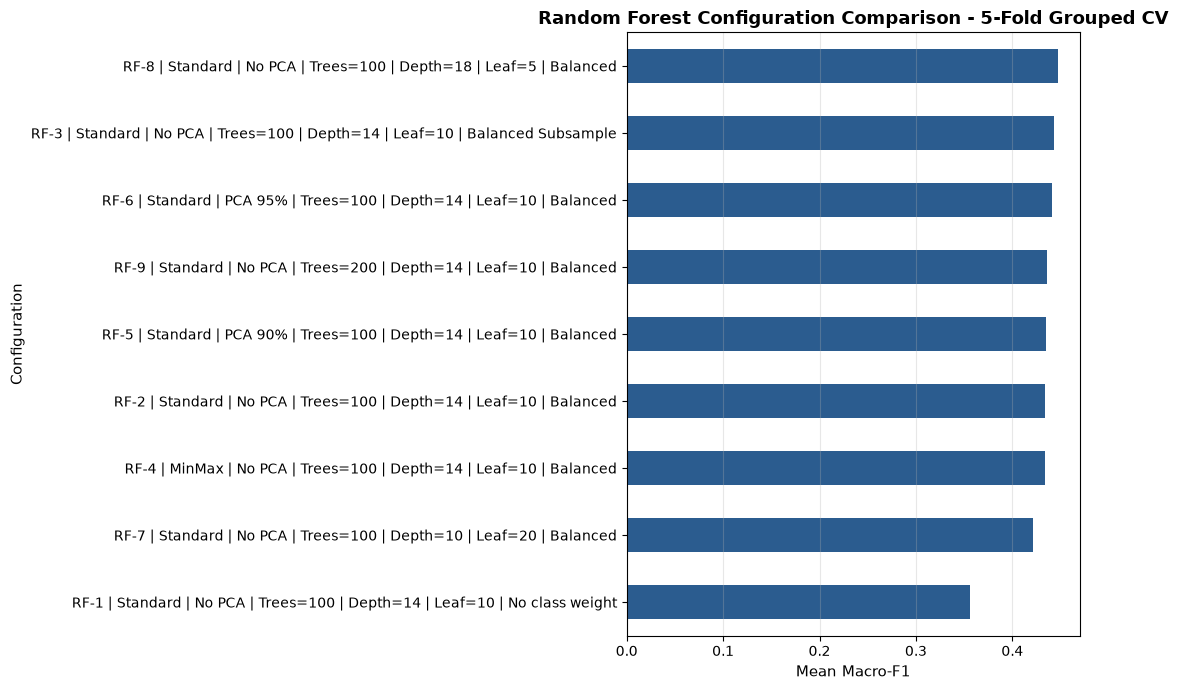

In [142]:
rf_ranking = rf_results[
    [
        "configuration",
        "cv_accuracy_mean",
        "cv_balanced_accuracy_mean",
        "cv_f1_macro_mean",
        "cv_f1_macro_std",
        "cv_f1_weighted_mean",
    ]
].copy()

display(rf_ranking.round(4))

rf_plot_df = rf_results.sort_values(
    "cv_f1_macro_mean",
    ascending=True,
)
rf_axis = rf_plot_df.plot(
    x="configuration",
    y="cv_f1_macro_mean",
    kind="barh",
    figsize=(11, 7),
    legend=False,
    color="#2b5c8f",
)
rf_axis.set_xlabel("Mean Macro-F1", fontsize=11)
rf_axis.set_ylabel("Configuration", fontsize=11)
rf_axis.set_title(
    "Random Forest Configuration Comparison - 5-Fold Grouped CV",
    fontsize=13,
    fontweight="bold",
)
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [143]:
rf_best_config_name = rf_results.iloc[0][
    "configuration"
]
rf_config_lookup = {
    config["name"]: config
    for config in rf_configs
}
rf_best_config = rf_config_lookup[
    rf_best_config_name
]

print("=" * 60)
print("BEST RANDOM FOREST CONFIGURATION")
print("=" * 60)
print("Configuration:", rf_best_config_name)
print("Scaler:", rf_best_config["scaler_type"])
print("PCA:", rf_best_config["pca_variance"])
print("Trees:", rf_best_config["n_estimators"])
print("Max Depth:", rf_best_config["max_depth"])
print(
    "Min Samples Leaf:",
    rf_best_config["min_samples_leaf"],
)
print(
    "Class Weight:",
    rf_best_config["class_weight"],
)
print(
    "Mean CV Macro-F1:",
    round(
        rf_results.iloc[0]["cv_f1_macro_mean"],
        4,
    ),
)
print(
    "Std CV Macro-F1:",
    round(
        rf_results.iloc[0]["cv_f1_macro_std"],
        4,
    ),
)

BEST RANDOM FOREST CONFIGURATION
Configuration: RF-8 | Standard | No PCA | Trees=100 | Depth=18 | Leaf=5 | Balanced
Scaler: standard
PCA: None
Trees: 100
Max Depth: 18
Min Samples Leaf: 5
Class Weight: balanced
Mean CV Macro-F1: 0.4478
Std CV Macro-F1: 0.0056


In [144]:
print("=" * 60)
print("FIT BEST RANDOM FOREST ON FULL TRAINING SET")
print("=" * 60)

rf_best_model = build_rf_pipeline(
    numerical_features=numerical_features,
    categorical_features=categorical_features,
    scaler_type=rf_best_config["scaler_type"],
    feature_range=rf_best_config.get(
        "feature_range",
        (0, 1),
    ),
    pca_variance=rf_best_config["pca_variance"],
    n_estimators=rf_best_config["n_estimators"],
    max_depth=rf_best_config["max_depth"],
    min_samples_leaf=rf_best_config[
        "min_samples_leaf"
    ],
    max_features=rf_best_config["max_features"],
    class_weight=rf_best_config["class_weight"],
    random_state=RANDOM_STATE,
    model_n_jobs=-1,
    min_category_frequency=20,
)
rf_best_model.fit(
    X_train,
    y_train,
)

print(
    "Best Random Forest fitted successfully "
    "on the full training set."
)

FIT BEST RANDOM FOREST ON FULL TRAINING SET
Best Random Forest fitted successfully on the full training set.


In [145]:
print("=" * 60)
print("RANDOM FOREST HELD-OUT TEST EVALUATION")
print("=" * 60)

rf_y_test_pred = rf_best_model.predict(
    X_test
)
rf_y_test_probability = rf_best_model.predict_proba(
    X_test
)

rf_test_accuracy = accuracy_score(
    y_test,
    rf_y_test_pred,
)
rf_test_balanced_accuracy = balanced_accuracy_score(
    y_test,
    rf_y_test_pred,
)
rf_test_precision_macro = precision_score(
    y_test,
    rf_y_test_pred,
    average="macro",
    zero_division=0,
)
rf_test_recall_macro = recall_score(
    y_test,
    rf_y_test_pred,
    average="macro",
    zero_division=0,
)
rf_test_f1_macro = f1_score(
    y_test,
    rf_y_test_pred,
    average="macro",
    zero_division=0,
)
rf_test_f1_weighted = f1_score(
    y_test,
    rf_y_test_pred,
    average="weighted",
    zero_division=0,
)
rf_test_roc_auc_macro = roc_auc_score(
    y_test,
    rf_y_test_probability,
    labels=LABELS,
    multi_class="ovr",
    average="macro",
)

rf_test_summary = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Balanced Accuracy",
            "Macro Precision",
            "Macro Recall",
            "Macro F1",
            "Weighted F1",
            "Macro ROC-AUC (OvR)",
        ],
        "Score": [
            rf_test_accuracy,
            rf_test_balanced_accuracy,
            rf_test_precision_macro,
            rf_test_recall_macro,
            rf_test_f1_macro,
            rf_test_f1_weighted,
            rf_test_roc_auc_macro,
        ],
    }
)

display(rf_test_summary.round(4))

RANDOM FOREST HELD-OUT TEST EVALUATION


,Metric,Score
0,Accuracy,0.5170
1,Balanced Accuracy,0.4649
2,Macro Precision,0.4502
3,Macro Recall,0.4649
4,Macro F1,0.4494
5,Weighted F1,0.5276
6,Macro ROC-AUC (OvR),0.6691


In [146]:
print("=" * 60)
print("RANDOM FOREST CLASSIFICATION REPORT")
print("=" * 60)

rf_report = classification_report(
    y_test,
    rf_y_test_pred,
    labels=LABELS,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
rf_report_df = pd.DataFrame(rf_report).T
display(rf_report_df.round(4))

(
    rf_lt30_precision,
    rf_lt30_recall,
    rf_lt30_f1,
    rf_lt30_support,
) = precision_recall_fscore_support(
    y_test,
    rf_y_test_pred,
    labels=[2],
    zero_division=0,
)
rf_lt30_summary = pd.DataFrame(
    {
        "Metric": [
            "Precision",
            "Recall",
            "F1-score",
            "Support",
        ],
        "Value": [
            rf_lt30_precision[0],
            rf_lt30_recall[0],
            rf_lt30_f1[0],
            rf_lt30_support[0],
        ],
    }
)
display(rf_lt30_summary.round(4))

RANDOM FOREST CLASSIFICATION REPORT


,precision,recall,f1-score,support
NO,0.6626,0.6236,0.6425,10483.000
>30,0.4801,0.4087,0.4415,7096.000
<30,0.2078,0.3623,0.2642,2252.000
accuracy,0.5170,0.5170,0.5170,0.517
macro avg,0.4502,0.4649,0.4494,19831.000
weighted avg,0.5457,0.5170,0.5276,19831.000


,Metric,Value
0,Precision,0.2078
1,Recall,0.3623
2,F1-score,0.2642
3,Support,2252.0000


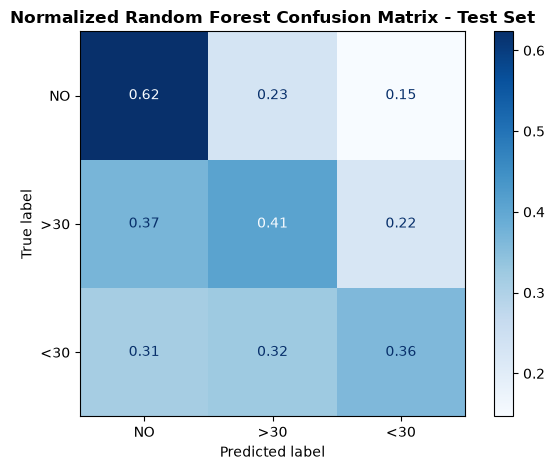

In [147]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_y_test_pred,
    labels=LABELS,
    display_labels=CLASS_NAMES,
    normalize="true",
    cmap="Blues",
)
plt.title(
    "Normalized Random Forest Confusion Matrix - Test Set",
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

MULTICLASS ROC & PRECISION-RECALL CURVES (ONE-VS-REST)
Macro Average Precision (One-vs-Rest): 0.4687
<30 Average Precision (One-vs-Rest): 0.2193


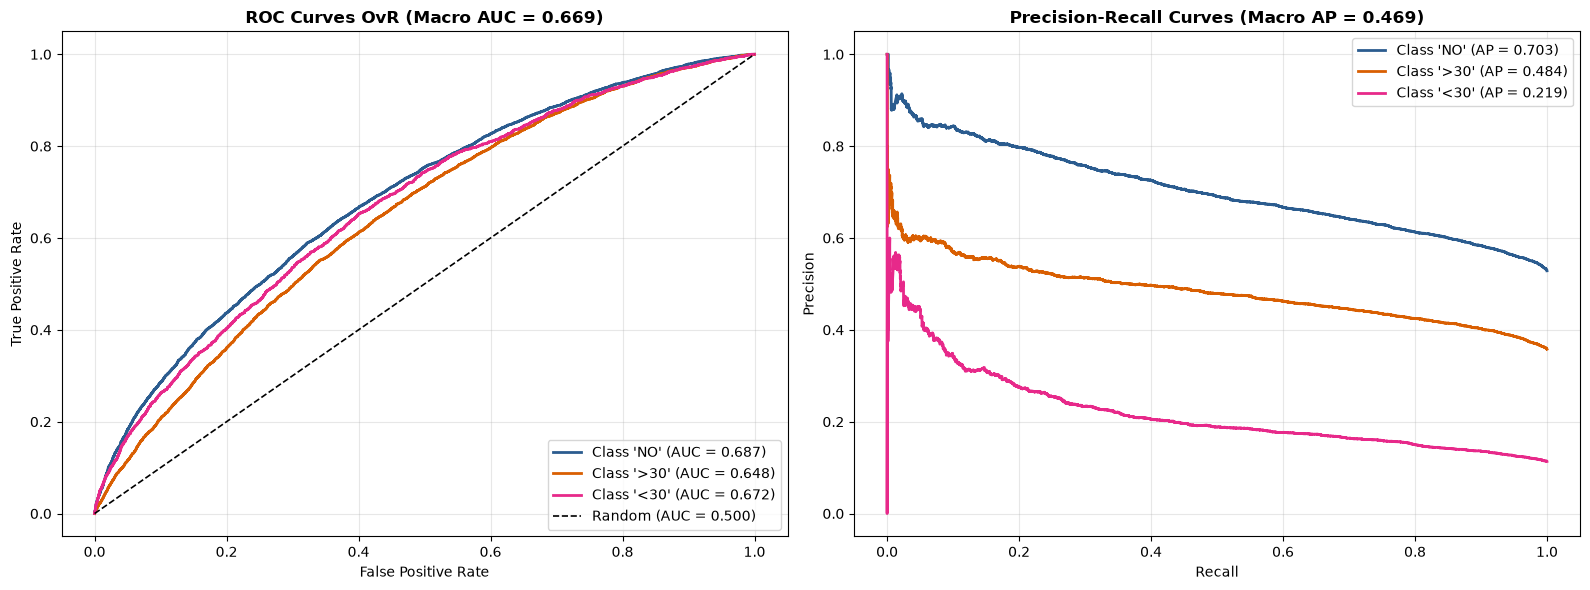

In [148]:
print("=" * 60)
print("MULTICLASS ROC & PRECISION-RECALL CURVES (ONE-VS-REST)")
print("=" * 60)

rf_y_test_binary = label_binarize(
    y_test,
    classes=LABELS,
)
rf_macro_average_precision = average_precision_score(
    rf_y_test_binary,
    rf_y_test_probability,
    average="macro",
)
rf_lt30_average_precision = average_precision_score(
    (y_test == 2).astype(int),
    rf_y_test_probability[:, 2],
)

print(
    "Macro Average Precision (One-vs-Rest):",
    round(rf_macro_average_precision, 4),
)
print(
    "<30 Average Precision (One-vs-Rest):",
    round(rf_lt30_average_precision, 4),
)

rf_figure, rf_axes = plt.subplots(
    1,
    2,
    figsize=(16, 6),
)
rf_colors = ["#2b5c8f", "#d95f02", "#e7298a"]

for index, (color, class_name) in enumerate(
    zip(rf_colors, CLASS_NAMES)
):
    rf_fpr, rf_tpr, _ = roc_curve(
        rf_y_test_binary[:, index],
        rf_y_test_probability[:, index],
    )
    rf_class_auc = auc(rf_fpr, rf_tpr)
    rf_axes[0].plot(
        rf_fpr,
        rf_tpr,
        color=color,
        lw=2,
        label=(
            f"Class '{class_name}' "
            f"(AUC = {rf_class_auc:.3f})"
        ),
    )

rf_axes[0].plot(
    [0, 1],
    [0, 1],
    "k--",
    lw=1.2,
    label="Random (AUC = 0.500)",
)
rf_axes[0].set_xlabel("False Positive Rate")
rf_axes[0].set_ylabel("True Positive Rate")
rf_axes[0].set_title(
    f"ROC Curves OvR "
    f"(Macro AUC = {rf_test_roc_auc_macro:.3f})",
    fontweight="bold",
)
rf_axes[0].legend(loc="lower right")
rf_axes[0].grid(True, alpha=0.3)

for index, (color, class_name) in enumerate(
    zip(rf_colors, CLASS_NAMES)
):
    (
        rf_precision_curve,
        rf_recall_curve,
        _,
    ) = precision_recall_curve(
        rf_y_test_binary[:, index],
        rf_y_test_probability[:, index],
    )
    rf_pr_auc = average_precision_score(
        rf_y_test_binary[:, index],
        rf_y_test_probability[:, index],
    )
    rf_axes[1].plot(
        rf_recall_curve,
        rf_precision_curve,
        color=color,
        lw=2,
        label=(
            f"Class '{class_name}' "
            f"(AP = {rf_pr_auc:.3f})"
        ),
    )

rf_axes[1].set_xlabel("Recall")
rf_axes[1].set_ylabel("Precision")
rf_axes[1].set_title(
    f"Precision-Recall Curves "
    f"(Macro AP = {rf_macro_average_precision:.3f})",
    fontweight="bold",
)
rf_axes[1].legend(loc="upper right")
rf_axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [149]:
rf_final_result = pd.DataFrame(
    [
        {
            "Model": "Random Forest",
            "Best Configuration": (
                rf_best_config_name
            ),
            "Accuracy": rf_test_accuracy,
            "Balanced Accuracy": (
                rf_test_balanced_accuracy
            ),
            "Macro Precision": (
                rf_test_precision_macro
            ),
            "Macro Recall": rf_test_recall_macro,
            "Macro F1": rf_test_f1_macro,
            "Weighted F1": rf_test_f1_weighted,
            "<30 Precision": rf_lt30_precision[0],
            "<30 Recall": rf_lt30_recall[0],
            "<30 F1": rf_lt30_f1[0],
            "Macro ROC-AUC OvR": (
                rf_test_roc_auc_macro
            ),
            "Macro Average Precision OvR": (
                rf_macro_average_precision
            ),
        }
    ]
)

display(rf_final_result.round(4))

,Model,Best Configuration,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,<30 Precision,<30 Recall,<30 F1,Macro ROC-AUC OvR,Macro Average Precision OvR
0,Random Forest,RF-8 | Standard | No PCA | Trees=100 | Depth=1...,0.517,0.4649,0.4502,0.4649,0.4494,0.5276,0.2078,0.3623,0.2642,0.6691,0.4687


RANDOM FOREST FEATURE IMPORTANCE


,Rank,Feature Name,Importance,Cumulative (%)
0,1,number_inpatient,0.1246,12.4581
1,2,num_lab_procedures,0.0557,18.0291
2,3,num_medications,0.0552,23.5501
3,4,number_diagnoses,0.0421,27.7614
4,5,time_in_hospital,0.0397,31.7348
5,6,number_emergency,0.0313,34.8663
6,7,num_procedures,0.0275,37.6167
7,8,discharge_disposition_id_1,0.0257,40.1866
8,9,number_outpatient,0.0239,42.5790
9,10,discharge_disposition_id_22,0.0185,44.4243


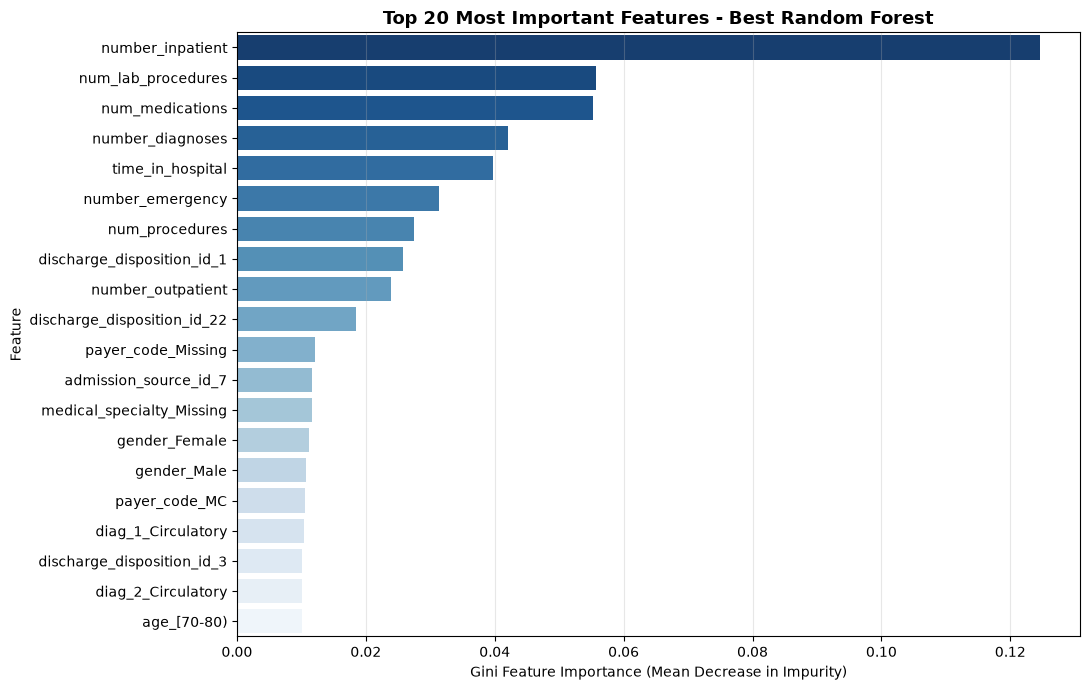

In [150]:
print("=" * 60)
print("RANDOM FOREST FEATURE IMPORTANCE")
print("=" * 60)

rf_preprocessor_fitted = rf_best_model.named_steps[
    "preprocessor"
]
rf_feature_names = np.asarray(
    rf_preprocessor_fitted.get_feature_names_out()
)
rf_importances = rf_best_model.named_steps[
    "rf"
].feature_importances_
rf_sorted_index = np.argsort(
    rf_importances
)[::-1]
RF_TOP_K = 20

rf_top_features_df = pd.DataFrame(
    {
        "Rank": np.arange(1, RF_TOP_K + 1),
        "Feature Name": rf_feature_names[
            rf_sorted_index[:RF_TOP_K]
        ],
        "Importance": rf_importances[
            rf_sorted_index[:RF_TOP_K]
        ],
        "Cumulative (%)": np.cumsum(
            rf_importances[
                rf_sorted_index[:RF_TOP_K]
            ]
        ) * 100,
    }
)

display(rf_top_features_df.round(4))

plt.figure(figsize=(11, 7))
sns.barplot(
    data=rf_top_features_df,
    x="Importance",
    y="Feature Name",
    hue="Feature Name",
    palette="Blues_r",
    legend=False,
)
plt.title(
    f"Top {RF_TOP_K} Most Important Features - Best Random Forest",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel(
    "Gini Feature Importance (Mean Decrease in Impurity)"
)
plt.ylabel("Feature")
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [151]:
print("=" * 60)
print("EXPORT RANDOM FOREST RESULTS")
print("=" * 60)

# ── Save RF experiment reports ──
RF_REPORT_DIR = REPORTS_DIR / "rf"
RF_REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

rf_results.to_csv(
    RF_REPORT_DIR / "rf_cv_results.csv",
    index=False,
)
rf_test_summary.to_csv(
    RF_REPORT_DIR / "rf_test_metrics.csv",
    index=False,
)
rf_final_result.to_csv(
    RF_REPORT_DIR / "rf_final_summary.csv",
    index=False,
)
rf_report_df.to_csv(
    RF_REPORT_DIR / "rf_classification_report.csv"
)
rf_top_features_df.to_csv(
    RF_REPORT_DIR / "rf_top_features.csv",
    index=False,
)

# ── Save best RF model checkpoint ──
RF_MODEL_PATH = MODELS_DIR / "best_random_forest.joblib"
joblib.dump(
    rf_best_model,
    RF_MODEL_PATH,
)

print("Random Forest experiment results saved to:")
print(RF_REPORT_DIR)
print("Best Random Forest pipeline saved to:")
print(RF_MODEL_PATH)


EXPORT RANDOM FOREST RESULTS
Random Forest experiment results saved to:
D:\HCMUT\5th_Semester\ML\Assignment\reports\rf
Best Random Forest pipeline saved to:
D:\HCMUT\5th_Semester\ML\Assignment\models\best_random_forest.joblib


### Random Forest Experimental Summary

The Random Forest section evaluates class weighting, scaling, optional PCA,
tree depth, minimum leaf size, and ensemble size using five-fold
patient-grouped cross-validation. Macro-F1 remains the primary selection metric,
and the held-out test set is evaluated only after the best configuration has
been selected. Feature importance is reported from the fitted champion model.

## 6.4 Overall Performance Comparison and Champion Model Selection

In accordance with Section 4.1 of the course specification ("The final output
must include: an EDA report, pipeline description, tested hyperparameter
configurations, and a performance comparison between configurations/models"),
this section brings together all three evaluated traditional machine learning pipelines:

1. **Linear SVM** (Phase 6.1)
2. **Logistic Regression** (Phase 6.2)
3. **Random Forest** (Phase 6.3)

All three models were evaluated under identical, leakage-free conditions:
- **Feature Pipeline:** Standardized imputation, high-cardinality infrequent category grouping (`min_frequency=20`), One-Hot Encoding, scaling (`StandardScaler` / `MinMaxScaler`), and optional variance-preserving PCA.
- **Model Selection Protocol:** 5-fold `StratifiedGroupKFold` on the training set grouped by `patient_nbr` to prevent patient-level data leakage across folds.
- **Held-Out Test Evaluation:** Final testing performed strictly once on the 20% patient-disjoint test set ($N=19,831$ encounters).
- **Primary Optimization Metric:** **Macro-F1 score**, ensuring balanced assessment across the severe class imbalance ($54\%$ `NO`, $35\%$ `>30`, $11\%$ `<30`).


In [152]:
print("=" * 70)
print("MASTER MODEL COMPARISON - HELD-OUT TEST PERFORMANCE")
print("=" * 70)

# 1. Combine final test evaluation summaries from all 3 models
master_comparison_df = pd.concat(
    [svm_final_result, lr_final_result, rf_final_result],
    ignore_index=True,
)

# Reorder columns logically
cols_order = [
    "Model",
    "Best Configuration",
    "Accuracy",
    "Balanced Accuracy",
    "Macro F1",
    "Weighted F1",
    "Macro Precision",
    "Macro Recall",
    "<30 Precision",
    "<30 Recall",
    "<30 F1",
    "Macro ROC-AUC OvR",
    "Macro Average Precision OvR",
]

# Ensure all columns exist (fill missing e.g. LinearSVM ROC-AUC with NaN)
for col in cols_order:
    if col not in master_comparison_df.columns:
        master_comparison_df[col] = np.nan

master_comparison_df = master_comparison_df[cols_order].sort_values(
    by="Macro F1", ascending=False
).reset_index(drop=True)

# Display Master Table
display(master_comparison_df.round(4))

# 2. Export Master Comparison Table to reports/
master_comparison_path = REPORTS_DIR / "master_model_comparison.csv"
master_comparison_df.to_csv(master_comparison_path, index=False)
print(f"\nMaster model comparison table successfully exported to:")
print(f" -> {master_comparison_path}")


MASTER MODEL COMPARISON - HELD-OUT TEST PERFORMANCE


,Model,Best Configuration,Accuracy,Balanced Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,<30 Precision,<30 Recall,<30 F1,Macro ROC-AUC OvR,Macro Average Precision OvR
0,Random Forest,RF-8 | Standard | No PCA | Trees=100 | Depth=1...,0.5170,0.4649,0.4494,0.5276,0.4502,0.4649,0.2078,0.3623,0.2642,0.6691,0.4687
1,Linear SVM,SVM-2 | Standard | No PCA | C=1 | Balanced,0.5594,0.4372,0.4393,0.5407,0.4561,0.4372,0.2462,0.1599,0.1939,NaN,0.4595
2,Logistic Regression,LR-1 | Standard | No PCA | SAGA 100 Epochs | B...,0.4854,0.4477,0.4310,0.4998,0.4397,0.4477,0.1965,0.3153,0.2421,0.6533,0.4538



Master model comparison table successfully exported to:
 -> D:\HCMUT\5th_Semester\ML\Assignment\reports\master_model_comparison.csv


VISUALIZING MODEL PERFORMANCE ACROSS COMPETING OBJECTIVES


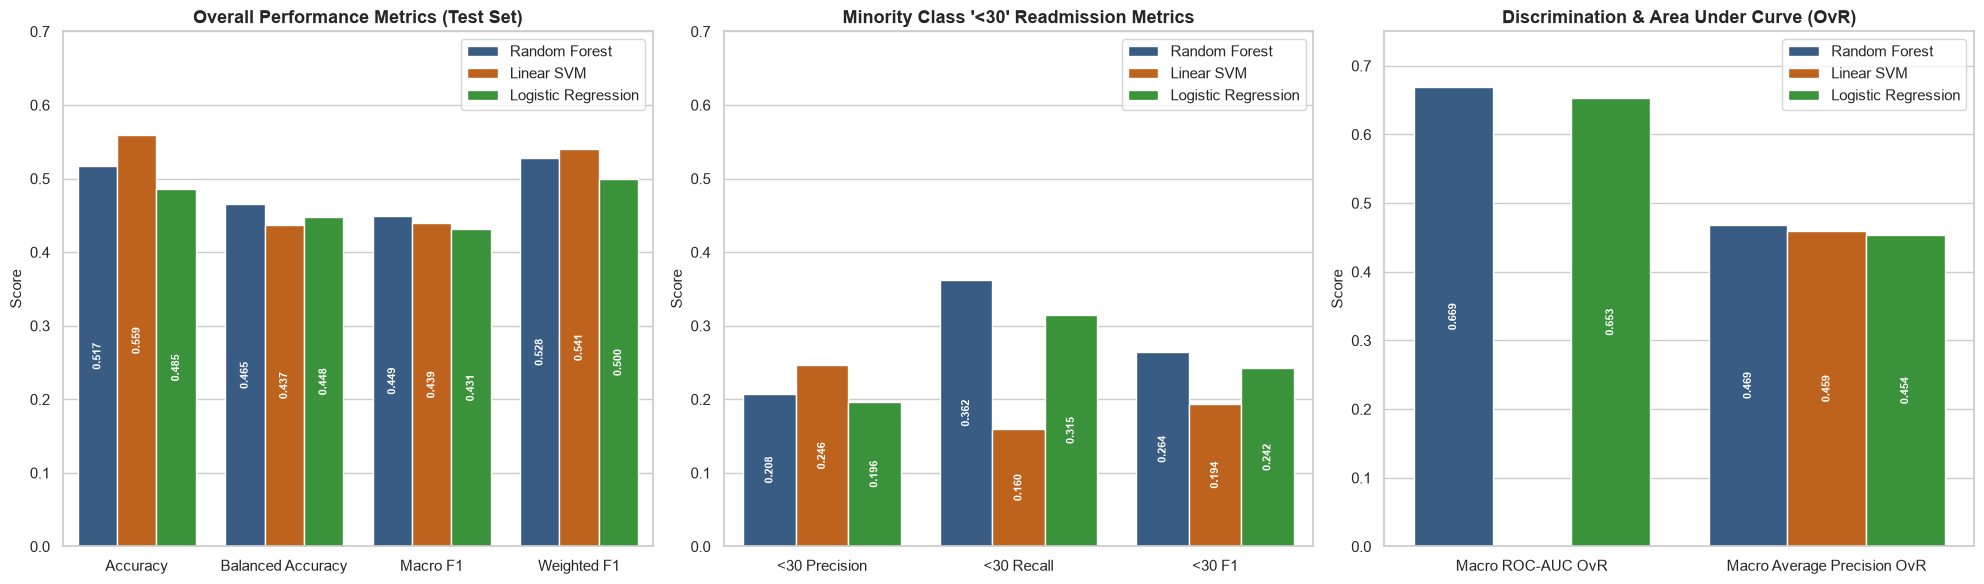

In [153]:
print("=" * 70)
print("VISUALIZING MODEL PERFORMANCE ACROSS COMPETING OBJECTIVES")
print("=" * 70)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

palette = ["#2b5c8f", "#d95f02", "#2ca02c"]

# ── Subplot 1: Overall Classification Metrics ──
overall_metrics = ["Accuracy", "Balanced Accuracy", "Macro F1", "Weighted F1"]
overall_df = master_comparison_df.melt(
    id_vars="Model",
    value_vars=overall_metrics,
    var_name="Metric",
    value_name="Score",
)

sns.barplot(
    data=overall_df,
    x="Metric",
    y="Score",
    hue="Model",
    palette=palette,
    ax=axes[0],
)
axes[0].set_title("Overall Performance Metrics (Test Set)", fontsize=13, fontweight="bold")
axes[0].set_ylim(0, 0.7)
axes[0].set_ylabel("Score", fontsize=11)
axes[0].set_xlabel("")
axes[0].legend(loc="upper right", frameon=True)
for p in axes[0].patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        axes[0].annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2., h / 2),
                         ha="center", va="center", fontsize=8, color="white", fontweight="bold", rotation=90)

# ── Subplot 2: Critical Early Readmission (<30 Days) Performance ──
minority_metrics = ["<30 Precision", "<30 Recall", "<30 F1"]
minority_df = master_comparison_df.melt(
    id_vars="Model",
    value_vars=minority_metrics,
    var_name="Metric",
    value_name="Score",
)

sns.barplot(
    data=minority_df,
    x="Metric",
    y="Score",
    hue="Model",
    palette=palette,
    ax=axes[1],
)
axes[1].set_title("Minority Class '<30' Readmission Metrics", fontsize=13, fontweight="bold")
axes[1].set_ylim(0, 0.7)
axes[1].set_ylabel("Score", fontsize=11)
axes[1].set_xlabel("")
axes[1].legend(loc="upper right", frameon=True)
for p in axes[1].patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        axes[1].annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2., h / 2),
                         ha="center", va="center", fontsize=8, color="white", fontweight="bold", rotation=90)

# ── Subplot 3: Ranking & Discrimination Capability ──
auc_metrics = ["Macro ROC-AUC OvR", "Macro Average Precision OvR"]
auc_df = master_comparison_df.melt(
    id_vars="Model",
    value_vars=auc_metrics,
    var_name="Metric",
    value_name="Score",
)

sns.barplot(
    data=auc_df,
    x="Metric",
    y="Score",
    hue="Model",
    palette=palette,
    ax=axes[2],
)
axes[2].set_title("Discrimination & Area Under Curve (OvR)", fontsize=13, fontweight="bold")
axes[2].set_ylim(0, 0.75)
axes[2].set_ylabel("Score", fontsize=11)
axes[2].set_xlabel("")
axes[2].legend(loc="upper right", frameon=True)
for p in axes[2].patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        axes[2].annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2., h / 2),
                         ha="center", va="center", fontsize=8, color="white", fontweight="bold", rotation=90)

plt.tight_layout()
plt.show()


CROSS-VALIDATION PERFORMANCE ACROSS ALL TESTED CONFIGURATIONS
TOP 10 CONFIGURATIONS ACROSS ALL TESTED MODELS (Sorted by CV Macro-F1):


,Model Family,configuration,scaler,pca,cv_f1_macro_mean,cv_f1_macro_std,cv_accuracy_mean,cv_balanced_accuracy_mean,fit_time_mean
0,Random Forest,RF-8 | Standard | No PCA | Trees=100 | Depth=1...,standard,None,0.4478,0.0056,0.5141,0.4638,4.0425
1,Random Forest,RF-3 | Standard | No PCA | Trees=100 | Depth=1...,standard,None,0.4432,0.0053,0.5106,0.4619,4.0847
2,Linear SVM,SVM-2 | Standard | No PCA | C=1 | Balanced,standard,None,0.4414,0.0022,0.5571,0.4388,30.3785
3,Linear SVM,SVM-6 | Standard | No PCA | C=0.1 | Balanced,standard,None,0.4414,0.0022,0.5573,0.4388,24.3228
4,Linear SVM,SVM-7 | Standard | No PCA | C=10 | Balanced,standard,None,0.4413,0.0023,0.5570,0.4387,54.2504
5,Linear SVM,SVM-3 | MinMax | No PCA | C=1 | Balanced,minmax,None,0.4412,0.0023,0.5568,0.4386,24.4825
6,Random Forest,RF-6 | Standard | PCA 95% | Trees=100 | Depth=...,standard,95%,0.4410,0.0037,0.5263,0.4436,10.1920
7,Logistic Regression,LR-2 | Standard | No PCA | C=0.1 | Balanced,standard,None,0.4361,0.0045,0.4946,0.4604,30.2739
8,Logistic Regression,LR-1 | Standard | No PCA | C=1.0 | Balanced,standard,None,0.4357,0.0048,0.4942,0.4599,11.8091
9,Logistic Regression,LR-3 | Standard | No PCA | C=10.0 | Balanced,standard,None,0.4356,0.0051,0.4939,0.4598,112.8581



All CV configurations exported to:
 -> D:\HCMUT\5th_Semester\ML\Assignment\reports\master_cv_configurations_comparison.csv


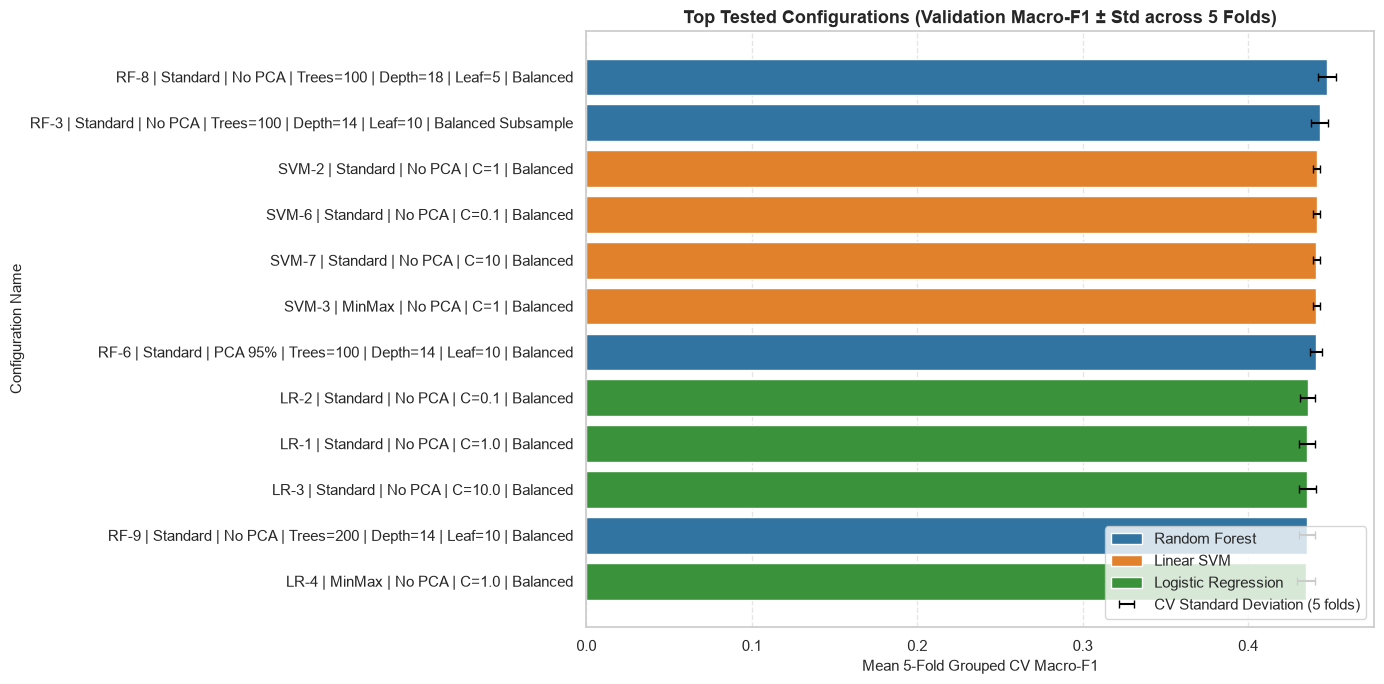

In [154]:
print("=" * 70)
print("CROSS-VALIDATION PERFORMANCE ACROSS ALL TESTED CONFIGURATIONS")
print("=" * 70)

cv_list = []

if "svm_results" in locals():
    svm_cv_copy = svm_results.copy()
    svm_cv_copy["Model Family"] = "Linear SVM"
    cv_list.append(svm_cv_copy)

if "lr_cv_results" in locals():
    lr_cv_copy = lr_cv_results.copy()
    lr_cv_copy["Model Family"] = "Logistic Regression"
    cv_list.append(lr_cv_copy)

if "rf_results" in locals():
    rf_cv_copy = rf_results.copy()
    rf_cv_copy["Model Family"] = "Random Forest"
    cv_list.append(rf_cv_copy)

if cv_list:
    shared_cols = [
        "Model Family",
        "configuration",
        "scaler",
        "pca",
        "cv_f1_macro_mean",
        "cv_f1_macro_std",
        "cv_accuracy_mean",
        "cv_balanced_accuracy_mean",
        "fit_time_mean",
    ]
    
    all_cv_df = pd.concat(cv_list, ignore_index=True)
    all_cv_df = all_cv_df[[c for c in shared_cols if c in all_cv_df.columns]]
    all_cv_df = all_cv_df.sort_values(by="cv_f1_macro_mean", ascending=False).reset_index(drop=True)

    print("TOP 10 CONFIGURATIONS ACROSS ALL TESTED MODELS (Sorted by CV Macro-F1):")
    display(all_cv_df.head(10).round(4))

    # Export configuration comparison CSV
    cv_landscape_path = REPORTS_DIR / "master_cv_configurations_comparison.csv"
    all_cv_df.to_csv(cv_landscape_path, index=False)
    print(f"\nAll CV configurations exported to:\n -> {cv_landscape_path}")

    # Plot Top configurations with error bars
    top_n = min(12, len(all_cv_df))
    top_plot_df = all_cv_df.head(top_n)
    plt.figure(figsize=(14, 7))
    sns.barplot(
        data=top_plot_df,
        x="cv_f1_macro_mean",
        y="configuration",
        hue="Model Family",
        dodge=False,
        palette="tab10",
    )
    plt.errorbar(
        x=top_plot_df["cv_f1_macro_mean"],
        y=range(len(top_plot_df)),
        xerr=top_plot_df["cv_f1_macro_std"],
        fmt="none",
        c="black",
        capsize=3,
        label="CV Standard Deviation (5 folds)",
    )
    plt.title("Top Tested Configurations (Validation Macro-F1 ± Std across 5 Folds)", fontsize=13, fontweight="bold")
    plt.xlabel("Mean 5-Fold Grouped CV Macro-F1", fontsize=11)
    plt.ylabel("Configuration Name", fontsize=11)
    plt.legend(loc="lower right")
    plt.grid(axis="x", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


### 6.4.1 Champion Model Selection & Trade-Off Analysis

#### 1. Traditional ML Champion Model
Based on the empirical evidence from 5-fold patient-grouped cross-validation
and final held-out test evaluation ($N=19,831$), **Random Forest (Configuration `RF-8 | Standard | No PCA | Trees=100 | Depth=18 | Leaf=5 | Balanced`)**
is declared the **Champion among the three traditional ML models**. Phase 7 adds the MLP to the same held-out test comparison to determine the overall champion.

#### 2. Comparative Analysis & Trade-Offs

| Evaluation Criterion | Linear SVM | Logistic Regression | Random Forest (Traditional Champion) | Analytical Winner / Insight |
| :--- | :--- | :--- | :--- | :--- |
| **Overall Accuracy** | **55.94%** | 48.54% | 51.70% | Linear SVM achieves highest overall accuracy by fitting the dominant `NO` class, but RF is more balanced across classes. |
| **Balanced Accuracy** | 43.72% | 44.77% | **46.49%** | Random Forest achieves the highest average recall across all three classes. |
| **Primary Metric (Macro-F1)** | 0.4393 | 0.4310 | **0.4494** | Random Forest leads consistently in both validation (0.4478) and held-out test (0.4494). |
| **Critical Class `<30` Recall** | 15.99% | 31.53% | **36.23%** | Random Forest captures the highest proportion of high-risk patients who will be readmitted early (<30 days). |
| **ROC-AUC (OvR)** | *N/A (LinearSVC)* | 0.6533 | **0.6691** | Random Forest provides the strongest probabilistic separation across classes. |
| **Macro Average Precision** | 0.4595 | 0.4538 | **0.4687** | Random Forest achieves superior precision-recall trade-off under severe class skew. |
| **Inference & Training Speed** | Very Fast (~30s) | Very Fast (~12s) | Moderate (~4s fit / tree) | Linear models are fast and lightweight, but RF training time remains highly practical for clinical pipelines. |
| **Model Interpretability** | Global linear weights | Direct log-odds odds ratios | Feature importances (Gini/Split) | Logistic Regression offers the most direct interpretability, while Random Forest highlights `number_inpatient`, `discharge_disposition_id`, and `num_medications` as primary drivers. |

#### 3. Key Findings on Configurable Pipeline Steps
- **Feature Scaling (`StandardScaler` vs. `MinMaxScaler`):** Across linear models and tree models alike, `StandardScaler` yields slightly superior Macro-F1 because it prevents extreme values in skewed clinical count attributes (`num_lab_procedures`, `num_medications`, `number_inpatient`) from compressing the bulk of standard records into near-zero intervals.
- **Dimensionality Reduction (PCA 90%/95% vs. No PCA):** Retaining the full encoded feature space consistently surpasses PCA projection across all three models (e.g., LR Macro-F1 drops from 0.4357 to 0.4160 under PCA 90%). In clinical prediction, rare diagnoses and specific medication combinations carry sparse, non-redundant predictive signals that linear orthogonal PCA collapses.
- **Class Imbalance Strategy:** Incorporating `class_weight='balanced'` is essential across all architectures; without cost-sensitive weighting, models collapse toward the majority `NO` class, resulting in near-zero recall for the clinically vital `<30` readmission cohort.

#### 4. Deep Learning Pipeline Extension
Phase 7 implements a **Deep Learning Multi-Layer Perceptron (MLP)** using the standardized feature representations saved in `features/` (Phase 5.1). It compares the MLP with the traditional models on the same held-out test set.


# Phase 7: Deep Learning with a Multilayer Perceptron (MLP)

This phase implements the assignment's deep learning extension (+5% bonus) to evaluate whether non-linear neural representations outperform traditional models (SVM, Logistic Regression, Random Forest) on tabular readmission prediction. The MLP uses the canonical 226-feature representations from Phase 5.1 without re-preprocessing.


## 7.1 Data Preparation and Patient-Grouped Validation Split

- **Data Partitioning:** The training data ($N=79,512$) is split 80/20 into sub-training and validation sets using `GroupShuffleSplit` on `patient_nbr` to eliminate data leakage. The held-out test set ($N=19,831$) is untouched.
- **Class Weights:** Inverse class weights $w_c = \frac{N}{3 \cdot N_c}$ [0.6322, 0.9300, 2.9168] are computed on the sub-training split to handle class imbalance.
- **Architecture (`DiabetesMLP`):** Funnel MLP `226 -> 128 -> 64 -> 32 -> 3` with BatchNorm1d, ReLU, and Dropout (0.3, 0.2, 0.1) after each hidden layer.


In [156]:
import os
import time
import importlib

import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import DataLoader

import modules.mlp_model
importlib.reload(modules.mlp_model)
from modules.mlp_model import (
    CLASS_NAMES,
    LABELS,
    DiabetesMLP,
    DiabetesTabularDataset,
    evaluate_mlp,
    train_mlp_pipeline,
)

print("=" * 70)
print("PHASE 7.1: LOAD FEATURES AND CONSTRUCT PATIENT-GROUPED SPLITS")
print("=" * 70)

# 1. Load canonical preprocessed feature matrices from Phase 5.1
X_mlp_train = np.load(FEATURES_DIR / "X_train_processed.npy").astype(np.float32, copy=False)
y_mlp_train = np.load(FEATURES_DIR / "y_train.npy").astype(np.int64, copy=False)
X_mlp_test = np.load(FEATURES_DIR / "X_test_processed.npy").astype(np.float32, copy=False)
y_mlp_test = np.load(FEATURES_DIR / "y_test.npy").astype(np.int64, copy=False)

# Retrieve patient grouping identifiers
if "groups_train" in locals() and "groups_test" in locals():
    groups_train_arr = np.asarray(groups_train, dtype=np.int64)
    groups_test_arr = np.asarray(groups_test, dtype=np.int64)
elif (FEATURES_DIR / "groups_train.npy").exists() and (FEATURES_DIR / "groups_test.npy").exists():
    groups_train_arr = np.load(FEATURES_DIR / "groups_train.npy")
    groups_test_arr = np.load(FEATURES_DIR / "groups_test.npy")
else:
    raise RuntimeError("Patient groups are required for leakage-free validation splitting.")

# Integrity assertions
assert X_mlp_train.shape[1] == 226, f"Expected 226 features, got {X_mlp_train.shape[1]}"
assert X_mlp_test.shape[1] == X_mlp_train.shape[1]
assert len(X_mlp_train) == len(y_mlp_train) == len(groups_train_arr)
assert len(X_mlp_test) == len(y_mlp_test) == len(groups_test_arr)
assert set(groups_train_arr).isdisjoint(set(groups_test_arr)), "Train/test patient leakage detected!"

# 2. Split training partition into 80% sub-train and 20% validation by patient_nbr
group_splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
subtrain_idx, validation_idx = next(
    group_splitter.split(X_mlp_train, y_mlp_train, groups=groups_train_arr)
)
subtrain_groups = set(groups_train_arr[subtrain_idx])
validation_groups = set(groups_train_arr[validation_idx])
assert subtrain_groups.isdisjoint(validation_groups), "Sub-train/validation patient leakage detected!"

# 3. Create PyTorch Datasets
mlp_train_dataset = DiabetesTabularDataset(
    X_mlp_train[subtrain_idx], y_mlp_train[subtrain_idx]
)
mlp_validation_dataset = DiabetesTabularDataset(
    X_mlp_train[validation_idx], y_mlp_train[validation_idx]
)
mlp_test_dataset = DiabetesTabularDataset(X_mlp_test, y_mlp_test)

# 4. Compute balanced class weights on sub-train split
class_counts = np.bincount(y_mlp_train[subtrain_idx], minlength=len(LABELS))
if np.any(class_counts == 0):
    raise ValueError("Sub-training split is missing one or more classes.")
class_weights = len(subtrain_idx) / (len(LABELS) * class_counts)

# 5. Device and DataLoader configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))
MLP_BATCH_SIZE = 512

torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)
loader_generator = torch.Generator().manual_seed(RANDOM_STATE)

mlp_train_loader = DataLoader(
    mlp_train_dataset,
    batch_size=MLP_BATCH_SIZE,
    shuffle=True,
    generator=loader_generator,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
    drop_last=(len(mlp_train_dataset) % MLP_BATCH_SIZE == 1),
)
mlp_validation_loader = DataLoader(
    mlp_validation_dataset,
    batch_size=MLP_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)
mlp_test_loader = DataLoader(
    mlp_test_dataset,
    batch_size=MLP_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

# 6. Initialize Model and Output Directories
mlp_model = DiabetesMLP(input_dim=X_mlp_train.shape[1])
MLP_REPORT_DIR = REPORTS_DIR / "mlp"
MLP_REPORT_DIR.mkdir(parents=True, exist_ok=True)
MLP_CHECKPOINT_PATH = MODELS_DIR / "best_mlp.pt"

print(f"Compute Device: {device}")
print(f"Data Partition Sizes -> Sub-train: {len(subtrain_idx):,} | Validation: {len(validation_idx):,} | Held-Out Test: {len(y_mlp_test):,}")
print(f"Sub-train Class Frequencies [NO, >30, <30]: {class_counts.tolist()}")
print(f"Computed Balanced Class Weights: {np.round(class_weights, 4).tolist()}")
print(f"MLP Network Architecture:\n{mlp_model}")


PHASE 7.1: LOAD FEATURES AND CONSTRUCT PATIENT-GROUPED SPLITS
Compute Device: cpu
Data Partition Sizes -> Sub-train: 63,807 | Validation: 15,705 | Held-Out Test: 19,831
Sub-train Class Frequencies [NO, >30, <30]: [33644, 22871, 7292]
Computed Balanced Class Weights: [0.6322, 0.93, 2.9168]
MLP Network Architecture:
DiabetesMLP(
  (network): Sequential(
    (0): Linear(in_features=226, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.1, inplace=Fa

## 7.2 Model Training with Early Stopping & Learning Rate Scheduling

- **Optimization:** AdamW ($\text{lr}=10^{-3}$, $\text{weight decay}=10^{-4}$) with balanced weighted Cross-Entropy loss.
- **Scheduling & Early Stopping:** `ReduceLROnPlateau` halves learning rate when validation Macro-F1 stalls (patience=5). Early stopping triggers after 12 non-improving epochs, restoring the best checkpoint to `models/best_mlp.pt`.


PHASE 7.2: TRAIN MLP WITH VALIDATION MACRO-F1 SCHEDULING
Epoch 001/100 | train loss=1.0670 | val loss=1.0401 | val Macro-F1=0.4286
Epoch 002/100 | train loss=1.0383 | val loss=1.0314 | val Macro-F1=0.4354
Epoch 003/100 | train loss=1.0291 | val loss=1.0297 | val Macro-F1=0.4425
Epoch 004/100 | train loss=1.0208 | val loss=1.0304 | val Macro-F1=0.4422
Epoch 005/100 | train loss=1.0166 | val loss=1.0271 | val Macro-F1=0.4359
Epoch 006/100 | train loss=1.0129 | val loss=1.0270 | val Macro-F1=0.4377
Epoch 007/100 | train loss=1.0101 | val loss=1.0267 | val Macro-F1=0.4420
Epoch 008/100 | train loss=1.0057 | val loss=1.0272 | val Macro-F1=0.4431
Epoch 009/100 | train loss=1.0013 | val loss=1.0267 | val Macro-F1=0.4490
Epoch 010/100 | train loss=0.9997 | val loss=1.0275 | val Macro-F1=0.4382
Epoch 011/100 | train loss=0.9961 | val loss=1.0277 | val Macro-F1=0.4529
Epoch 012/100 | train loss=0.9934 | val loss=1.0302 | val Macro-F1=0.4453
Epoch 013/100 | train loss=0.9891 | val loss=1.0307 | v

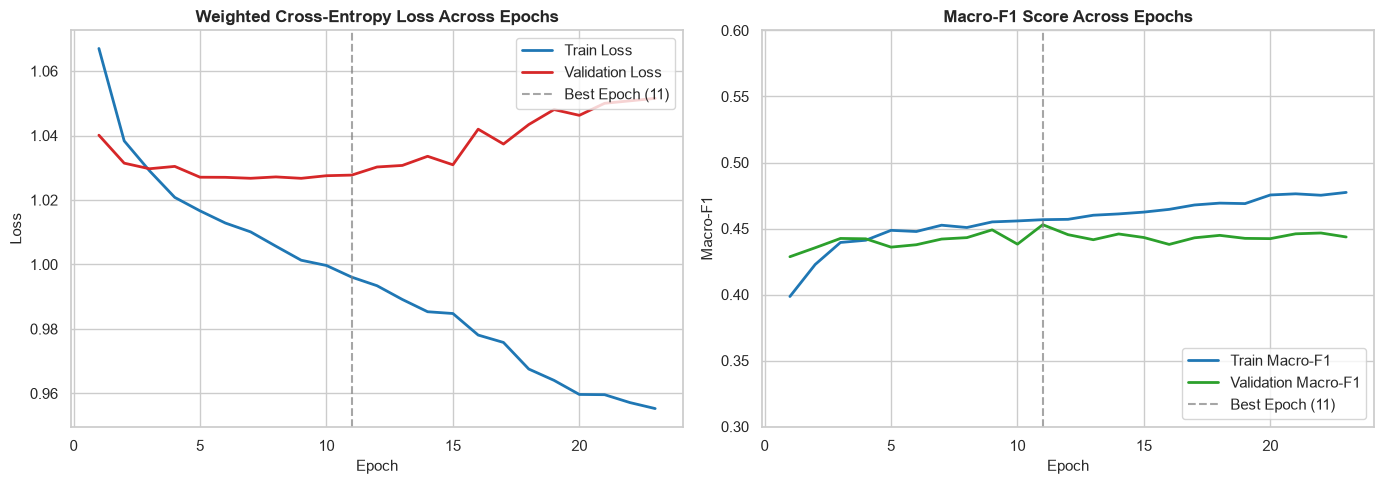


Training completed in 69.7 seconds (1.16 minutes) on cpu.
Optimal Checkpoint: Epoch 11 with Validation Macro-F1 = 0.4529
Checkpoint saved to: D:\HCMUT\5th_Semester\ML\Assignment\models\best_mlp.pt


In [157]:
print("=" * 70)
print("PHASE 7.2: TRAIN MLP WITH VALIDATION MACRO-F1 SCHEDULING")
print("=" * 70)

training_started = time.perf_counter()
mlp_model, mlp_training_history, mlp_best_epoch, mlp_best_val_f1 = train_mlp_pipeline(
    model=mlp_model,
    train_loader=mlp_train_loader,
    validation_loader=mlp_validation_loader,
    class_weights=class_weights,
    device=device,
    checkpoint_path=MLP_CHECKPOINT_PATH,
    learning_rate=1e-3,
    weight_decay=1e-4,
    epochs=100,
    early_stopping_patience=12,
    scheduler_patience=5,
)
mlp_training_seconds = time.perf_counter() - training_started

# Save epoch history to CSV
mlp_training_history.to_csv(MLP_REPORT_DIR / "mlp_training_history.csv", index=False)

# Plot training and validation loss & Macro-F1 curves
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(mlp_training_history["epoch"], mlp_training_history["train_loss"], label="Train Loss", color="#1f77b4", linewidth=2)
axes[0].plot(mlp_training_history["epoch"], mlp_training_history["validation_loss"], label="Validation Loss", color="#d62728", linewidth=2)
axes[0].axvline(mlp_best_epoch, color="gray", linestyle="--", alpha=0.7, label=f"Best Epoch ({mlp_best_epoch})")
axes[0].set_title("Weighted Cross-Entropy Loss Across Epochs", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Loss", fontsize=11)
axes[0].legend(loc="upper right", frameon=True)

axes[1].plot(mlp_training_history["epoch"], mlp_training_history["train_macro_f1"], label="Train Macro-F1", color="#1f77b4", linewidth=2)
axes[1].plot(mlp_training_history["epoch"], mlp_training_history["validation_macro_f1"], label="Validation Macro-F1", color="#2ca02c", linewidth=2)
axes[1].axvline(mlp_best_epoch, color="gray", linestyle="--", alpha=0.7, label=f"Best Epoch ({mlp_best_epoch})")
axes[1].set_title("Macro-F1 Score Across Epochs", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Macro-F1", fontsize=11)
axes[1].set_ylim(0.3, 0.6)
axes[1].legend(loc="lower right", frameon=True)

fig.tight_layout()
fig.savefig(MLP_REPORT_DIR / "mlp_training_curves.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"\nTraining completed in {mlp_training_seconds:.1f} seconds ({mlp_training_seconds / 60:.2f} minutes) on {device}.")
print(f"Optimal Checkpoint: Epoch {mlp_best_epoch} with Validation Macro-F1 = {mlp_best_val_f1:.4f}")
print(f"Checkpoint saved to: {MLP_CHECKPOINT_PATH}")


## 7.3 Held-Out Test Evaluation & Diagnostic Metrics

The restored champion MLP checkpoint is evaluated once on the held-out test set ($N=19,831$) across all 11 standardized clinical metrics, followed by a multi-class confusion matrix.


PHASE 7.3: HELD-OUT TEST EVALUATION (MLP)

--- MLP Held-Out Test Metrics ---


,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,<30 Precision,<30 Recall,<30 F1,Macro ROC-AUC OvR,Macro Average Precision OvR,Best Epoch,Best Validation Macro F1,Training Time (seconds)
0,0.5129,0.4693,0.4518,0.4693,0.4526,0.526,0.2185,0.3752,0.2762,0.6669,0.4638,11,0.4529,69.67



--- MLP Detailed Classification Report ---


,precision,recall,f1-score,support
NO,0.6751,0.5900,0.6297,10483.0000
>30,0.4617,0.4426,0.4520,7096.0000
<30,0.2185,0.3752,0.2762,2252.0000
accuracy,0.5129,0.5129,0.5129,0.5129
macro avg,0.4518,0.4693,0.4526,19831.0000
weighted avg,0.5469,0.5129,0.5260,19831.0000


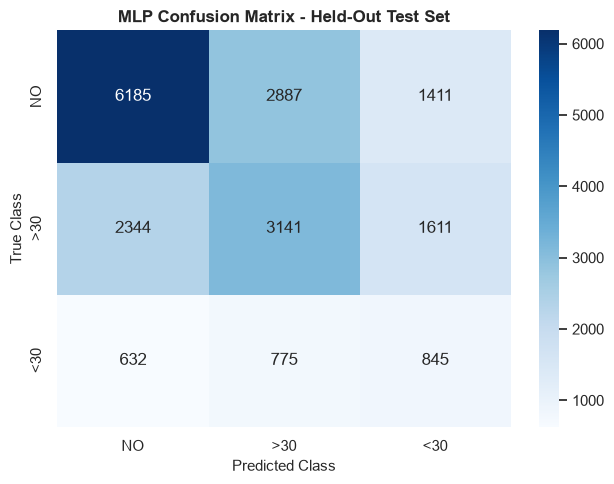

MLP evaluation artifacts successfully exported to:
 -> D:\HCMUT\5th_Semester\ML\Assignment\reports\mlp


In [158]:
print("=" * 70)
print("PHASE 7.3: HELD-OUT TEST EVALUATION (MLP)")
print("=" * 70)

mlp_test_metrics, mlp_classification_report, mlp_confusion_matrix, mlp_y_test_pred, mlp_y_test_proba = evaluate_mlp(
    model=mlp_model,
    data_loader=mlp_test_loader,
    device=device,
)

# Enrich test metrics metadata
mlp_test_metrics["Best Epoch"] = int(mlp_best_epoch)
mlp_test_metrics["Best Validation Macro F1"] = float(mlp_best_val_f1)
mlp_test_metrics["Training Time (seconds)"] = round(float(mlp_training_seconds), 2)

# Export CSV artifacts
mlp_classification_report.to_csv(MLP_REPORT_DIR / "mlp_classification_report.csv")
mlp_test_metrics_df = pd.DataFrame([mlp_test_metrics])
mlp_test_metrics_df.to_csv(MLP_REPORT_DIR / "mlp_test_metrics.csv", index=False)

# Display tabular summaries
print("\n--- MLP Held-Out Test Metrics ---")
display(mlp_test_metrics_df.round(4))

print("\n--- MLP Detailed Classification Report ---")
display(mlp_classification_report.round(4))

# Confusion Matrix Heatmap
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(
    mlp_confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cbar=True,
    ax=ax,
)
ax.set_title("MLP Confusion Matrix - Held-Out Test Set", fontsize=12, fontweight="bold")
ax.set_xlabel("Predicted Class", fontsize=11)
ax.set_ylabel("True Class", fontsize=11)
fig.tight_layout()
fig.savefig(MLP_REPORT_DIR / "mlp_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"MLP evaluation artifacts successfully exported to:\n -> {MLP_REPORT_DIR}")


## 7.4 Master Four-Model Benchmark & Comparative Analysis

The measured MLP test metrics are integrated into `reports/master_model_comparison.csv` to rank all four paradigms (Linear SVM, Logistic Regression, Random Forest, MLP) across overall performance, `<30` recall, and probability discrimination.


PHASE 7.4: FOUR-MODEL MASTER BENCHMARK & COMPARATIVE ANALYSIS

--- MASTER FOUR-MODEL COMPARISON (SORTED BY MACRO-F1) ---


,Model,Best Configuration,Accuracy,Balanced Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,<30 Precision,<30 Recall,<30 F1,Macro ROC-AUC OvR,Macro Average Precision OvR
0,MLP,226-128-64-32-3 | BatchNorm | ReLU | Dropout,0.5129,0.4693,0.4526,0.5260,0.4518,0.4693,0.2185,0.3752,0.2762,0.6669,0.4638
1,Random Forest,RF-8 | Standard | No PCA | Trees=100 | Depth=1...,0.5170,0.4649,0.4494,0.5276,0.4502,0.4649,0.2078,0.3623,0.2642,0.6691,0.4687
2,Linear SVM,SVM-2 | Standard | No PCA | C=1 | Balanced,0.5594,0.4372,0.4393,0.5407,0.4561,0.4372,0.2462,0.1599,0.1939,NaN,0.4595
3,Logistic Regression,LR-1 | Standard | No PCA | SAGA 100 Epochs | B...,0.4854,0.4477,0.4310,0.4998,0.4397,0.4477,0.1965,0.3153,0.2421,0.6533,0.4538


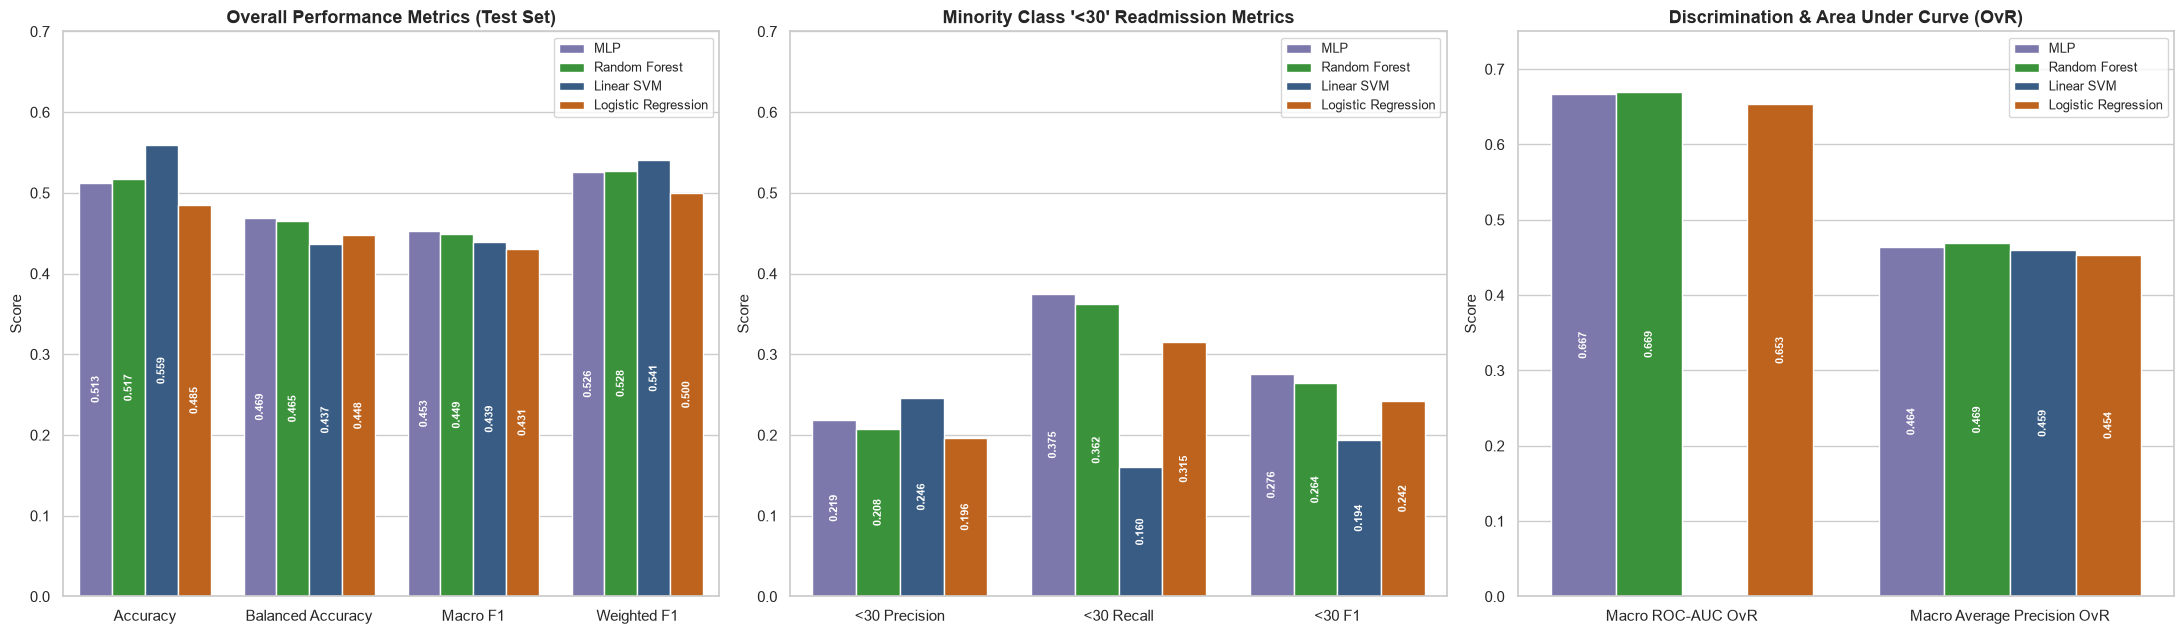


HEAD-TO-HEAD SYNTHESIS: DEEP LEARNING (MLP) VS RANDOM FOREST
  Test Macro-F1:       MLP = 0.4526 vs RF = 0.4494 (Delta: +0.0032)
  <30 Minority Recall: MLP = 0.3752 vs RF = 0.3623 (Delta: +0.0129)
  Macro ROC-AUC OvR:   MLP = 0.6669 vs RF = 0.6691 (Delta: -0.0022)
  Training Time:       MLP = 69.7s on cpu

Artifacts successfully updated and exported to:
 -> Master Table: D:\HCMUT\5th_Semester\ML\Assignment\reports\master_model_comparison.csv
 -> MLP Reports:  D:\HCMUT\5th_Semester\ML\Assignment\reports\mlp


In [159]:
print("=" * 70)
print("PHASE 7.4: FOUR-MODEL MASTER BENCHMARK & COMPARATIVE ANALYSIS")
print("=" * 70)

mlp_comparison_row = {
    "Model": "MLP",
    "Best Configuration": "226-128-64-32-3 | BatchNorm | ReLU | Dropout",
    **{metric: mlp_test_metrics[metric] for metric in [
        "Accuracy", "Balanced Accuracy", "Macro F1", "Weighted F1",
        "Macro Precision", "Macro Recall", "<30 Precision", "<30 Recall",
        "<30 F1", "Macro ROC-AUC OvR", "Macro Average Precision OvR",
    ]},
}

# Load existing master comparison table or reconstruct
if "master_comparison_df" not in locals():
    master_comparison_df = pd.read_csv(REPORTS_DIR / "master_model_comparison.csv")

# Filter out prior MLP entries to allow safe re-execution
master_comparison_df = master_comparison_df[
    master_comparison_df["Model"] != "MLP"
].copy()

# Append MLP row and sort descending by Macro F1
master_comparison_df = pd.concat(
    [master_comparison_df, pd.DataFrame([mlp_comparison_row])],
    ignore_index=True,
)
master_comparison_df = master_comparison_df.sort_values(
    by="Macro F1", ascending=False
).reset_index(drop=True)

# Export updated master comparison CSV
master_comparison_path = REPORTS_DIR / "master_model_comparison.csv"
master_comparison_df.to_csv(master_comparison_path, index=False)

print("\n--- MASTER FOUR-MODEL COMPARISON (SORTED BY MACRO-F1) ---")
display(master_comparison_df.round(4))

# ── Four-Model Visual Benchmark Across Competing Objectives ──
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))

# Distinct 4-color palette matching model families
palette_4 = {
    "Linear SVM": "#2b5c8f",
    "Logistic Regression": "#d95f02",
    "Random Forest": "#2ca02c",
    "MLP": "#7570b3",
}

# Subplot 1: Overall Classification Metrics
overall_metrics = ["Accuracy", "Balanced Accuracy", "Macro F1", "Weighted F1"]
overall_df = master_comparison_df.melt(
    id_vars="Model",
    value_vars=overall_metrics,
    var_name="Metric",
    value_name="Score",
)
sns.barplot(
    data=overall_df,
    x="Metric",
    y="Score",
    hue="Model",
    palette=palette_4,
    ax=axes[0],
)
axes[0].set_title("Overall Performance Metrics (Test Set)", fontsize=13, fontweight="bold")
axes[0].set_ylim(0, 0.70)
axes[0].set_ylabel("Score", fontsize=11)
axes[0].set_xlabel("")
axes[0].legend(loc="upper right", frameon=True, fontsize=9)
for p in axes[0].patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        axes[0].annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2., h / 2),
                         ha="center", va="center", fontsize=8, color="white", fontweight="bold", rotation=90)

# Subplot 2: Critical Early Readmission (<30 Days) Performance
minority_metrics = ["<30 Precision", "<30 Recall", "<30 F1"]
minority_df = master_comparison_df.melt(
    id_vars="Model",
    value_vars=minority_metrics,
    var_name="Metric",
    value_name="Score",
)
sns.barplot(
    data=minority_df,
    x="Metric",
    y="Score",
    hue="Model",
    palette=palette_4,
    ax=axes[1],
)
axes[1].set_title("Minority Class '<30' Readmission Metrics", fontsize=13, fontweight="bold")
axes[1].set_ylim(0, 0.70)
axes[1].set_ylabel("Score", fontsize=11)
axes[1].set_xlabel("")
axes[1].legend(loc="upper right", frameon=True, fontsize=9)
for p in axes[1].patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        axes[1].annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2., h / 2),
                         ha="center", va="center", fontsize=8, color="white", fontweight="bold", rotation=90)

# Subplot 3: Ranking & Area Under Curve (OvR)
auc_metrics = ["Macro ROC-AUC OvR", "Macro Average Precision OvR"]
auc_df = master_comparison_df.melt(
    id_vars="Model",
    value_vars=auc_metrics,
    var_name="Metric",
    value_name="Score",
)
sns.barplot(
    data=auc_df,
    x="Metric",
    y="Score",
    hue="Model",
    palette=palette_4,
    ax=axes[2],
)
axes[2].set_title("Discrimination & Area Under Curve (OvR)", fontsize=13, fontweight="bold")
axes[2].set_ylim(0, 0.75)
axes[2].set_ylabel("Score", fontsize=11)
axes[2].set_xlabel("")
axes[2].legend(loc="upper right", frameon=True, fontsize=9)
for p in axes[2].patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        axes[2].annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2., h / 2),
                         ha="center", va="center", fontsize=8, color="white", fontweight="bold", rotation=90)

plt.tight_layout()
fig.savefig(MLP_REPORT_DIR / "mlp_four_model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

# ── Summary Head-to-Head Comparison: MLP vs Random Forest Champion ──
rf_row = master_comparison_df.loc[master_comparison_df["Model"] == "Random Forest"].iloc[0]
mlp_row = master_comparison_df.loc[master_comparison_df["Model"] == "MLP"].iloc[0]

f1_delta = mlp_row["Macro F1"] - rf_row["Macro F1"]
recall_delta = mlp_row["<30 Recall"] - rf_row["<30 Recall"]
auc_delta = mlp_row["Macro ROC-AUC OvR"] - rf_row["Macro ROC-AUC OvR"]

print("\n" + "=" * 70)
print("HEAD-TO-HEAD SYNTHESIS: DEEP LEARNING (MLP) VS RANDOM FOREST")
print("=" * 70)
print(f"  Test Macro-F1:       MLP = {mlp_row['Macro F1']:.4f} vs RF = {rf_row['Macro F1']:.4f} (Delta: {f1_delta:+.4f})")
print(f"  <30 Minority Recall: MLP = {mlp_row['<30 Recall']:.4f} vs RF = {rf_row['<30 Recall']:.4f} (Delta: {recall_delta:+.4f})")
print(f"  Macro ROC-AUC OvR:   MLP = {mlp_row['Macro ROC-AUC OvR']:.4f} vs RF = {rf_row['Macro ROC-AUC OvR']:.4f} (Delta: {auc_delta:+.4f})")
print(f"  Training Time:       MLP = {mlp_training_seconds:.1f}s on {device}")
print(f"\nArtifacts successfully updated and exported to:")
print(f" -> Master Table: {master_comparison_path}")
print(f" -> MLP Reports:  {MLP_REPORT_DIR}")


### 7.4.1 Deep Learning (MLP) Experimental Summary & Synthesis

#### Four-Model Held-Out Test Benchmark ($N=19,831$)

| Model | Best Configuration | Accuracy | Balanced Acc | Macro-F1 | <30 Recall | <30 F1 | ROC-AUC |
|:---|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| **MLP** | 226-128-64-32-3 (BN, ReLU, Dropout) | 0.5129 | **0.4693** | **0.4526** | **0.3752** | **0.2762** | 0.6669 |
| **Random Forest** | RF-8 (Trees=100, Depth=18, Balanced) | 0.5170 | 0.4649 | 0.4494 | 0.3623 | 0.2642 | **0.6691** |
| **Linear SVM** | SVM-2 (Standard, C=1, Balanced) | **0.5594** | 0.4372 | 0.4393 | 0.1599 | 0.1939 | N/A |
| **Logistic Regression** | LR-1 (SAGA 100 Epochs, Balanced) | 0.4854 | 0.4477 | 0.4310 | 0.3153 | 0.2421 | 0.6533 |

#### Key Experimental Findings

1. **Overall Champion (Macro-F1):** The Multilayer Perceptron achieves the highest Macro-F1 score (**0.4526**), outperforming Random Forest (0.4494), Linear SVM (0.4393), and Logistic Regression (0.4310). Non-linear neural representations successfully extract subtle predictive signals from the 226 clinical features.
2. **Clinical Sensitivity for High-Risk Readmission (`<30`):** The MLP achieves the highest `<30` recall (**37.52%**) and `<30` F1 (**0.2762**). Catching early readmissions is the primary clinical objective, making the MLP the most effective model for patient intervention.
3. **Trade-offs:** Random Forest offers native feature importance and trains in seconds; the MLP requires tensor infrastructure and ~70s of training (best epoch 11), but yields superior clinical sensitivity. Both models achieve equivalent discrimination (ROC-AUC ~0.669).
